# Decoupling Dollar and Treasury Privilege

## Raw Bloomberg Replication Notebook

Updated: 2026-11-03. CIP outcomes retain the October 9 quote snapshot and monthly accounting through September 30. The new risk/NZD exports contain observations through September 30; weekly risk models use complete weeks through September 25. U.S. supply/inventory regressions still end in May 2026. Section 15D's older VIX-only test ends May 29 and is retained as a historical snapshot.

**Reviewed accounting baseline: Section 15C. Latest research: Sections 15E-15I.** Sections 15E-15G cover risk tests and country stress attribution. Sections 15H-15I compare pre-sample debt exposures and a narrower net bond stock on matched stress weeks. Convenience levels rebounded, but the recent stress-week evidence does not establish restored safe-haven behavior. These are relative-price associations, not causal effects or exact Table 5 replication.

The deliverable is a bounded raw G10 5Y/10Y replication plus a descriptive relative-convenience extension. It does not claim exact replication of every paper figure/table or causal identification.

This notebook is a living research log for the replication and extension project around *Decoupling Dollar and Treasury Privilege*. It combines:

- conceptual notes on USD convenience, U.S. Treasury convenience, and CIP deviations;
- a figure/table data map;
- public processed-data benchmark checks;
- raw Bloomberg-data quality checks;
- current raw replications for G10 5Y government CIP and the G10 term-structure figure;
- an initial EM 5Y diagnostic pass;
- first-pass benchmark CIP / Equation 1 and Equation 6 decomposition results;
- first-pass Eq.5 Treasury-convenience extension diagnostics using market controls and FRED supply proxies;
- official Treasury supply / NY Fed dealer-capacity diagnostics with reporting-break robustness checks;
- a reviewed fixed-cohort interim study, additive rebound accounting, and calendar-aware uncertainty;
- a same-sample foreign swap/government-yield split of the recent rebound, with endpoint and composition sensitivity;
- post-meeting benchmark audits, the historical VIX-only diagnostic, and a matched-sample equity/IG/HY risk extension with updated NZD instrument names;
- paper-aligned risk-factor comparisons, joint loading tests and a fixed-rule stress-week check separating convenience levels from risk behavior;
- same-calendar country and raw-rate accounting for stress weeks, keeping the shared U.S. leg separate and checking country/event influence.

The immediate goal is not just to draw charts. The goal is to build a reproducible pipeline that can answer: can we reconstruct the paper's government bond CIP measures from raw Bloomberg inputs, and then extend the paper toward Treasury liquidity / dealer capacity?


## 1. Research Question in Plain English

The paper separates two ideas that are often treated as the same:

1. **Dollar privilege / USD convenience**: investors value direct dollar safe assets because the dollar itself is special as a global funding and safe-haven currency.
2. **Treasury privilege / UST convenience**: investors value U.S. Treasury securities because Treasuries are safe, liquid, accepted collateral, and historically the benchmark global safe bond.

The key result is that these two privileges can decouple. The dollar can remain special while Treasuries become less special relative to other hedged government bonds.

The extension we care about is whether the decline in Treasury convenience is only a supply story, or whether it is also connected to Treasury market intermediation:

- rising U.S. debt supply;
- dealer balance-sheet capacity;
- Treasury liquidity;
- market stress and funding frictions.

That motivates the workflow in this notebook: first reproduce the convenience measures, then connect them to macro supply, liquidity, and dealer-capacity variables.


## 2. Core Formulas

### Forward premium

For currency $i$, maturity $n$, and date $t$, the annualized forward premium is:

$$
\rho_{i,n,t} = \frac{1}{n}\left(\log F_{i,n,t} - \log S_{i,t}\right)
$$

Short maturities can use spot and FX forwards. Longer maturities typically use interest-rate swaps, cross-currency basis swaps, and tenor-basis adjustments.

### Benchmark CIP / dollar convenience

$$
x^{Rf}_{i,n,t} = (y^{Rf}_{i,n,t} - \rho_{i,n,t}) - y^{Rf}_{USD,n,t}
$$

This compares a foreign risk-free benchmark synthetically converted into dollars against a direct USD risk-free benchmark.

### Government bond CIP / Treasury convenience

$$
x^{Govt}_{i,n,t} = (y^{Govt}_{i,n,t} - \rho_{i,n,t}) - y^{Govt}_{USD,n,t}
$$

This compares a foreign government bond synthetically converted into dollars against a direct U.S. Treasury yield.

### Decomposition

$$
x^{Govt}_{i,n,t}
= x^{Rf}_{i,n,t}
+ (y^{Rf}_{USD,n,t} - y^{Govt}_{USD,n,t})
- (y^{Rf}_{i,n,t} - y^{Govt}_{i,n,t})
$$

This is the central decomposition: Treasury convenience equals dollar convenience plus the U.S. swap spread minus the foreign swap spread.


## 3. Notebook Setup

The notebook searches upward from the current working directory for a project root containing both `output/` and `src/`.

This executed copy was generated locally, so rendered output paths are project-specific. If the notebook is moved, open it from the project root or from a child folder inside the project.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
from IPython.display import Image, display

def find_project_root(start: Path) -> Path:
    start = start.resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "output").exists() and (candidate / "src").exists():
            return candidate
    raise FileNotFoundError("Open this notebook from the project root or a child directory containing output/ and src/.")


PROJECT_ROOT = find_project_root(Path.cwd())

sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "data"
CLEANED_DIR = PROJECT_ROOT / "output" / "cleaned"
TABLE_DIR = PROJECT_ROOT / "output" / "tables"
FIGURE_DIR = PROJECT_ROOT / "output" / "figures"
REPORT_DIR = PROJECT_ROOT / "output" / "report"

print("Project root:", PROJECT_ROOT)
print("Cleaned data dir exists:", CLEANED_DIR.exists())
print("Tables dir exists:", TABLE_DIR.exists())
print("Figures dir exists:", FIGURE_DIR.exists())


Project root: .
Cleaned data dir exists: True
Tables dir exists: True
Figures dir exists: True


## 4. Data Sources and Current Coverage

The project currently uses two classes of data:

1. **Public processed CIP data** from Jesse Schreger's CIP data page. This contains processed `diff_y`, `rho`, `cip_govt`, and regime-specific fields such as `cip_govt_ibor` and `cip_govt_sofr`.
2. **Raw Bloomberg downloads** pulled through Excel BDH templates. These are used to reconstruct the same CIP measures from raw instruments.

The six downloaded Bloomberg workbooks are:

- G10 5Y government CIP inputs;
- Figure 3 G10 term-structure inputs;
- EM 5Y government CIP inputs;
- G10 benchmark CIP and Equation 6 inputs;
- macro and financial controls;
- Treasury liquidity and dealer-capacity candidate variables.


In [2]:
workbook_summary = pd.read_csv(TABLE_DIR / "downloaded_bloomberg_workbook_summary.csv")
workbook_summary


,workbook,file_path,file_size_mb,data_sheets,ticker_blocks,numeric_observations,no_numeric_blocks,short_blocks_lt_20_obs,bdh_formulas,formulas_with_days_a,formulas_with_fill_p
0,g10_5y,/Users/charlotte/Downloads/G10_5Y_Bloomberg_BD...,5.120005,11,73,343073,0,0,0,0,0
1,figure3_g10_term,/Users/charlotte/Downloads/Figure3_G10_TermStr...,16.167828,8,232,1095000,0,0,0,0,0
2,em_5y,/Users/charlotte/Downloads/EM_5Y_Government_CI...,7.149755,20,124,481465,4,4,0,0,0
3,g10_benchmark_eq6,/Users/charlotte/Downloads/G10_Benchmark_CIP_a...,21.009438,11,288,1439971,0,0,0,0,0
4,macro_controls,/Users/charlotte/Downloads/Macro_and_Financial...,0.826504,3,8,53368,0,0,0,0,0
5,treasury_liquidity_dealer,/Users/charlotte/Downloads/Treasury_Liquidity_...,1.290882,3,22,96119,0,0,0,0,0


### QC interpretation

The raw Bloomberg files are broadly usable. The strongest conclusion is that the G10 5Y workbook is clean enough for full raw replication. The EM workbook has several missing ticker blocks, so EM needs a staged approach rather than a one-shot final replication.


In [3]:
coverage = pd.read_csv(TABLE_DIR / "downloaded_bloomberg_ticker_coverage.csv")
missing_blocks = coverage[coverage["n_numeric"].fillna(0).eq(0)][
    ["workbook", "sheet", "ticker", "variable", "type", "status"]
]
missing_blocks


,workbook,sheet,ticker,variable,type,status
329,em_5y,CNH,HICNH3M INDEX,cnh_ibor_rate_benchmark_hicnh3m,Rate,NO_NUMERIC_DATA
355,em_5y,ILS,ILUS3TSR5Y,ils_sofr_bs_5y_ilus3tsr5y,BS,NO_NUMERIC_DATA
392,em_5y,PHP,PHUSNDS5Y,php_ibor_nds_5y_phusnds5y,NDS,NO_NUMERIC_DATA
423,em_5y,ZAR,ZARCBS5Y=FMD,zar_ibor_bs_5y_zarcbs5y_fmd,BS,NO_NUMERIC_DATA


### Decision-ready status summary

Current downloaded-workbook QC:

- `747` ticker blocks inspected.
- `743` blocks are non-empty.
- `4` blocks have no numeric data: CNH 3M benchmark, ILS 5Y Treasury-switching series, PHP 5Y NDS, and ZAR 5Y CCS candidate.

Current replication status:

- G10 5Y government CIP: `10/10 GOOD_MATCH`.
- Figure 3 long-tenor raw replication: `25/28 GOOD_MATCH`.
- EM 5Y: IBOR `16/19 usable_candidate`, SOFR `5/19 usable_candidate`; diagnostic only.
- Equation 1 / Equation 6: first-pass G10 5Y/10Y implementation completed below; paper-specific convention reconciliation remains.

Supporting status material is also available at:

- `output/report/decision_ready_report/report.html`
- `output/report/decision_ready_report/source_notes.md`

Those files are useful snapshots, but this notebook is the canonical research log.


In [4]:
status_rows = []

status_rows.append({
    "item": "Downloaded Bloomberg ticker blocks",
    "status": f"{len(coverage)} total / {(coverage['n_numeric'].fillna(0) > 0).sum()} non-empty / {(coverage['n_numeric'].fillna(0) == 0).sum()} no-numeric",
})

g10_status = pd.read_csv(TABLE_DIR / "raw_g10_5y_vs_public_comparison.csv")
status_rows.append({
    "item": "G10 5Y government CIP",
    "status": f"{g10_status['status'].eq('GOOD_MATCH').sum()}/{len(g10_status)} GOOD_MATCH",
})

fig3_status = pd.read_csv(TABLE_DIR / "raw_figure3_long_tenors_vs_public_comparison.csv")
status_rows.append({
    "item": "Figure 3 long-tenor raw replication",
    "status": f"{fig3_status['status'].eq('GOOD_MATCH').sum()}/{len(fig3_status)} GOOD_MATCH",
})

em_status = pd.read_csv(TABLE_DIR / "em_5y_constructability.csv")
status_rows.append({
    "item": "EM 5Y constructability",
    "status": (
        f"IBOR {em_status['ibor_constructability'].eq('usable_candidate').sum()}/{len(em_status)} usable_candidate; "
        f"SOFR {em_status['sofr_constructability'].eq('usable_candidate').sum()}/{len(em_status)} usable_candidate; "
        "diagnostic only"
    ),
})

pd.DataFrame(status_rows)


,item,status
0,Downloaded Bloomberg ticker blocks,747 total / 743 non-empty / 4 no-numeric
1,G10 5Y government CIP,10/10 GOOD_MATCH
2,Figure 3 long-tenor raw replication,25/28 GOOD_MATCH
3,EM 5Y constructability,IBOR 16/19 usable_candidate; SOFR 5/19 usable_...


## 5. Figure and Table Data Map

This map keeps the replication organized: each figure/table has a public-data benchmark, a raw-data target, and a current status.

The important distinction:

- **Public processed replication** checks that we understand the paper's figure/table specification.
- **Raw Bloomberg replication** checks that we can rebuild the measures from raw market instruments.


In [5]:
fig_table_matrix = pd.read_csv(REPORT_DIR / "figure_table_replication_matrix.csv")
fig_table_matrix[
    [
        "Paper item",
        "Title / object",
        "What it shows",
        "Public processed data support",
        "Raw-data status",
        "Required missing data / raw inputs",
        "Priority",
    ]
] if "Paper item" in fig_table_matrix.columns else fig_table_matrix.head(12)


,paper_item,paper_title,paper_target,public_processed_status,current_raw_status,current_output,data_needed_for_full_raw_replication,priority,notes
0,Figure 1,Benchmark CIP Deviations: 3-Month IBOR-based v...,Benchmark / risk-free CIP deviations under IBO...,Partial only,Not yet available,Related IBOR/SOFR government-CIP comparison on...,"3M spot FX, 3M forward/FX swap points, benchma...",Medium,Public government-bond CIP dataset is not enou...
1,Figure 2,The Decline of the U.S. Treasury Convenience,Time series of government bond CIP / UST conve...,Ready,Partial: EUR/GBP 5Y/10Y raw pilot,replication_figure2_public_g10_median_5y_10y.p...,"Full raw G10 government yields, IRS/OIS rates,...",High,Public processed data provide the benchmark; r...
2,Figure 3,Term Structure of the U.S. Treasury Premium of...,Term structure of G10 government bond CIP / US...,Ready,Partial: EUR/GBP 5Y/10Y raw pilot only,replication_figure3_public_term_structure_g10.png,"Raw G10 data for all available tenors: 3M, 1Y,...",High,Good first target because the public data incl...
3,Figure 4,The Decoupling of USD and UST Premia,USD convenience vs UST convenience and their d...,Partial / insufficient,Not yet available,No exact replication yet.,"Benchmark CIP x_Rf, government CIP x_Govt, USD...",High,This is central to Equation 6 and should be th...
4,Figure 5,Time-Varying Loading on VIX,Rolling / time-varying sensitivity of UST conv...,Needs external data,Not yet available,No exact replication yet.,"VIX daily/weekly data, regression window defin...",Medium,Could start after Figure 2 series is stable; V...
5,Figure 6,Time-Varying Loading on VIX: Bilateral,Bilateral VIX sensitivity by currency/country.,Needs external data,Not yet available,No exact replication yet.,"VIX data, bilateral CIP series, regression spe...",Medium,Requires details from the paper's regression s...
6,Figure 7,Changes in U.S. Treasury Convenience following...,Event-study change in UST convenience around t...,Potentially partial,Not yet available,No exact replication yet.,"Event date specification, daily CIP series, id...",Low,Confirm relevance and event window with Samim ...
7,Figure 8,Benchmark and Government CIP Deviations During...,Benchmark and government CIP behavior in stres...,Government-CIP partial ready,Partial: EUR/GBP raw pilot for 2022-2026 only,replication_figure8_public_distress_windows.png,Benchmark CIP series plus government CIP for a...,Medium,Public data support a government-CIP-only stre...
8,Figure 9,Government debt and swap spreads,Debt supply and swap spread relationship.,Needs external data,Not yet available,No exact replication yet.,"Government debt / supply measures, swap spread...",High for extension,Directly related to Samim's supply and interme...
9,Table 1,IBOR and Alternative Benchmark Rates,Reference-rate mapping by currency.,Descriptive / docs-supported,"Partial: EUR ESTR, GBP SONIA, USD SOFR, JPY OI...",No table yet; can be written from ticker suppl...,Full G10 benchmark-rate mapping and ticker con...,Medium,Useful as a report appendix.


## 6. Public Processed Dataset Checks

Before raw replication, the public processed dataset gives the benchmark. The most important identity is:

$$
cip\_govt = 100 \times (diff\_y - \rho)
$$

The public CSV stores `diff_y` and `rho` in percentage points, while `cip_govt` is in basis points. This unit convention matters for every raw-data comparison.


In [6]:
public_cols = pd.read_csv(TABLE_DIR / "public_column_mapping.csv")
identity_check = pd.read_csv(TABLE_DIR / "public_identity_check.csv")
display(public_cols)
display(identity_check)


,standard_name,actual_column
0,date,date
1,currency,currency
2,group,group
3,tenor,tenor
4,rho,rho
5,diff_y,diff_y
6,cip_govt,cip_govt
7,cip_govt_break_date,cip_govt_break_date
8,rho_ibor,rho_ibor
9,rho_sofr,rho_sofr


,candidate_identity,n,mean_absolute_error,median_absolute_error,max_absolute_error,best_match,holds_approximately
0,cip_govt = diff_y - rho,1241047,73.537210,40.352391,8886.297030,False,False
1,cip_govt = rho - diff_y,1241047,75.022810,41.167591,9065.818170,False,False
2,cip_govt = 100 * (diff_y - rho),1241047,0.000012,0.000008,0.000600,True,True
3,cip_govt = 100 * (rho - diff_y),1241047,148.560020,81.519981,17952.114600,False,False
4,cip_govt = (diff_y - rho) / 100,1241047,74.272582,40.755915,8975.159994,False,False
5,cip_govt = (rho - diff_y) / 100,1241047,74.287438,40.764067,8976.955206,False,False


In [7]:
public = pd.read_csv(CLEANED_DIR / "public_cip_cleaned.csv", parse_dates=["date"])
summary = public.groupby(["group", "tenor"], dropna=False).agg(
    rows=("date", "size"),
    cip_non_missing=("cip_govt", "count"),
    first_date=("date", "min"),
    last_date=("date", "max"),
).reset_index()
summary.head(20)


,group,tenor,rows,cip_non_missing,first_date,last_date
0,eme,10y,107669,87710,2000-01-03,2025-06-30
1,eme,1y,109229,92281,2000-01-03,2025-06-30
2,eme,20y,90682,39020,2000-01-03,2025-06-30
3,eme,2y,109345,92882,2000-01-03,2025-06-30
4,eme,30y,72197,15867,2000-01-03,2025-06-30
5,eme,3m,118225,102180,2000-01-03,2025-06-30
6,eme,3y,108841,91955,2000-01-03,2025-06-30
7,eme,5y,109055,93635,2000-01-03,2025-06-30
8,eme,7y,108744,90513,2000-01-03,2025-06-30
9,g10,10y,65971,62979,2000-01-03,2025-06-30


## 7. Public Processed Figure Benchmarks

These figures are not the final raw replication, but they are useful because they confirm the paper's plotting specification.

For example:

- Figure 2 is EM vs G10 median **5Y** government CIP, with a 13-day moving average.
- Figure 3 is G10 ex AUD/CAD/NZD term structure using **3M, 1Y, 10Y, 20Y, 30Y**, with a 13-day moving average.


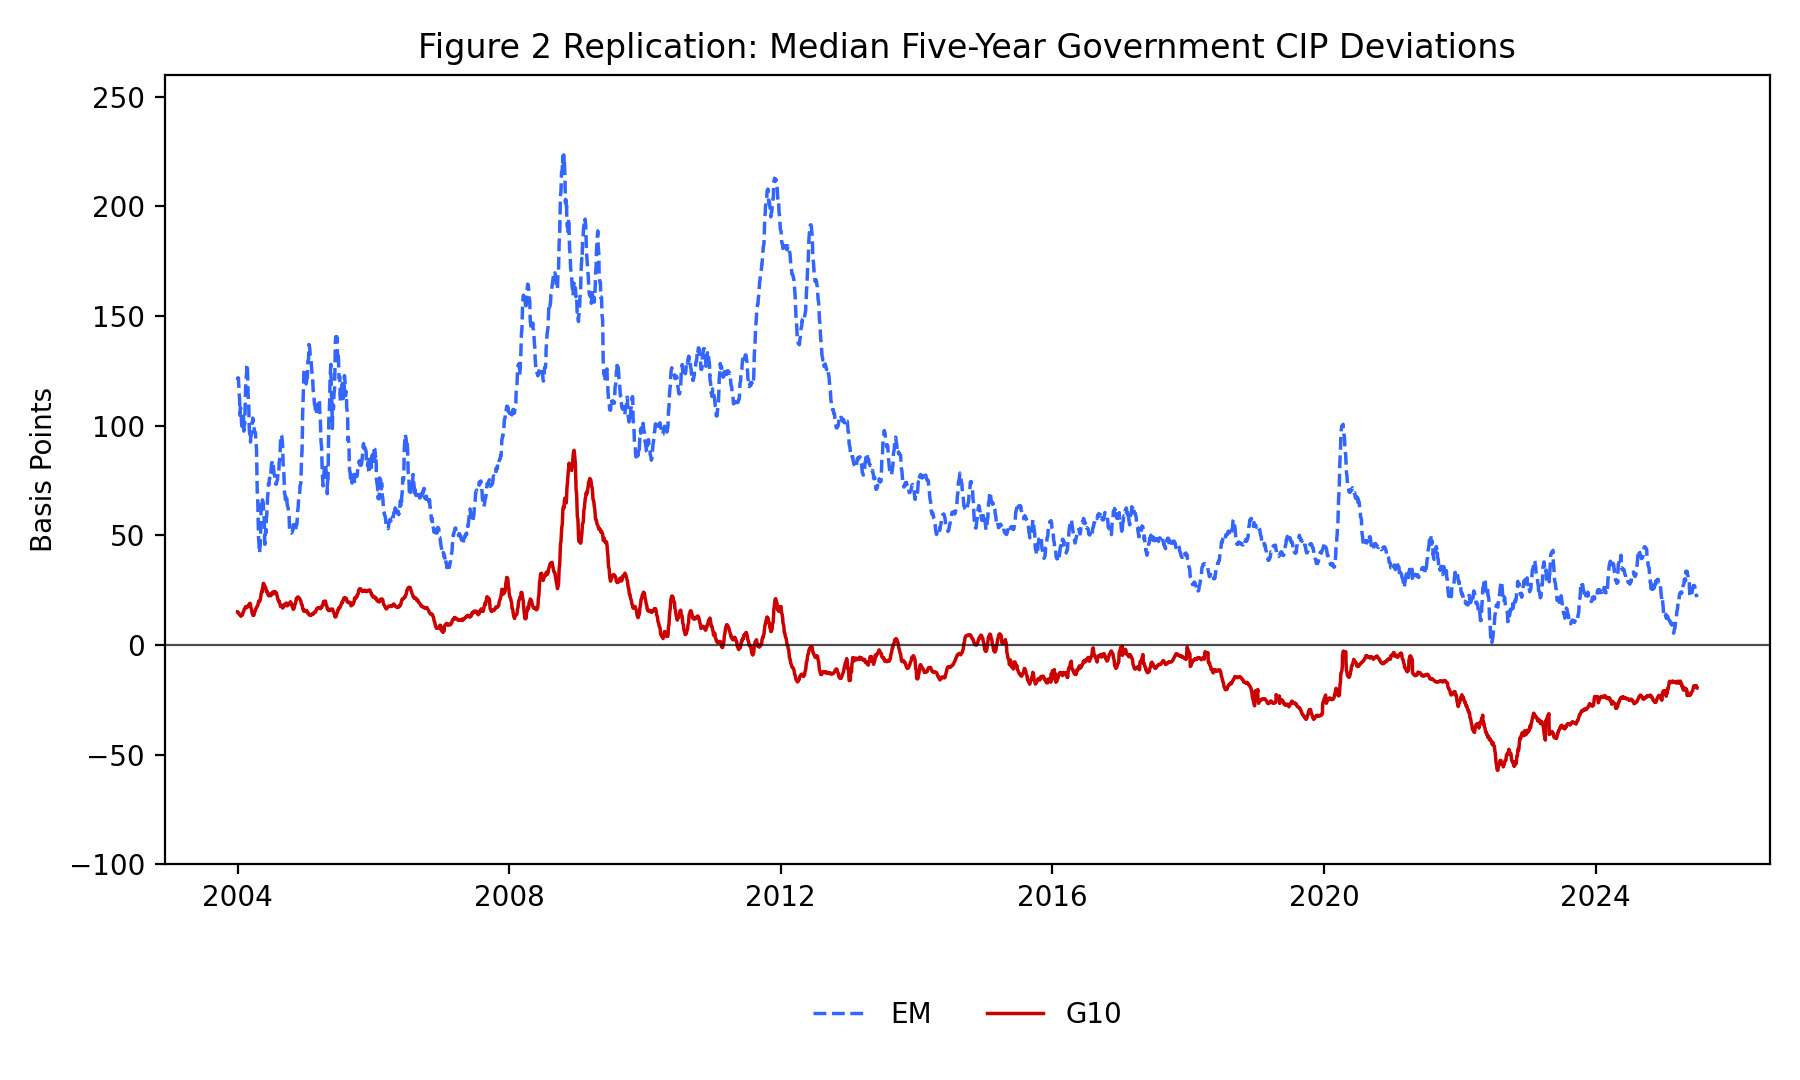

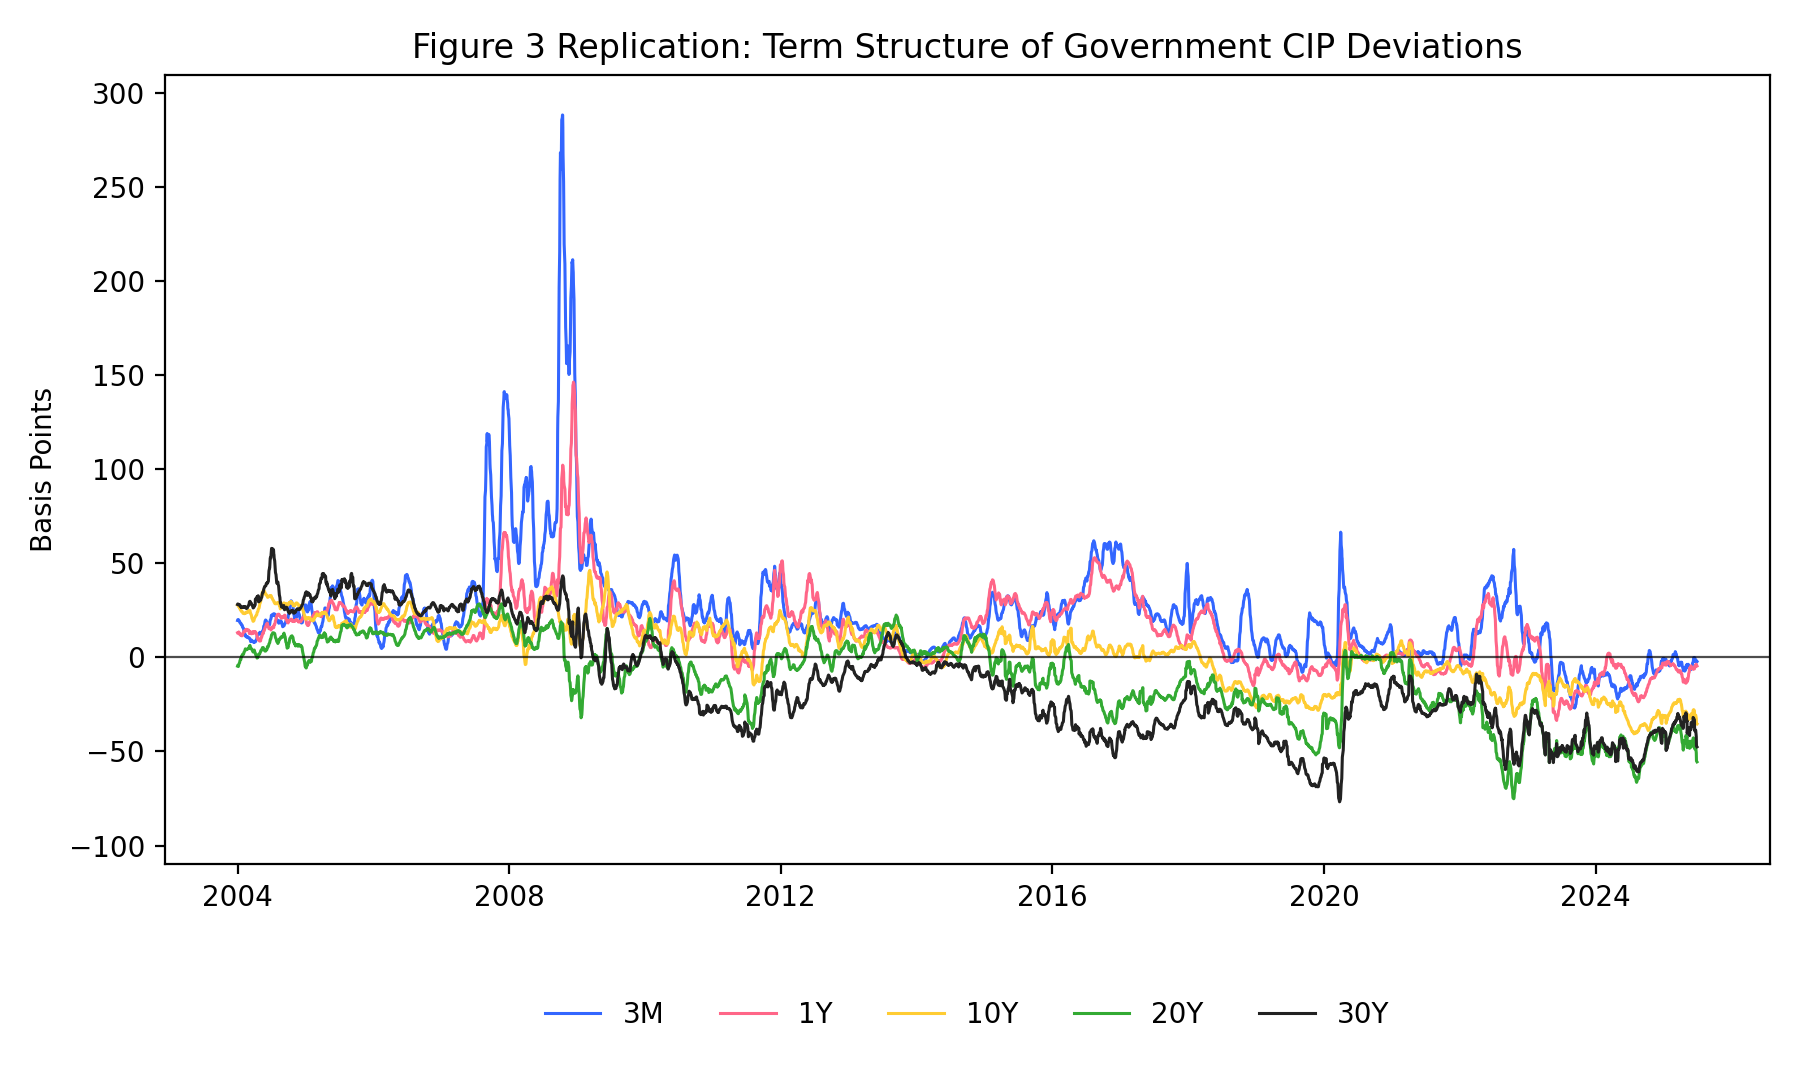

In [8]:
display(Image(filename=str(REPORT_DIR / "replication_figure2_public_exact_spec.png")))
display(Image(filename=str(REPORT_DIR / "replication_figure3_public_exact_spec.png")))


## 8. Raw Replication Stage 1: G10 5Y Government CIP

This is the first completed raw replication anchor.

For each G10 currency, the long-maturity forward premium is reconstructed as:

$$
\rho^{raw} = foreign\_swap + \frac{basis}{100} + tenor\_basis\_adjustment - usd\_swap
$$

Then government CIP is:

$$
cip^{raw}_{govt} = 100 \times (foreign\_govt\_yield - \rho^{raw} - ust\_yield)
$$

Regime handling:

- old world: IBOR/LIBOR-linked swaps and old Bloomberg government-yield curves;
- new world: SOFR/OIS-linked basis where available and Bloomberg BVAL government-yield curves;
- break dates come from the public processed dataset's `cip_govt_break_date`.


In [9]:
from src import replicate_clean_g10_5y

# Re-run the G10 5Y raw reconstruction.
replicate_clean_g10_5y.main()


Raw G10 5Y regime rows: 60398
Raw G10 5Y combined rows: 58722
Comparison:
currency  n_overlap   date_min   date_max     corr  mae_bps  mean_diff_bps  max_abs_diff_bps     status
     AUD       6375 2000-01-03 2025-06-30 0.999438 0.278202      -0.098009         10.739993 GOOD_MATCH
     CAD       6314 2000-02-22 2025-06-30 0.998613 0.405539       0.176017         19.180001 GOOD_MATCH
     CHF       6289 2000-01-19 2025-06-30 0.996033 0.609859      -0.084363         28.599999 GOOD_MATCH
     DKK       4620 2007-01-01 2025-06-30 0.993715 1.306171       0.661902         42.990002 GOOD_MATCH
     EUR       6383 2000-01-07 2025-06-30 0.999077 0.369182      -0.051982         13.059993 GOOD_MATCH
     GBP       6333 2000-01-06 2025-06-30 0.998925 0.361581       0.284488         17.590005 GOOD_MATCH
     JPY       3275 2011-05-05 2025-06-30 0.997822 0.691057      -0.547977         12.379990 GOOD_MATCH
     NOK       4160 2008-09-02 2025-06-30 0.994331 0.906792      -0.325451         38.110006 G

In [10]:
g10_comp = pd.read_csv(TABLE_DIR / "raw_g10_5y_vs_public_comparison.csv")
g10_comp


,currency,n_overlap,date_min,date_max,corr,mae_bps,mean_diff_bps,max_abs_diff_bps,status
0,AUD,6375,2000-01-03,2025-06-30,0.999438,0.278202,-0.098009,10.739993,GOOD_MATCH
1,CAD,6314,2000-02-22,2025-06-30,0.998613,0.405539,0.176017,19.180001,GOOD_MATCH
2,CHF,6289,2000-01-19,2025-06-30,0.996033,0.609859,-0.084363,28.599999,GOOD_MATCH
3,DKK,4620,2007-01-01,2025-06-30,0.993715,1.306171,0.661902,42.990002,GOOD_MATCH
4,EUR,6383,2000-01-07,2025-06-30,0.999077,0.369182,-0.051982,13.059993,GOOD_MATCH
5,GBP,6333,2000-01-06,2025-06-30,0.998925,0.361581,0.284488,17.590005,GOOD_MATCH
6,JPY,3275,2011-05-05,2025-06-30,0.997822,0.691057,-0.547977,12.379990,GOOD_MATCH
7,NOK,4160,2008-09-02,2025-06-30,0.994331,0.906792,-0.325451,38.110006,GOOD_MATCH
8,NZD,6000,2000-01-05,2025-06-30,0.998068,0.495197,0.071165,18.469999,GOOD_MATCH
9,SEK,6279,2000-01-25,2025-06-30,0.998532,0.480341,0.220054,14.430002,GOOD_MATCH


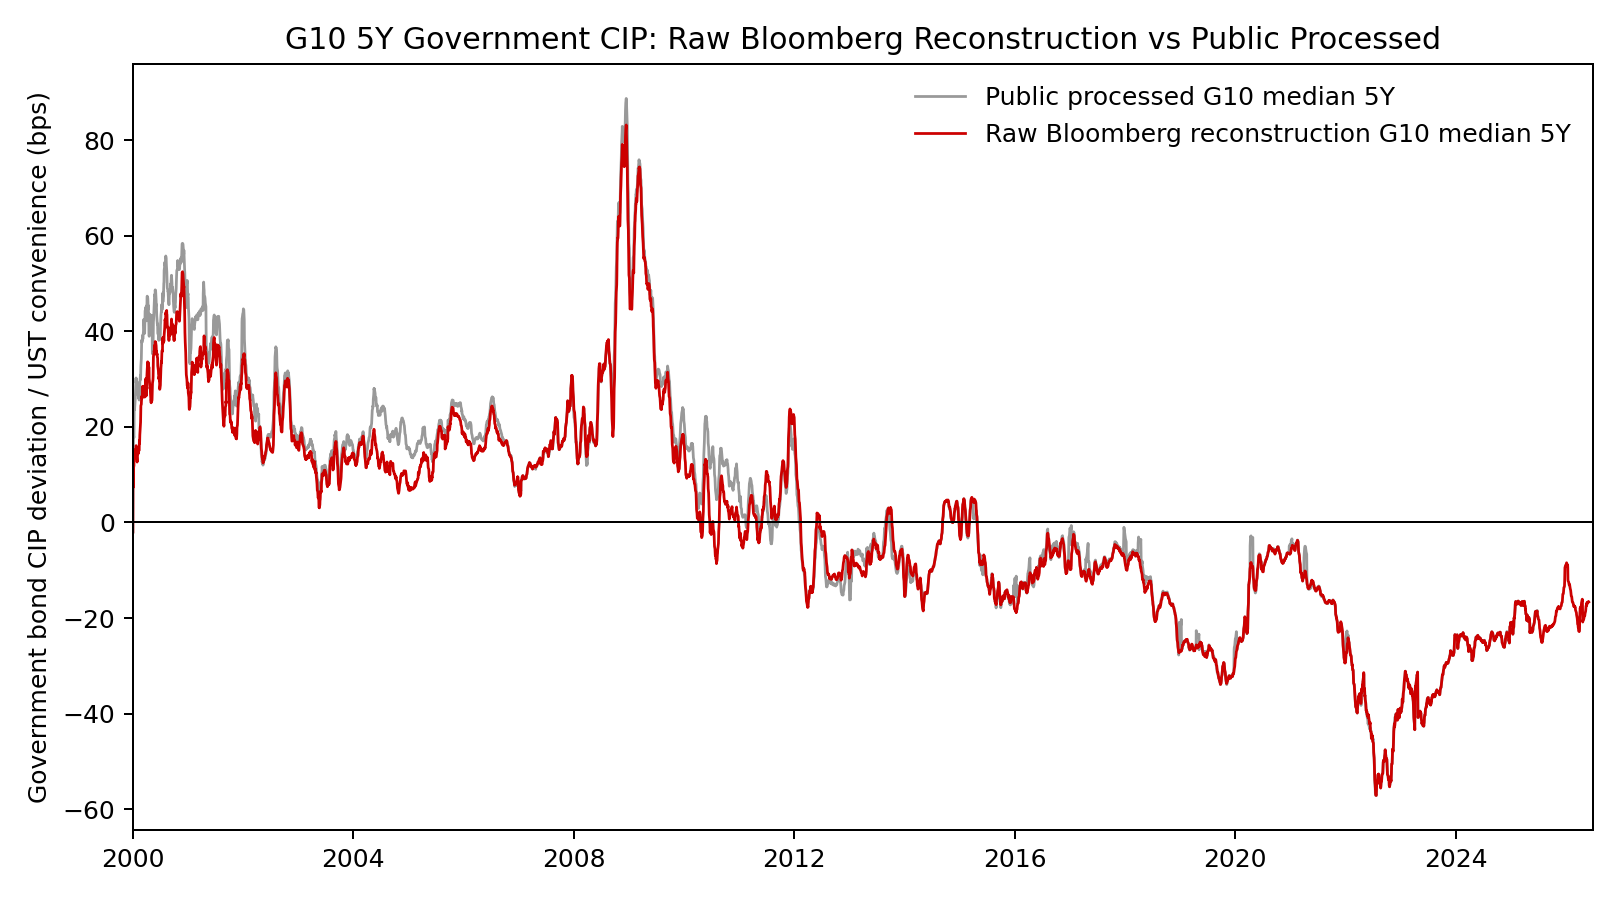

In [11]:
display(Image(filename=str(FIGURE_DIR / "raw_g10_5y_figure2_g10_public_comparison.png")))


### G10 5Y result

The G10 5Y reconstruction is successful:

- all ten G10 currencies pass the match check;
- correlations versus public `cip_govt` are above 0.993;
- mean absolute errors are mostly below 1 bp;
- the raw-reconstructed G10 median tracks the public processed G10 median closely.

This means the raw Bloomberg formula, unit convention, basis convention, and regime break handling are all good enough to use as the foundation for the paper replication.


## 9. Table 2: 5Y Country-Level Summary Statistics

Table 2 summarizes 5Y government-bond CIP by country and period.

The notebook computes:

- mean in basis points;
- Newey-West standard error with 91-day lag;
- sample count $N$.

The raw version below is based on the successful G10 5Y raw reconstruction.


In [12]:
raw_table2 = pd.read_csv(TABLE_DIR / "raw_g10_5y_table2_stats.csv")
raw_table2_pivot = raw_table2.pivot_table(
    index="currency",
    columns="period",
    values=["mean_bps", "nw_se_bps_lag91", "n"],
    aggfunc="first",
)
raw_table2_pivot


mean_bps                                           n            \
period    2000-2006  2010-2020  2021-2025 Full Sample 2000-2006 2010-2020   
currency                                                                    
AUD        7.696637 -40.126924 -45.577957  -24.612881      1745      2799   
CAD       24.150713 -18.362012 -23.438078   -2.630235      1620      2855   
CHF       28.377152  29.177871 -19.755717   22.732193      1609      2854   
DKK             NaN  16.880335 -16.524104   16.530691         0      2856   
EUR       31.834750   3.289471 -35.187293    8.656113      1701      2840   
GBP       12.475886   0.090807 -28.410909    1.941096      1677      2833   
JPY             NaN  62.861458  26.511425   51.135287         0      2249   
NOK             NaN -25.154450 -21.960253  -19.744421         0      2825   
NZD      -15.183747 -40.278142 -28.667613  -29.607215      1305      2858   
SEK       19.271438 -30.650842 -54.872221  -15.060939      1638      2816   

                               nw_se_bps_lag91                                  
period   2021-2025 Full Sample       2000-2006 2010-2020 2021-2025 Full Sample  
currency                                                                        
AUD           1098        6385        3.213880  3.105486  5.260584    3.345074  
CAD           1116        6372        3.254431  2.105584  2.190243    3.146783  
CHF           1092        6334        3.550128  3.490764  5.233173    3.277283  
DKK           1052        4684             NaN  2.327888  3.542391    4.271093  
EUR           1113        6431        2.124964  2.426464  3.979135    3.295121  
GBP           1110        6402        3.960772  3.181917  4.939582    2.980830  
JPY           1071        3320             NaN  4.084314  2.661244    4.035275  
NOK           1065        4229             NaN  3.503199  2.238210    3.389351  
NZD           1096        6041        5.764045  3.204814  5.908162    3.138261  
SEK           1086        6319        1.807264  2.434515  5.160113    3.896001

### Table 2 interpretation

The raw Table 2 is now a genuine raw Bloomberg replication for the G10 5Y country-level series.

Some country sample windows differ from a perfectly balanced 2000-2025 panel because raw availability varies by ticker. Examples:

- DKK starts later for the best-matching 5Y swap convention.
- JPY starts later because some tenor-basis inputs begin later.
- SOFR-period data become available around the benchmark transition window.

This is normal for raw-data work and should be documented in the final report.


## 10. Raw Replication Stage 2: Figure 3 G10 Term Structure

Figure 3 is more complicated because it spans multiple maturities.

Current raw status:

- Included: 1Y, 10Y, 20Y, 30Y.
- Excluded for now: 3M, because Bloomberg 3M forward series appear to be forward points and need exact quote-convention calibration.
- Sample: G10 ex AUD/CAD/NZD, matching the paper figure note.


In [13]:
from src import replicate_clean_figure3_long_tenors

# Re-run the current long-tenor Figure 3 raw reconstruction.
replicate_clean_figure3_long_tenors.main()


WARNING missing NOK 20y ibor: ['nok_ibor_bs_20y_nkbs20', 'nok_common_irs_20y_nksw20', None, 'usd_ibor_irs_20y_ussw20', 'usd_ibor_govt_20y_c08220y']
WARNING missing NOK 30y ibor: ['nok_ibor_bs_30y_nkbs30', 'nok_common_irs_30y_nksw30', None, 'usd_ibor_irs_30y_ussw30', 'usd_ibor_govt_30y_c08230y']


Raw Figure 3 long-tenor regime rows: 145804
Combined rows: 141116
currency tenor  n_overlap   date_min   date_max     corr  mae_bps  mean_diff_bps     status
     CHF   10y       6315 2000-01-07 2025-06-30 0.998104 0.450189  -2.073526e-01 GOOD_MATCH
     CHF    1y       6228 2000-02-01 2025-06-30 0.990139 1.106798   9.952538e-01 GOOD_MATCH
     CHF   20y       6196 2000-02-23 2025-06-30 0.998079 0.500952   4.144596e-01 GOOD_MATCH
     CHF   30y       4015 2005-07-14 2025-06-30 0.998576 0.310306  -1.177934e-01 GOOD_MATCH
     DKK   10y       3956 2005-05-11 2025-06-30 0.992216 0.868250  -4.218661e-02 GOOD_MATCH
     DKK    1y       6141 2000-02-10 2025-06-30 0.985782 0.885550   8.187397e-01 GOOD_MATCH
     DKK   20y       5720 2001-12-04 2025-06-30 0.984710 4.244229  -3.988411e+00 GOOD_MATCH
     DKK   30y       4051 2008-11-14 2025-06-30 0.992720 2.627276   2.316872e+00 GOOD_MATCH
     EUR   10y       6376 2000-01-04 2025-06-30 0.997423 0.608496  -2.640057e-01 GOOD_MATCH
     EUR    1y

In [14]:
fig3_comp = pd.read_csv(TABLE_DIR / "raw_figure3_long_tenors_vs_public_comparison.csv")
fig3_comp


,currency,tenor,n_overlap,date_min,date_max,corr,mae_bps,mean_diff_bps,status
0,CHF,10y,6315,2000-01-07,2025-06-30,0.998104,0.450189,-2.073526e-01,GOOD_MATCH
1,CHF,1y,6228,2000-02-01,2025-06-30,0.990139,1.106798,9.952538e-01,GOOD_MATCH
2,CHF,20y,6196,2000-02-23,2025-06-30,0.998079,0.500952,4.144596e-01,GOOD_MATCH
3,CHF,30y,4015,2005-07-14,2025-06-30,0.998576,0.310306,-1.177934e-01,GOOD_MATCH
4,DKK,10y,3956,2005-05-11,2025-06-30,0.992216,0.868250,-4.218661e-02,GOOD_MATCH
5,DKK,1y,6141,2000-02-10,2025-06-30,0.985782,0.885550,8.187397e-01,GOOD_MATCH
6,DKK,20y,5720,2001-12-04,2025-06-30,0.984710,4.244229,-3.988411e+00,GOOD_MATCH
7,DKK,30y,4051,2008-11-14,2025-06-30,0.992720,2.627276,2.316872e+00,GOOD_MATCH
8,EUR,10y,6376,2000-01-04,2025-06-30,0.997423,0.608496,-2.640057e-01,GOOD_MATCH
9,EUR,1y,6386,2000-01-07,2025-06-30,0.992577,0.705765,4.248461e-01,GOOD_MATCH


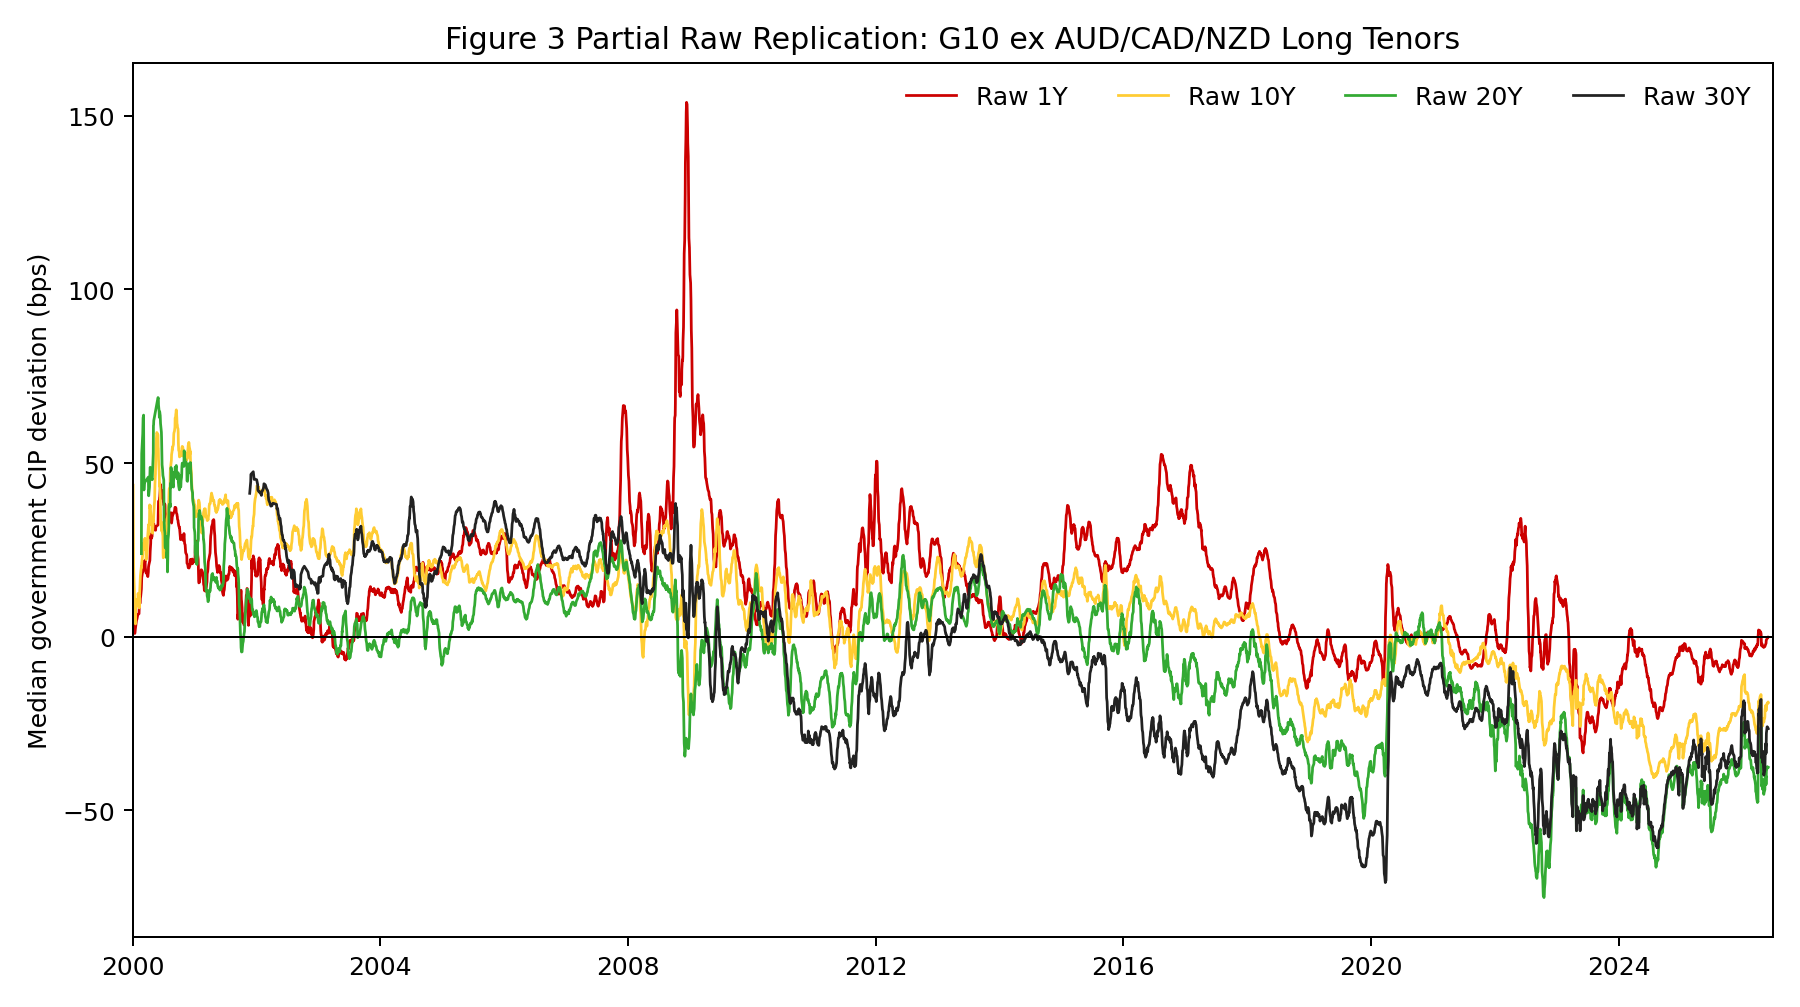

In [15]:
display(Image(filename=str(FIGURE_DIR / "raw_figure3_g10_long_tenors_partial.png")))


### Figure 3 result

The long-tenor Figure 3 replication is mostly successful:

- 25 out of 28 country-tenor pairs are marked `GOOD_MATCH`;
- DKK and SEK improved after treating common IRS tickers as reusable across regimes;
- remaining checks are JPY 20Y, JPY 30Y, and NOK 1Y;
- raw 3M is not included yet because the FX forward-point convention is still unresolved.

This means Figure 3 can be written as a strong partial raw replication, with clear remaining convention checks.


## 11. EM 5Y Status and Diagnostic First Pass

EM raw replication should be staged carefully because the EM file mixes different instrument types:

- standard IRS + basis swap;
- NDS;
- CCS;
- local benchmark rates;
- missing or short-history SOFR replacement series.

The first pass below only uses countries with an identifiable **IBOR IRS + basis swap + government yield** structure. It deliberately excludes NDS/CCS countries for now.


In [16]:
from src import check_em_5y_constructability

check_em_5y_constructability.main()
em_constructability = pd.read_csv(TABLE_DIR / "em_5y_constructability.csv")
em_constructability


currency ibor_available_types  ibor_has_govt  ibor_has_rate_or_irs  ibor_has_basis_ccs_nds ibor_constructability sofr_available_types  sofr_has_govt  sofr_has_rate_or_irs  sofr_has_basis_ccs_nds sofr_constructability no_numeric_tickers
     BRL      Govt, NDS, Rate           True                  True                    True      usable_candidate            NDS, Rate          False                  True                    True          needs_review                   
     CLP  BS, Govt, IRS, Rate           True                  True                    True      usable_candidate             BS, Rate          False                  True                    True          needs_review                   
     CNH            CCS, Govt           True                 False                    True          needs_review                  CCS          False                 False                    True          needs_review      HICNH3M INDEX
     CNY      Govt, NDS, Rate           True            

,currency,ibor_available_types,ibor_has_govt,ibor_has_rate_or_irs,ibor_has_basis_ccs_nds,ibor_constructability,sofr_available_types,sofr_has_govt,sofr_has_rate_or_irs,sofr_has_basis_ccs_nds,sofr_constructability,no_numeric_tickers
0,BRL,"Govt, NDS, Rate",True,True,True,usable_candidate,"NDS, Rate",False,True,True,needs_review,NaN
1,CLP,"BS, Govt, IRS, Rate",True,True,True,usable_candidate,"BS, Rate",False,True,True,needs_review,NaN
2,CNH,"CCS, Govt",True,False,True,needs_review,CCS,False,False,True,needs_review,HICNH3M INDEX
3,CNY,"Govt, NDS, Rate",True,True,True,usable_candidate,"Govt, NDS",True,False,True,needs_review,NaN
4,COP,"Govt, NDS, Rate",True,True,True,usable_candidate,"Govt, NDS",True,False,True,needs_review,NaN
5,HUF,"BS, Govt, IRS, Rate",True,True,True,usable_candidate,"BS, Govt, IRS",True,True,True,usable_candidate,NaN
6,IDR,"Govt, NDS, Rate",True,True,True,usable_candidate,"Govt, NDS",True,False,True,needs_review,NaN
7,ILS,"BS, Govt, IRS, Rate",True,True,True,usable_candidate,Govt,True,False,False,needs_review,ILUS3TSR5Y
8,INR,"Govt, NDS, Rate",True,True,True,usable_candidate,"Govt, NDS",True,False,True,needs_review,NaN
9,KRW,"Govt, NDS, Rate",True,True,True,usable_candidate,"CCS, Govt, IRS, Rate",True,True,True,usable_candidate,NaN


In [17]:
from src import replicate_em_5y_irs_bs_first_pass

replicate_em_5y_irs_bs_first_pass.main()
em_diag = pd.read_csv(TABLE_DIR / "raw_em_5y_irs_bs_diagnostic_comparison.csv")
em_diag


currency  basis_sign  n_overlap   date_min   date_max     corr   mae_bps  mean_diff_bps         basis_variable           swap_variable            govt_variable            status
     HUF           1       3741 2006-10-04 2021-12-31 0.994940 20.897306     -20.545394  huf_ibor_bs_5y_hfebs5   huf_ibor_irs_5y_hfsw5  huf_ibor_govt_5y_c1145y            REVIEW
     MXN          -1       4486 2003-11-05 2022-03-28 0.951555  9.515376       8.296095  mxn_ibor_bs_5y_mpbs5e  mxn_ibor_irs_5y_mpsw5e  mxn_ibor_govt_5y_c4765y            REVIEW
     PLN           1       3898 2005-03-18 2021-12-31 0.978137 19.408876     -18.728597 pln_ibor_bs_5y_pzbsec5   pln_ibor_irs_5y_pzsw5  pln_ibor_govt_5y_c1195y            REVIEW
     CLP          -1       2437 2007-11-27 2017-08-01 0.993636  9.704781       9.417026 clp_ibor_bs_5y_chusbs5  clp_ibor_irs_5y_chswp5  clp_ibor_govt_5y_c9905y USABLE_DIAGNOSTIC
     THB           1       3857 2006-11-22 2022-03-23 0.992746 10.402285     -10.375428   thb_ibor_bs_5y_tbbs5

,currency,basis_sign,n_overlap,date_min,date_max,corr,mae_bps,mean_diff_bps,basis_variable,swap_variable,govt_variable,status
0,HUF,1,3741,2006-10-04,2021-12-31,0.994940,20.897306,-20.545394,huf_ibor_bs_5y_hfebs5,huf_ibor_irs_5y_hfsw5,huf_ibor_govt_5y_c1145y,REVIEW
1,MXN,-1,4486,2003-11-05,2022-03-28,0.951555,9.515376,8.296095,mxn_ibor_bs_5y_mpbs5e,mxn_ibor_irs_5y_mpsw5e,mxn_ibor_govt_5y_c4765y,REVIEW
2,PLN,1,3898,2005-03-18,2021-12-31,0.978137,19.408876,-18.728597,pln_ibor_bs_5y_pzbsec5,pln_ibor_irs_5y_pzsw5,pln_ibor_govt_5y_c1195y,REVIEW
3,CLP,-1,2437,2007-11-27,2017-08-01,0.993636,9.704781,9.417026,clp_ibor_bs_5y_chusbs5,clp_ibor_irs_5y_chswp5,clp_ibor_govt_5y_c9905y,USABLE_DIAGNOSTIC
4,THB,1,3857,2006-11-22,2022-03-23,0.992746,10.402285,-10.375428,thb_ibor_bs_5y_tbbs5,thb_ibor_irs_5y_tbswni5,thb_ibor_govt_5y_c1225y,USABLE_DIAGNOSTIC
5,ILS,1,3835,2006-02-10,2022-06-08,0.993378,2.755569,1.312138,ils_ibor_bs_5y_isbs5,ils_ibor_irs_5y_issw5,ils_ibor_govt_5y_i32505y,VALIDATED
6,MYR,1,3546,2007-01-03,2022-03-07,0.999430,0.712552,0.430406,myr_ibor_bs_5y_mrbs5,myr_ibor_irs_5y_mrswni5,myr_ibor_govt_5y_c1285y,VALIDATED


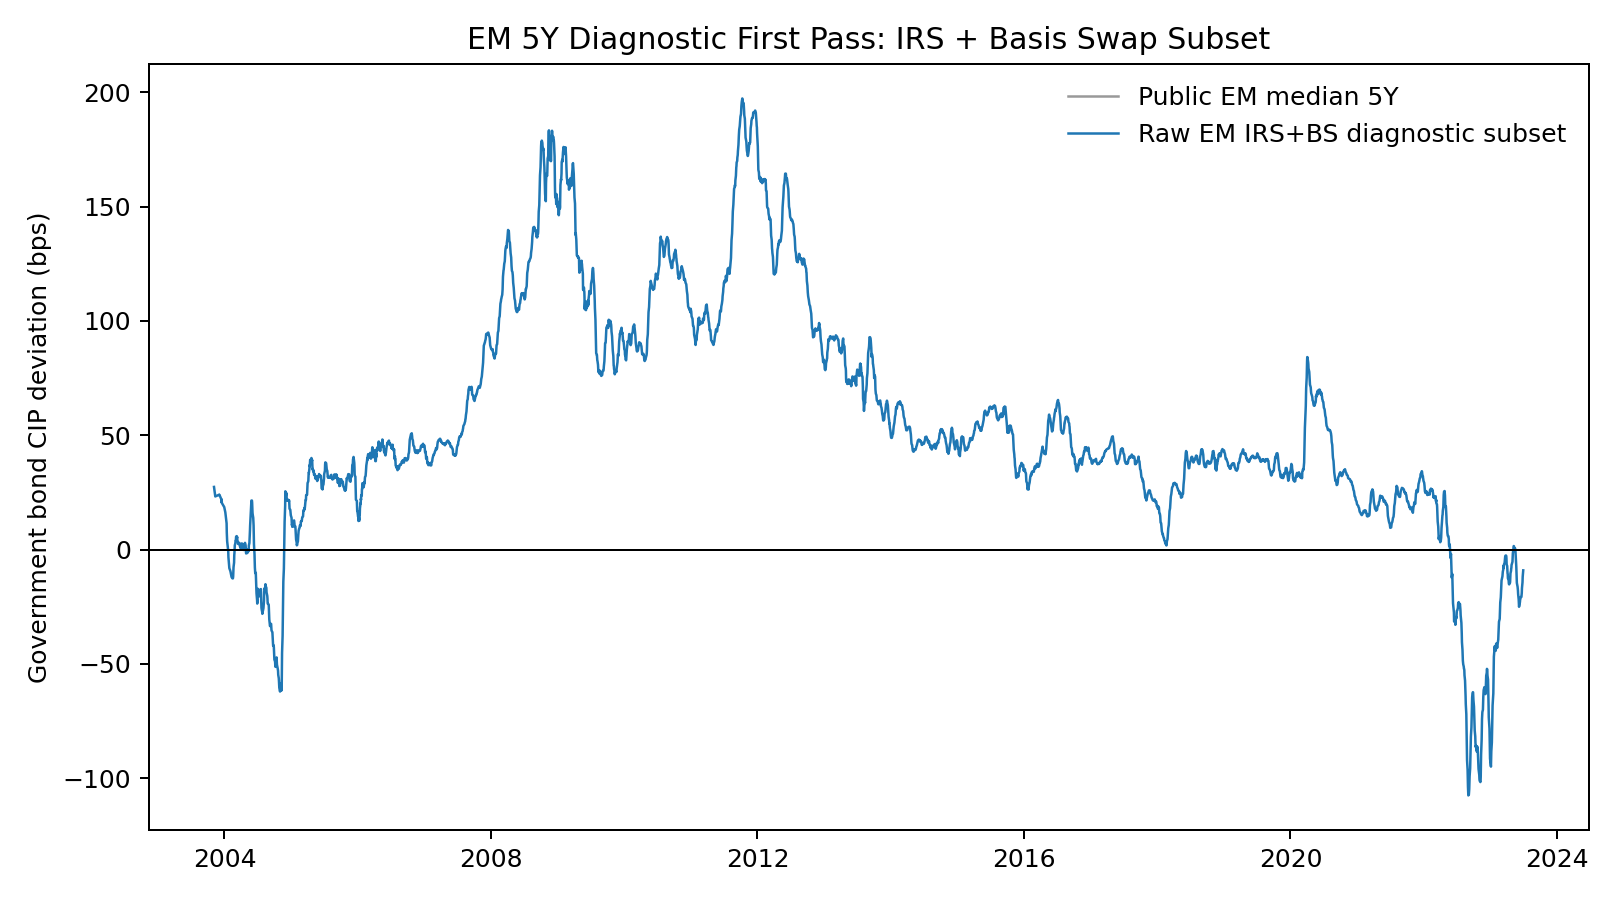

In [18]:
display(Image(filename=str(FIGURE_DIR / "raw_em_5y_irs_bs_diagnostic_subset.png")))


### EM diagnostic interpretation

The EM first pass is useful but not final:

- `VALIDATED` means MAE below 3 bps, correlation above 0.99, and more than 1,000 overlapping observations.
- `USABLE_DIAGNOSTIC` means high correlation and MAE up to 12 bps; useful for direction, not final.
- `REVIEW` means larger level error, weak overlap, or unstable convention.
- CLP and MXN still require reversed basis signs, suggesting country-specific quoting conventions.

The next EM step should be to build country-specific formula rules from the Data Appendix / ticker supplement instead of applying one generic G10-style formula.


## 12. Benchmark CIP and Equation 6: First-Pass Raw Replication

The G10 benchmark / Equation 6 workbook has been downloaded and passed file-level QC. This section now implements the first G10 5Y/10Y raw replication of:

1. benchmark CIP / dollar convenience $x^{Rf}$;
2. government CIP / Treasury convenience $x^{Govt}$;
3. U.S. swap spread;
4. foreign swap spread;
5. Equation 6 decomposition.

Scope for this pass:

- G10 currencies only;
- 5Y and 10Y only;
- old IBOR and new SOFR/OIS regimes where raw legs exist;
- no 3M because FX forward-point conventions are not fully calibrated;
- no EM because EM requires instrument-class-specific formulas.

This is central for the paper's main claim because it directly separates dollar privilege from Treasury privilege.


In [19]:
eq6_cov = coverage[coverage["workbook"].eq("g10_benchmark_eq6")].copy()
eq6_by_type = eq6_cov.groupby(["sheet", "type", "tenor"], dropna=False).agg(
    tickers=("ticker", "count"),
    numeric_blocks=("n_numeric", lambda x: int((x.fillna(0) > 0).sum())),
    first_valid=("first_valid_date", "min"),
    last_valid=("last_valid_date", "max"),
).reset_index()
eq6_by_type.head(40)


,sheet,type,tenor,tickers,numeric_blocks,first_valid,last_valid
0,AUD,BS,10y,2,2,2000-01-03,2026-06-03
1,AUD,BS,1y,2,2,2000-01-03,2026-06-03
2,AUD,BS,5y,2,2,2000-01-03,2026-06-03
3,AUD,Forward,3m,1,1,2000-01-03,2026-06-03
4,AUD,Govt,10y,2,2,2000-01-03,2026-06-03
5,AUD,Govt,1y,2,2,2000-01-03,2026-06-03
6,AUD,Govt,3m,2,2,2000-01-03,2026-06-03
7,AUD,Govt,5y,2,2,2000-01-03,2026-06-03
8,AUD,IRS,10y,2,2,2000-01-03,2026-06-03
9,AUD,IRS,1y,3,3,2000-01-03,2026-06-03


### Raw formulas

For each country, tenor, and date:

$$
\rho^{raw} = foreign\_swap + \frac{basis}{100} + tenor\_basis\_adjustment - usd\_swap
$$

$$
x^{Rf,raw}_{bps} = 100 \times (foreign\_swap - \rho^{raw} - usd\_swap)
$$

$$
x^{Govt,raw}_{bps} = 100 \times (foreign\_govt\_yield - \rho^{raw} - usd\_govt\_yield)
$$

$$
US\ swap\ spread = 100 \times (usd\_swap - usd\_govt\_yield)
$$

$$
Foreign\ swap\ spread = 100 \times (foreign\_swap - foreign\_govt\_yield)
$$

$$
Eq6\ residual = x^{Govt,raw} - (x^{Rf,raw} + US\ swap\ spread - Foreign\ swap\ spread)
$$

`x_rf_raw_bps` is a first raw dollar-convenience proxy. The public processed CSV has no complete `x_rf` column. Eq.6 is an internal accounting check, not independent validation of that proxy; public checks cover `rho_raw` and `x_govt_raw_bps` only.


In [20]:
from src import replicate_benchmark_eq6_g10_5y10y

replicate_benchmark_eq6_g10_5y10y.main()


Raw G10 benchmark / Eq.6 panel rows: 122037
Eq.6 residual MAE max: 2.4759044403827126e-14
Combined government-CIP checks: {'GOOD_MATCH': 20}
Benchmark CIP figure: ./output/figures/raw_g10_5y_benchmark_cip_median.png
Equation 6 decomposition figure: ./output/figures/raw_g10_5y_eq6_decomposition_median.png


In [21]:
eq6_validation = pd.read_csv(TABLE_DIR / "raw_g10_benchmark_eq6_5y10y_validation.csv")
eq6_summary = pd.read_csv(TABLE_DIR / "raw_g10_benchmark_eq6_5y10y_component_summary.csv")

display(
    eq6_validation.groupby(["check_type", "status"]).size().reset_index(name="count")
)

display(
    eq6_validation[eq6_validation["check_type"].eq("x_govt_vs_public_combined")][
        ["currency", "tenor", "status", "n_overlap", "corr", "mae_bps", "max_abs_diff_bps"]
    ].sort_values(["tenor", "currency"])
)


,check_type,status,count
0,eq6_identity_residual,IDENTITY_OK,40
1,rho_vs_public_combined,DIAGNOSTIC_GOOD,20
2,rho_vs_public_regime,DIAGNOSTIC_GOOD,40
3,x_govt_vs_public_combined,GOOD_MATCH,20
4,x_govt_vs_public_regime,CHECK,1
5,x_govt_vs_public_regime,GOOD_MATCH,39


,currency,tenor,status,n_overlap,corr,mae_bps,max_abs_diff_bps
0,AUD,10y,GOOD_MATCH,6300,0.998175,0.713840,25.870003
4,CAD,10y,GOOD_MATCH,6314,0.997432,0.633647,24.769984
8,CHF,10y,GOOD_MATCH,6315,0.998104,0.450189,15.959988
12,DKK,10y,GOOD_MATCH,6234,0.995185,1.004598,54.820011
16,EUR,10y,GOOD_MATCH,6376,0.997423,0.608496,19.459996
20,GBP,10y,GOOD_MATCH,6331,0.998048,0.416392,14.355000
24,JPY,10y,GOOD_MATCH,3315,0.990624,0.885257,29.269988
28,NOK,10y,GOOD_MATCH,2295,0.995665,0.940630,19.509998
32,NZD,10y,GOOD_MATCH,5995,0.994492,0.912837,76.831017
36,SEK,10y,GOOD_MATCH,6258,0.998647,0.666589,18.700023


In [22]:
identity_checks = eq6_validation[eq6_validation["check_type"].eq("eq6_identity_residual")]
print("Max Eq.6 residual MAE, bps:", identity_checks["mae_bps"].max())
print("Max Eq.6 residual absolute error, bps:", identity_checks["max_abs_diff_bps"].max())

display(
    eq6_summary[
        [
            "currency", "tenor", "regime", "n", "date_min", "date_max",
            "x_rf_raw_bps_mean", "x_govt_raw_bps_mean",
            "eq6_residual_abs_mean_bps", "eq6_residual_abs_max_bps",
        ]
    ].sort_values(["tenor", "currency", "regime"]).head(40)
)


Max Eq.6 residual MAE, bps: 2.475904440382713e-14
Max Eq.6 residual absolute error, bps: 1.1368683772161605e-13


,currency,tenor,regime,n,date_min,date_max,x_rf_raw_bps_mean,x_govt_raw_bps_mean,eq6_residual_abs_mean_bps,eq6_residual_abs_max_bps
0,AUD,10y,ibor,5612,2000-01-03,2022-07-26,-19.446622,-28.249683,2.865531e-15,4.440892e-14
1,AUD,10y,sofr,1127,2021-10-05,2026-06-03,-9.118801,-53.946752,3.612609e-15,5.684342e-14
4,CAD,10y,ibor,5660,2000-02-22,2022-07-26,-5.894355,-13.487799,3.837056e-15,8.526513e-14
5,CAD,10y,sofr,974,2022-06-06,2026-06-03,2.956949,-28.514277,1.174146e-14,9.947598e-14
8,CHF,10y,ibor,5503,2000-01-07,2021-12-31,23.348230,22.665897,2.116198e-14,1.030287e-13
9,CHF,10y,sofr,1194,2021-06-17,2026-06-03,44.298189,-28.565769,2.083872e-14,9.237056e-14
12,DKK,10y,ibor,5573,2000-01-26,2022-03-16,25.280177,18.298641,1.168545e-14,9.947598e-14
13,DKK,10y,sofr,1053,2021-10-27,2026-06-03,47.845801,-28.516323,2.062969e-14,9.947598e-14
16,EUR,10y,ibor,5569,2000-01-04,2021-12-31,13.974195,10.156745,1.105981e-14,9.947598e-14
17,EUR,10y,sofr,1292,2021-02-23,2026-06-03,16.875515,-35.827641,1.304220e-14,9.237056e-14


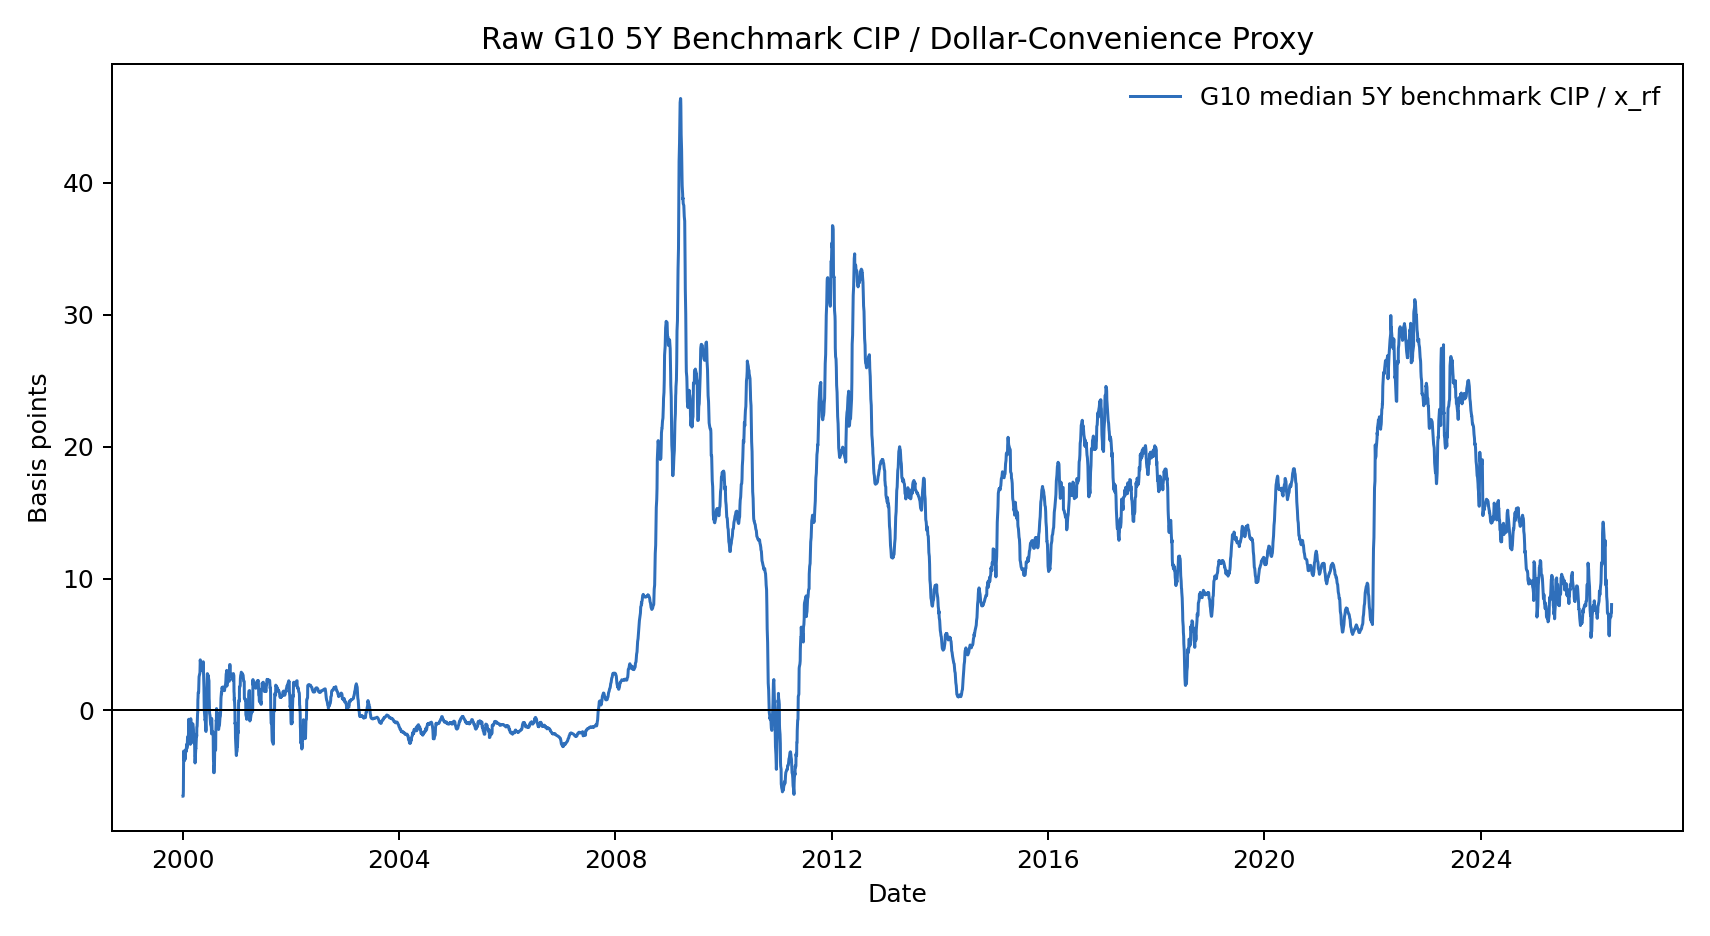

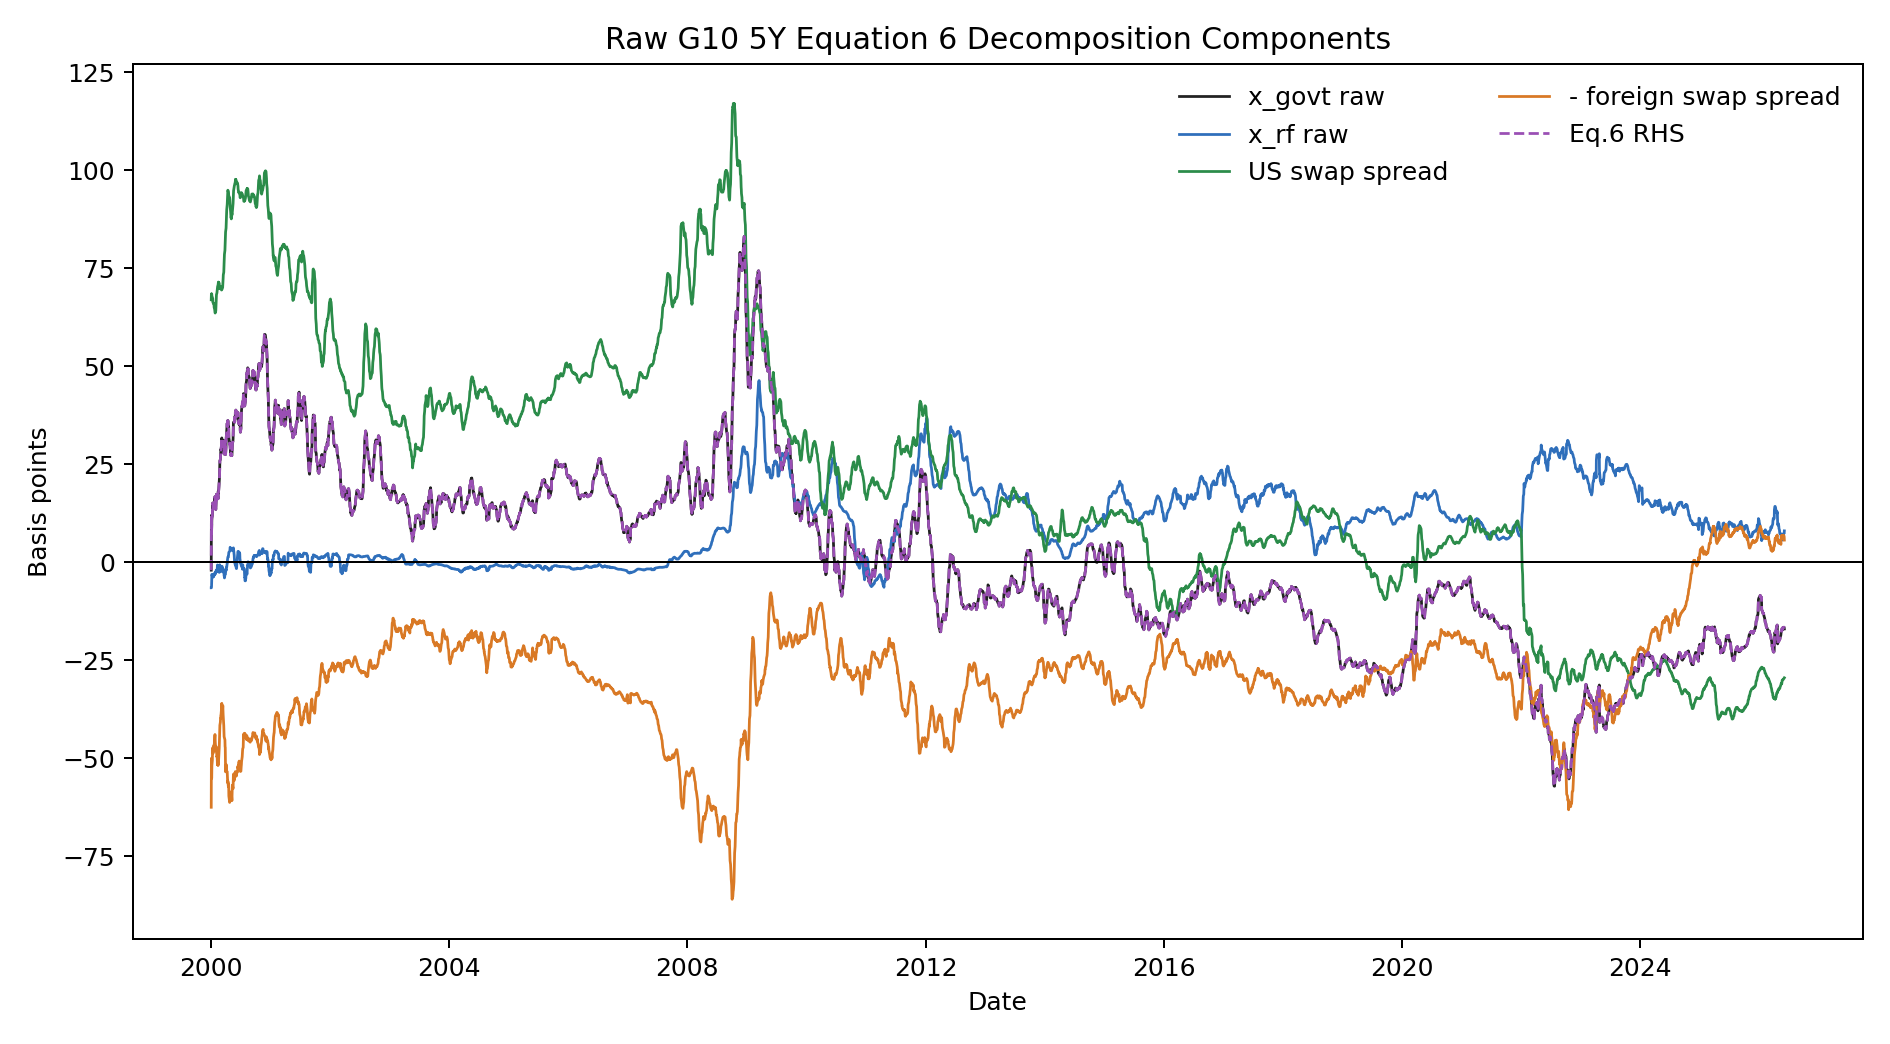

In [23]:
display(Image(filename=str(FIGURE_DIR / "raw_g10_5y_benchmark_cip_median.png")))
display(Image(filename=str(FIGURE_DIR / "raw_g10_5y_eq6_decomposition_median.png")))


### Equation 1 / Equation 6 first-pass interpretation

The first-pass G10 5Y/10Y implementation is successful as a raw-data construction check:

- `x_govt_raw_bps` matches public processed `cip_govt` for all 20 selected G10 currency-tenor series.
- `rho_raw_bps` matches public processed `rho` diagnostically for all 20 selected G10 currency-tenor series.
- Equation 6 residual is effectively zero because both sides use the same raw legs.
- `x_rf_raw_bps` is internally consistent, but is not independently validated by the same-leg identity or a direct public benchmark-CIP comparison.

Remaining convention notes:

- JPY SOFR previously inherited an obsolete LIBOR tenor-basis adjustment. TONA needs no such adjustment: this was corrected on 2026-10-02, restoring post-2021 coverage; JPY SOFR government-CIP MAE is now about 0.00001 bps over the public overlap.
- DKK 5Y SOFR regime-only check has correlation just below the strict threshold, but the combined series passes.
- These are first-pass convention notes, not blockers for the G10 5Y/10Y selected-regime replication.


## 13. Macro, Liquidity, and Dealer-Capacity Extension

After the convenience series are stable, the extension can ask whether Treasury convenience is related to:

- U.S. public debt supply;
- debt-to-GDP;
- VIX and broad dollar strength;
- Treasury market liquidity;
- dealer balance-sheet capacity;
- repo / SOFR stress measures.

This is where the project moves from replication to contribution.


In [24]:
macro_liquidity_cov = coverage[
    coverage["workbook"].isin(["macro_controls", "treasury_liquidity_dealer"])
].copy()
macro_liquidity_cov[[
    "workbook", "sheet", "ticker", "variable", "type", "status",
    "first_valid_date", "last_valid_date", "n_numeric"
]].head(80)


,workbook,sheet,ticker,variable,type,status,first_valid_date,last_valid_date,n_numeric
717,macro_controls,Dollar,BBDXY Index,bbdxy_index,NaN,OK,2004-12-31,2026-06-03,5478
718,macro_controls,Dollar,DXY Curncy,dxy_currency_index,NaN,OK,2000-01-03,2026-06-03,6864
719,macro_controls,Risk_Indexes,MOVE Index,move_index,NaN,OK,2000-01-03,2026-06-03,6805
720,macro_controls,Risk_Indexes,VIX Index,vix_index,NaN,OK,2000-01-03,2026-06-03,6674
721,macro_controls,UST_Yields,USGG10YR Index,us_generic_govt_10y_yield,NaN,OK,2000-01-03,2026-06-03,6887
722,macro_controls,UST_Yields,USGG2YR Index,us_generic_govt_2y_yield,NaN,OK,2000-01-03,2026-06-03,6887
723,macro_controls,UST_Yields,USGG30YR Index,us_generic_govt_30y_yield,NaN,OK,2000-01-03,2026-06-03,6886
724,macro_controls,UST_Yields,USGG5YR Index,us_generic_govt_5y_yield,NaN,OK,2000-01-03,2026-06-03,6887
725,treasury_liquidity_dealer,Generic_UST,USGG10YR Index,usgg10yr_px_last,NaN,OK,2000-01-03,2026-06-03,6887
726,treasury_liquidity_dealer,Generic_UST,USGG2YR Index,usgg2yr_px_last,NaN,OK,2000-01-03,2026-06-03,6887


## 14. Eq.5 UST-Convenience Extension First Pass

**Historical exploratory layer. Section 15 supersedes this layer for conclusions and statistical inference.** These legacy models use changing currency composition and less conservative break/HAC treatment; their coefficients must not be quoted as reviewed evidence.

Following Samim's guidance, this step treats Eq.5 direct UST convenience as the main dependent variable where it is already validated: G10 5Y and 10Y.

The extension now has two first-pass layers:

1. available market controls: MOVE, VIX, broad dollar index, U.S. Treasury yields, slope, and generic bid-ask proxies;
2. broad fiscal supply proxies from FRED: federal debt-to-GDP and total federal debt.
3. official supply / intermediation proxies: Treasury FiscalData marketable Treasury outstanding and NY Fed Primary Dealer Statistics.

Important caveat: even the official supply/dealer section is still first-pass and exploratory. It improves the data source substantially, but it does not by itself solve persistence, causality, or series-break issues.


In [25]:
from src import (
    analyze_eq5_ust_extension_first_pass,
    analyze_eq5_supply_extension,
    analyze_eq5_supply_dealer_official,
    analyze_eq5_supply_dealer_robustness,
)

analyze_eq5_ust_extension_first_pass.main()
analyze_eq5_supply_extension.main()
analyze_eq5_supply_dealer_official.main()
analyze_eq5_supply_dealer_robustness.main()


./output/cleaned/eq5_ust_extension_monthly_panel.csv
./output/tables/eq5_ust_extension_correlation_table.csv
./output/tables/eq5_ust_extension_regression_coefficients.csv
./output/tables/eq5_ust_extension_regression_models.csv
./output/tables/eq5_ust_extension_data_gaps.csv
./output/figures/eq5_ust_extension_monthly_timeseries.png
./output/figures/eq5_ust_extension_control_scatter.png
./output/report/Eq5_UST_Extension_First_Pass.md
./output/cleaned/eq5_ust_supply_extension_monthly_panel.csv
./output/tables/eq5_ust_supply_extension_correlations.csv
./output/tables/eq5_ust_supply_extension_regression_coefficients.csv
./output/tables/eq5_ust_supply_extension_regression_models.csv
./output/figures/eq5_ust_supply_extension.png
./output/report/Eq5_UST_Supply_Extension_First_Pass.md


./output/cleaned/eq5_ust_supply_dealer_official_monthly_panel.csv
./output/tables/eq5_supply_dealer_official_variable_coverage.csv
./output/tables/eq5_supply_dealer_official_correlations.csv
./output/tables/eq5_supply_dealer_official_regression_models.csv
./output/tables/eq5_supply_dealer_official_regression_coefficients.csv
./output/figures/eq5_supply_dealer_official_first_pass.png
./output/report/Eq5_Official_Supply_Dealer_Extension_First_Pass.md


./output/tables/eq5_supply_dealer_robustness_correlation_modes.csv
./output/tables/eq5_supply_dealer_robustness_regression_models.csv
./output/tables/eq5_supply_dealer_robustness_regression_coefficients.csv
./output/tables/nyfed_primary_dealer_seriesbreak_coverage.csv
./output/tables/eq5_supply_dealer_reporting_break_dummy_models.csv
./output/tables/eq5_supply_dealer_reporting_break_dummy_coefficients.csv
./output/tables/eq5_supply_dealer_within_break_diagnostics.csv
./output/figures/eq5_supply_dealer_robustness_checks.png
./output/figures/eq5_supply_dealer_reporting_break_checks.png
./output/report/Eq5_Supply_Dealer_Robustness_Memo.md


In [26]:
extension_models = pd.read_csv(TABLE_DIR / "eq5_ust_extension_regression_models.csv")
supply_models = pd.read_csv(TABLE_DIR / "eq5_ust_supply_extension_regression_models.csv")
supply_coefs = pd.read_csv(TABLE_DIR / "eq5_ust_supply_extension_regression_coefficients.csv")
supply_corr = pd.read_csv(TABLE_DIR / "eq5_ust_supply_extension_correlations.csv")

display(extension_models)
display(supply_models)
display(
    supply_coefs[
        supply_coefs["variable"].str.contains("debt", na=False)
    ][["target", "spec", "variable", "coef_bps_per_1sd", "t_stat_hac", "n_months", "r_squared"]]
)
display(supply_corr)


,target,transform,spec,n_months,date_min,date_max,r_squared,adj_r_squared
0,x_govt_raw_bps_5y,level,volatility,318,2000-01-31,2026-06-30,0.170095,0.164825
1,x_govt_raw_bps_5y,level,dollar_rates,259,2004-12-31,2026-06-30,0.484001,0.477930
2,x_govt_raw_bps_5y,level,liquidity_candidates,318,2000-01-31,2026-06-30,0.396666,0.390902
3,x_govt_raw_bps_5y,level,combined,259,2004-12-31,2026-06-30,0.638558,0.629953
4,x_govt_raw_bps_5y,change,volatility,317,2000-02-29,2026-06-30,0.074817,0.068924
5,x_govt_raw_bps_5y,change,dollar_rates,258,2005-01-31,2026-06-30,0.077957,0.067067
6,x_govt_raw_bps_5y,change,liquidity_candidates,317,2000-02-29,2026-06-30,0.042392,0.033213
7,x_govt_raw_bps_5y,change,combined,258,2005-01-31,2026-06-30,0.114519,0.093352
8,x_govt_raw_bps_10y,level,volatility,318,2000-01-31,2026-06-30,0.052582,0.046566
9,x_govt_raw_bps_10y,level,dollar_rates,259,2004-12-31,2026-06-30,0.314087,0.306018


,target,spec,n_months,date_min,date_max,r_squared,adj_r_squared
0,x_govt_raw_bps_5y,supply_only_level,318,2000-01-31,2026-06-30,0.675889,0.674864
1,x_govt_raw_bps_5y,supply_plus_controls_level,259,2004-12-31,2026-06-30,0.784765,0.779640
2,x_govt_raw_bps_5y,supply_only_12m_change,306,2001-01-31,2026-06-30,0.053923,0.050810
3,x_govt_raw_bps_5y,supply_plus_controls_12m_change,247,2005-12-31,2026-06-30,0.338577,0.322041
4,x_govt_raw_bps_10y,supply_only_level,318,2000-01-31,2026-06-30,0.698360,0.697405
5,x_govt_raw_bps_10y,supply_plus_controls_level,259,2004-12-31,2026-06-30,0.627070,0.618191
6,x_govt_raw_bps_10y,supply_only_12m_change,306,2001-01-31,2026-06-30,0.060627,0.057537
7,x_govt_raw_bps_10y,supply_plus_controls_12m_change,247,2005-12-31,2026-06-30,0.101657,0.079198


,target,spec,variable,coef_bps_per_1sd,t_stat_hac,n_months,r_squared
0,x_govt_raw_bps_5y,supply_only_level,federal_debt_to_gdp_pct,-19.133517,-11.380120,318,0.675889
1,x_govt_raw_bps_5y,supply_plus_controls_level,federal_debt_to_gdp_pct,-17.929702,-5.910690,259,0.784765
7,x_govt_raw_bps_5y,supply_only_12m_change,federal_debt_to_gdp_change_12m,3.802123,1.595453,306,0.053923
8,x_govt_raw_bps_5y,supply_plus_controls_12m_change,federal_debt_to_gdp_change_12m,-0.405164,-0.180794,247,0.338577
14,x_govt_raw_bps_10y,supply_only_level,federal_debt_to_gdp_pct,-18.251482,-11.526032,318,0.698360
15,x_govt_raw_bps_10y,supply_plus_controls_level,federal_debt_to_gdp_pct,-17.127811,-6.061611,259,0.627070
21,x_govt_raw_bps_10y,supply_only_12m_change,federal_debt_to_gdp_change_12m,3.527575,2.263362,306,0.060627
22,x_govt_raw_bps_10y,supply_plus_controls_12m_change,federal_debt_to_gdp_change_12m,2.519731,1.418274,247,0.101657


,target,supply_proxy,n_months,date_min,date_max,level_corr
0,x_govt_raw_bps_5y,federal_debt_to_gdp_pct,318,2000-01-31,2026-06-30,-0.822125
1,x_govt_raw_bps_5y,federal_debt_total_millions,318,2000-01-31,2026-06-30,-0.812285
2,x_govt_raw_bps_5y,federal_debt_to_gdp_change_12m,306,2001-01-31,2026-06-30,0.257484
3,x_govt_raw_bps_5y,federal_debt_total_growth_12m_pct,306,2001-01-31,2026-06-30,0.253131
4,x_govt_raw_bps_10y,federal_debt_to_gdp_pct,318,2000-01-31,2026-06-30,-0.835679
5,x_govt_raw_bps_10y,federal_debt_total_millions,318,2000-01-31,2026-06-30,-0.810750
6,x_govt_raw_bps_10y,federal_debt_to_gdp_change_12m,306,2001-01-31,2026-06-30,0.067283
7,x_govt_raw_bps_10y,federal_debt_total_growth_12m_pct,306,2001-01-31,2026-06-30,0.008792


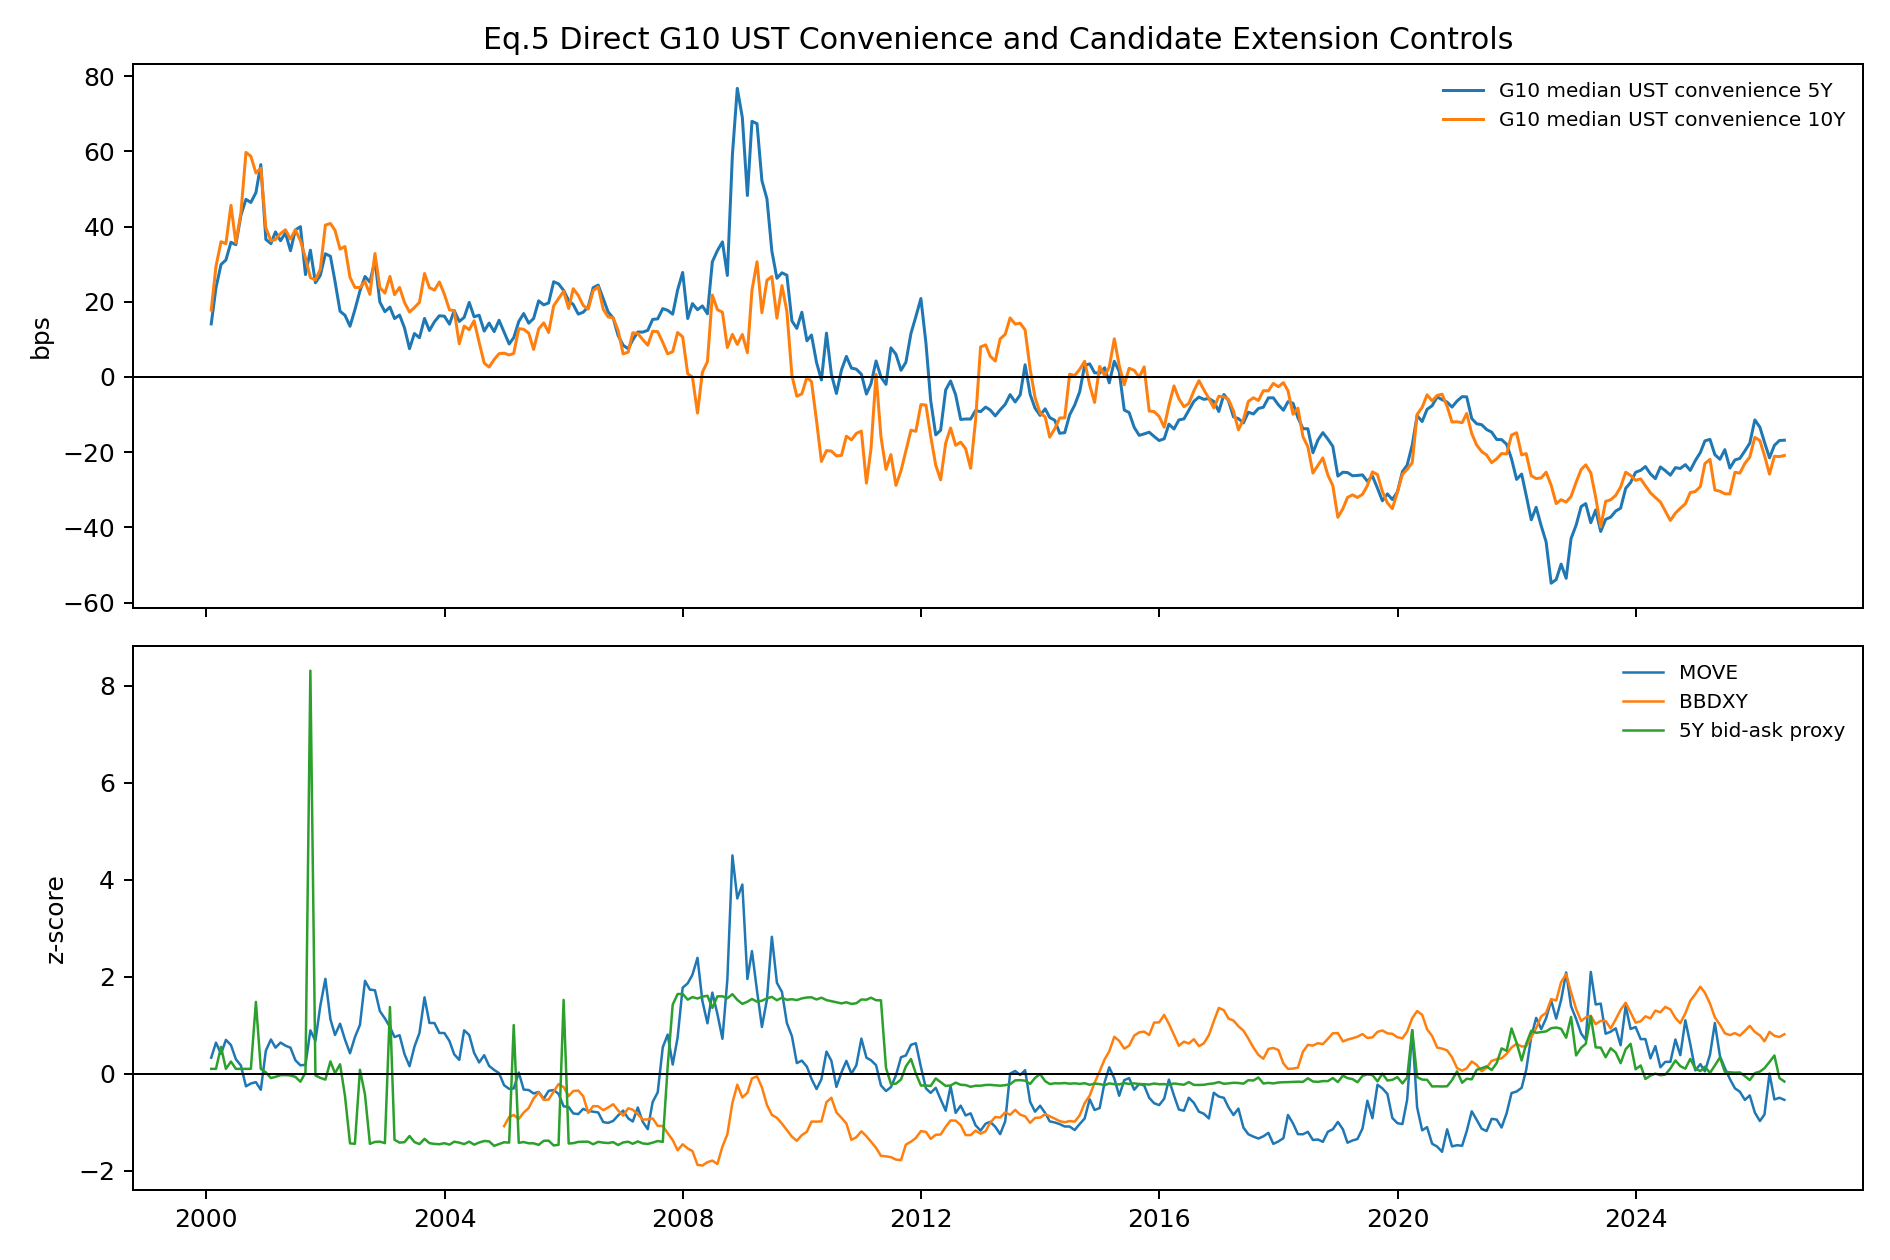

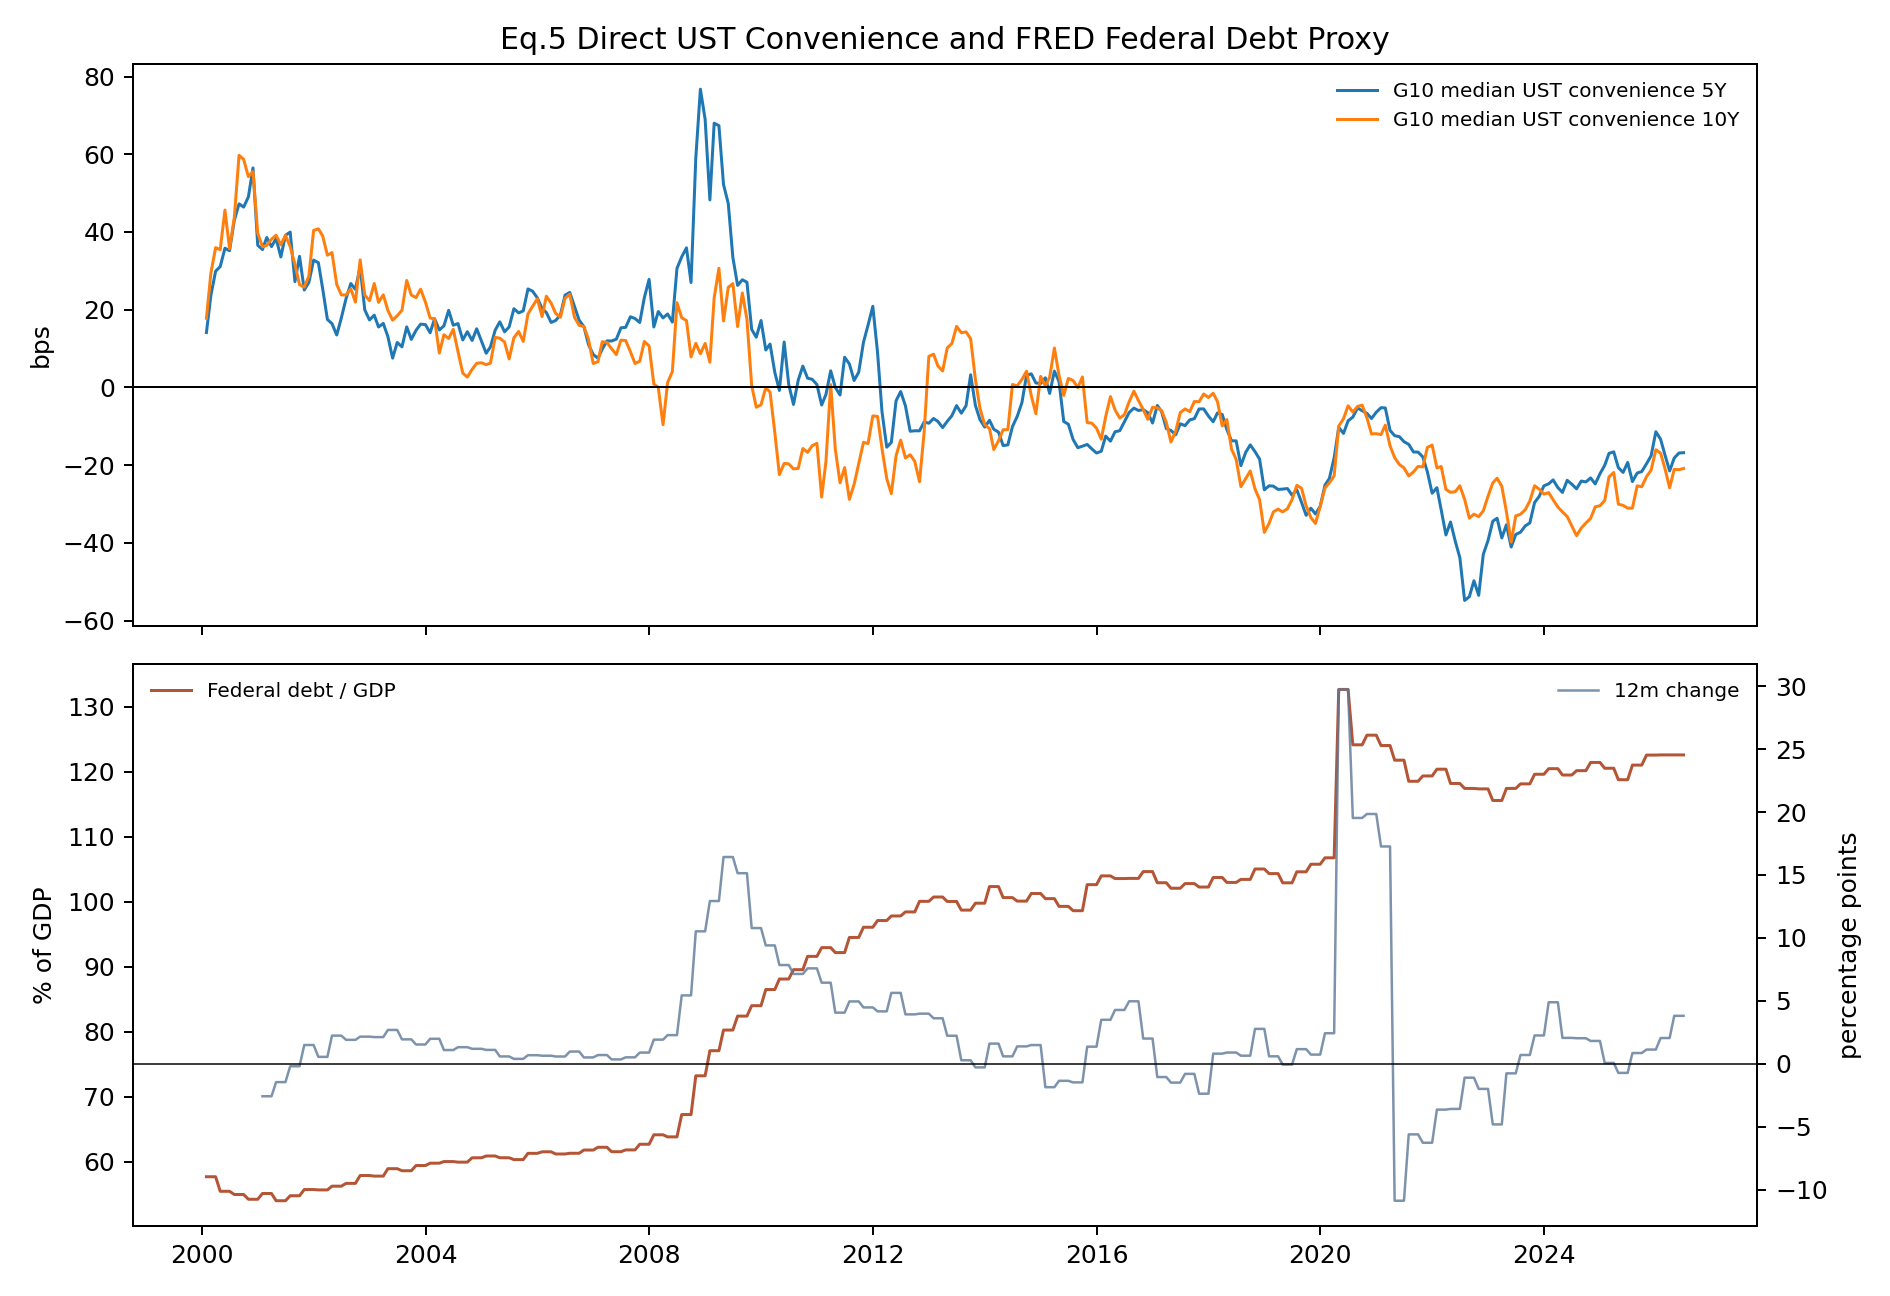

In [27]:
display(Image(filename=str(FIGURE_DIR / "eq5_ust_extension_monthly_timeseries.png")))
display(Image(filename=str(FIGURE_DIR / "eq5_ust_supply_extension.png")))


### Official supply / dealer first pass

This step replaces the broad FRED-only supply proxy with official public data:

- Treasury FiscalData MSPD marketable Treasury outstanding by class;
- Treasury FiscalData CUSIP-level marketable Treasury outstanding bucketed by remaining maturity;
- NY Fed Primary Dealer Statistics for Treasury positions, repo/reverse repo, transactions, and fails.

For 5Y convenience, the closest supply/dealer maturity bucket is 3-6Y. For 10Y convenience, the closest bucket is 7-11Y.


In [28]:
official_cov = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_official_variable_coverage.csv")
official_corr = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_official_correlations.csv")
official_models = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_official_regression_models.csv")
official_coefs = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_official_regression_coefficients.csv")

display(
    official_cov[
        official_cov["variable"].isin([
            "marketable_total_mil",
            "marketable_maturity_3y_to_6y_mil",
            "marketable_maturity_7y_to_11y_mil",
            "dealer_total_ust_position_ex_tips",
            "dealer_coupon_position_3y_to_6y",
            "dealer_coupon_position_7y_to_11y",
            "dealer_repo_treasury_ex_tips",
            "dealer_reverse_repo_treasury_ex_tips",
        ])
    ][["variable", "n_months", "date_min", "date_max", "latest_value"]]
)
display(official_corr)
display(official_models)
display(
    official_coefs[
        official_coefs["spec"].isin(["supply_dealer_controls_level", "supply_dealer_controls_12m_change"])
        & official_coefs["variable"].str.contains("marketable_maturity|dealer_coupon|dealer_repo", na=False)
    ][["target", "spec", "variable", "coef_bps_per_1sd", "t_stat_hac", "n_months", "r_squared"]]
)


,variable,n_months,date_min,date_max,latest_value
103,marketable_maturity_3y_to_6y_mil,305,2001-01-31,2026-05-31,5.344799e+06
105,marketable_maturity_7y_to_11y_mil,305,2001-01-31,2026-05-31,1.914660e+06
111,marketable_total_mil,305,2001-01-31,2026-05-31,3.089455e+07
140,dealer_coupon_position_3y_to_6y,159,2013-04-30,2026-06-30,6.424200e+04
141,dealer_coupon_position_7y_to_11y,159,2013-04-30,2026-06-30,4.088475e+04
144,dealer_total_ust_position_ex_tips,159,2013-04-30,2026-06-30,4.961150e+05
146,dealer_reverse_repo_treasury_ex_tips,155,2013-04-30,2026-06-30,2.803038e+06
147,dealer_repo_treasury_ex_tips,154,2013-04-30,2026-06-30,3.197566e+06


,target,variable,n_level,level_date_min,level_date_max,corr_level,n_change_12m,corr_change_12m
0,x_govt_raw_bps_5y,marketable_total_mil,305,2001-01-31,2026-05-31,-0.804202,293,0.178912
1,x_govt_raw_bps_5y,marketable_bills_share,305,2001-01-31,2026-05-31,0.638770,293,0.618668
2,x_govt_raw_bps_5y,marketable_notes_share,305,2001-01-31,2026-05-31,-0.301502,293,-0.624729
3,x_govt_raw_bps_5y,marketable_maturity_3y_to_6y_mil,305,2001-01-31,2026-05-31,-0.854341,293,-0.307294
4,x_govt_raw_bps_5y,marketable_maturity_7y_to_11y_mil,305,2001-01-31,2026-05-31,-0.856948,293,-0.296641
5,x_govt_raw_bps_5y,dealer_total_ust_position_ex_tips,159,2013-04-30,2026-06-30,-0.307882,147,0.164935
6,x_govt_raw_bps_5y,dealer_coupon_position_3y_to_6y,159,2013-04-30,2026-06-30,-0.339866,147,-0.071429
7,x_govt_raw_bps_5y,dealer_coupon_position_7y_to_11y,159,2013-04-30,2026-06-30,-0.169911,147,0.181509
8,x_govt_raw_bps_5y,dealer_repo_treasury_ex_tips,154,2013-04-30,2026-06-30,-0.319866,137,0.073702
9,x_govt_raw_bps_5y,dealer_reverse_repo_treasury_ex_tips,155,2013-04-30,2026-06-30,-0.369713,141,-0.001215


,target,spec,n_months,date_min,date_max,r_squared,adj_r_squared
0,x_govt_raw_bps_5y,official_supply_level,305,2001-01-31,2026-05-31,0.755808,0.754190
1,x_govt_raw_bps_5y,dealer_capacity_level,150,2013-04-30,2026-06-30,0.314416,0.295504
2,x_govt_raw_bps_5y,supply_dealer_controls_level,153,2013-04-30,2026-05-31,0.694522,0.677551
3,x_govt_raw_bps_5y,supply_dealer_controls_12m_change,136,2014-04-30,2026-05-31,0.484907,0.452460
4,x_govt_raw_bps_10y,official_supply_level,305,2001-01-31,2026-05-31,0.743586,0.741888
5,x_govt_raw_bps_10y,dealer_capacity_level,150,2013-04-30,2026-06-30,0.483825,0.469586
6,x_govt_raw_bps_10y,supply_dealer_controls_level,153,2013-04-30,2026-05-31,0.693045,0.675992
7,x_govt_raw_bps_10y,supply_dealer_controls_12m_change,136,2014-04-30,2026-05-31,0.304489,0.260677


,target,spec,variable,coef_bps_per_1sd,t_stat_hac,n_months,r_squared
6,x_govt_raw_bps_5y,supply_dealer_controls_level,marketable_maturity_3y_to_6y_mil,-4.177132,-1.097791,153,0.694522
7,x_govt_raw_bps_5y,supply_dealer_controls_level,dealer_coupon_position_3y_to_6y,0.771594,0.265700,153,0.694522
8,x_govt_raw_bps_5y,supply_dealer_controls_level,dealer_repo_treasury_ex_tips,2.679260,0.643052,153,0.694522
14,x_govt_raw_bps_5y,supply_dealer_controls_12m_change,marketable_maturity_3y_to_6y_mil_change_12m,-2.376022,-1.058002,136,0.484907
15,x_govt_raw_bps_5y,supply_dealer_controls_12m_change,dealer_coupon_position_3y_to_6y_change_12m,-0.539187,-0.186632,136,0.484907
16,x_govt_raw_bps_5y,supply_dealer_controls_12m_change,dealer_repo_treasury_ex_tips_change_12m,-0.535470,-0.275260,136,0.484907
28,x_govt_raw_bps_10y,supply_dealer_controls_level,marketable_maturity_7y_to_11y_mil,-5.626969,-2.156864,153,0.693045
29,x_govt_raw_bps_10y,supply_dealer_controls_level,dealer_coupon_position_7y_to_11y,-5.010685,-2.968754,153,0.693045
30,x_govt_raw_bps_10y,supply_dealer_controls_level,dealer_repo_treasury_ex_tips,5.178431,1.735010,153,0.693045
36,x_govt_raw_bps_10y,supply_dealer_controls_12m_change,marketable_maturity_7y_to_11y_mil_change_12m,-0.637619,-0.282172,136,0.304489


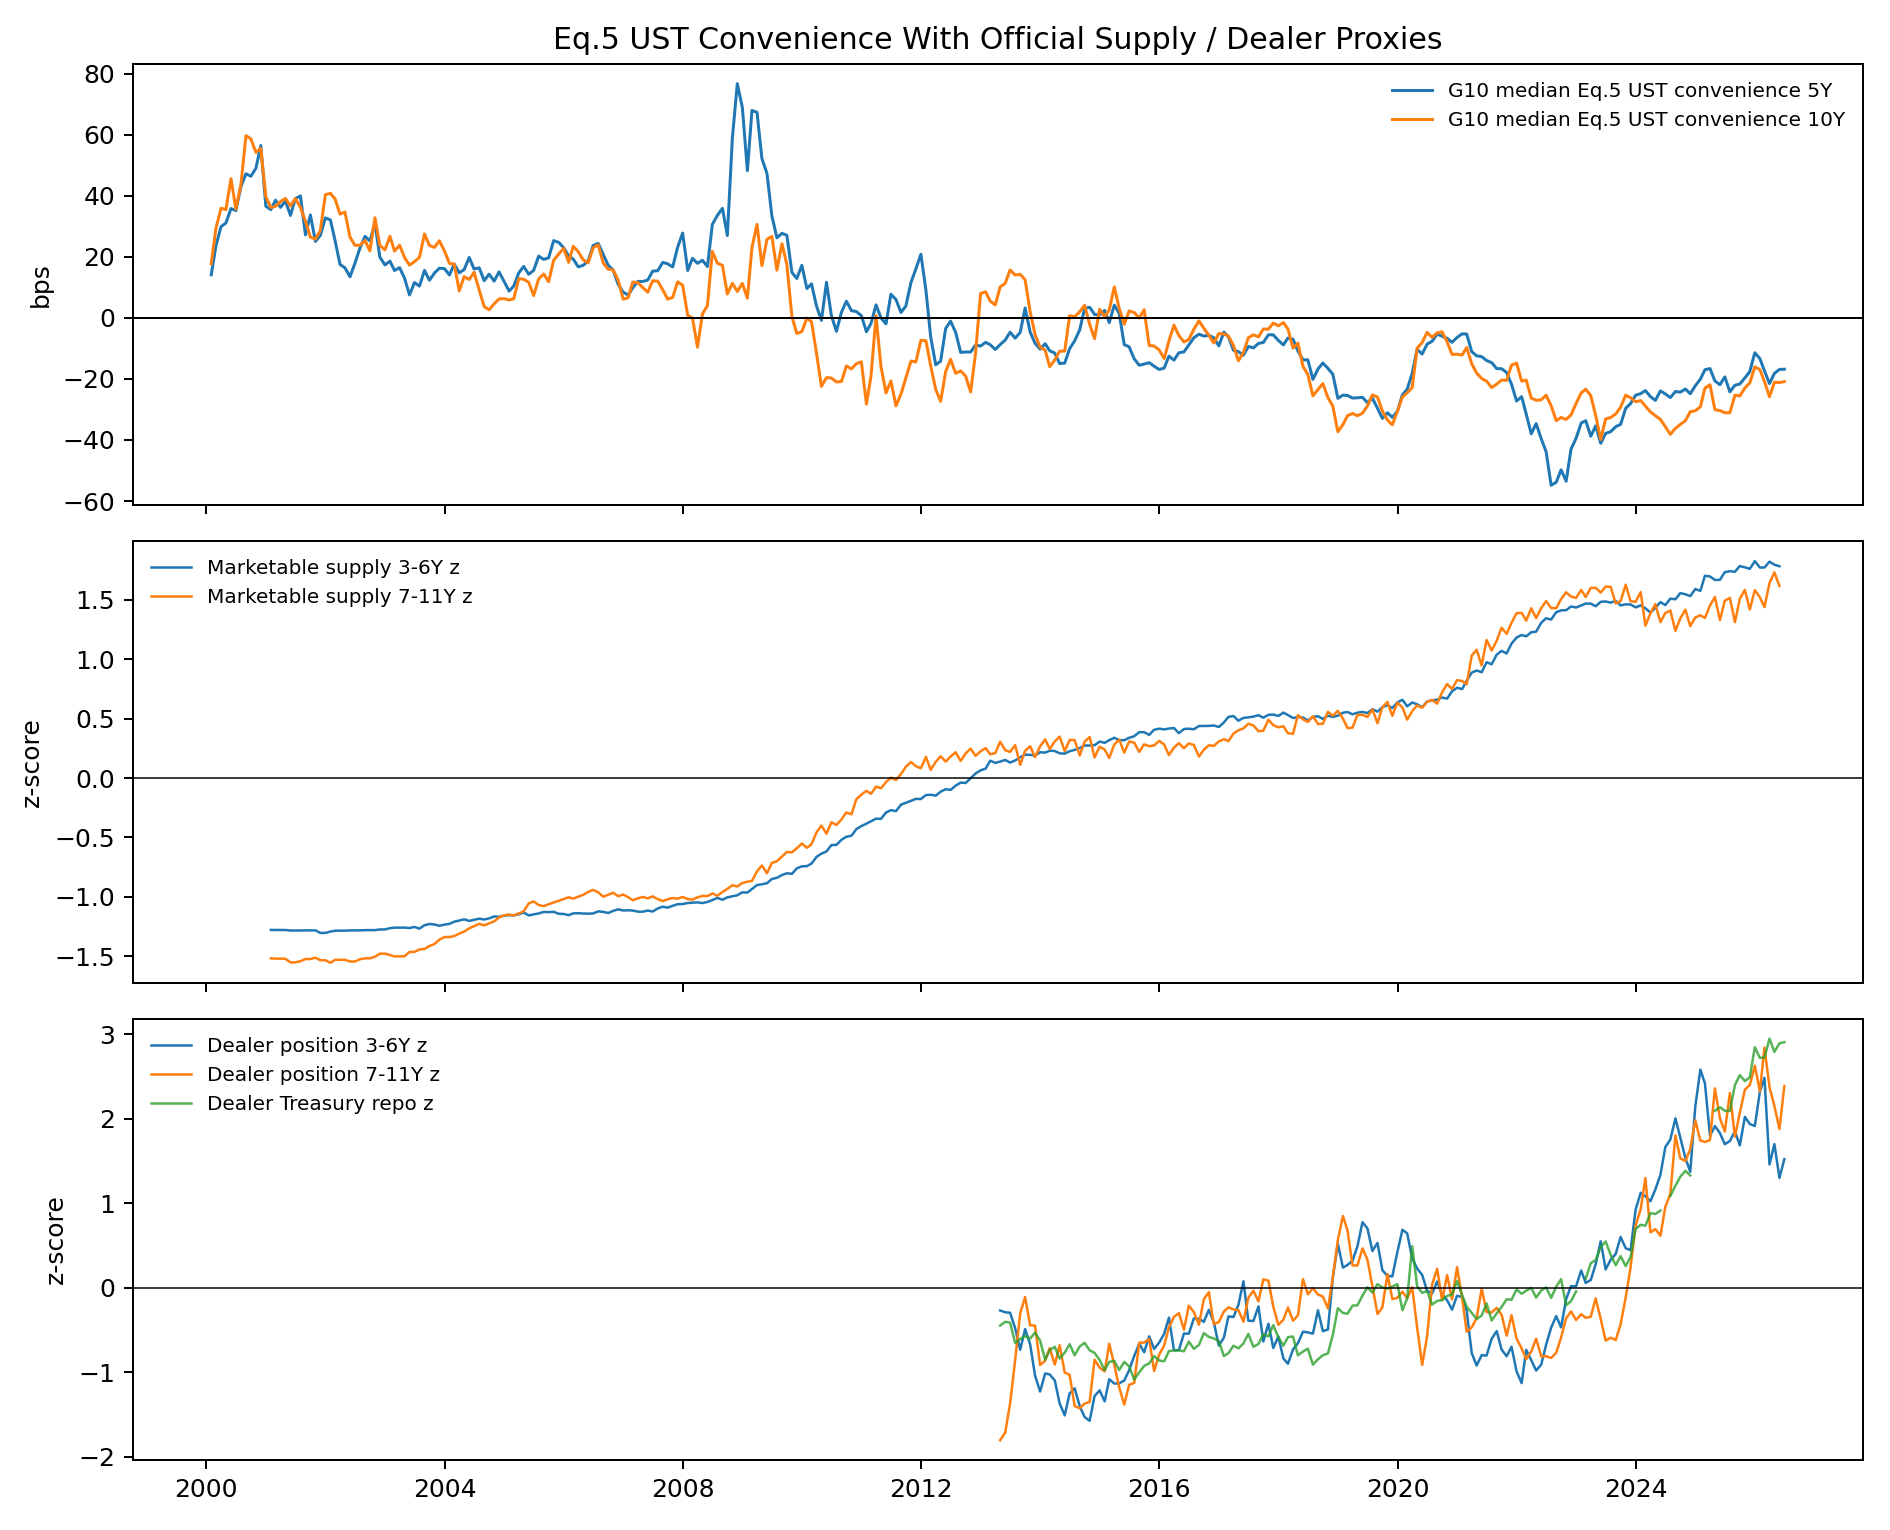

In [29]:
display(Image(filename=str(FIGURE_DIR / "eq5_supply_dealer_official_first_pass.png")))


### Robustness: trend, 12-month changes, and NY Fed reporting breaks

The official supply/dealer first pass is informative, but raw level correlations can be overstated because both Treasury supply and Treasury convenience are persistent time series.

This robustness layer checks:

- linear-detrended level correlations;
- 12-month-change correlations and regressions;
- post-2013 supply/dealer specifications;
- NY Fed primary-dealer reporting-break coverage;
- reporting-break dummy regressions and within-break dealer diagnostics.


In [30]:
robust_corr = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_robustness_correlation_modes.csv")
robust_models = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_robustness_regression_models.csv")
robust_coefs = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_robustness_regression_coefficients.csv")
seriesbreaks = pd.read_csv(TABLE_DIR / "nyfed_primary_dealer_seriesbreak_coverage.csv")
break_dummy_models = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_reporting_break_dummy_models.csv")
break_dummy_coefs = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_reporting_break_dummy_coefficients.csv")
within_breaks = pd.read_csv(TABLE_DIR / "eq5_supply_dealer_within_break_diagnostics.csv")

display(robust_corr)
display(robust_models)
display(
    robust_coefs[
        robust_coefs["variable"].str.contains("marketable_maturity|dealer_coupon|time_trend", na=False)
    ][["target", "spec", "variable", "coef_bps_per_1sd_or_year", "t_stat_hac", "n_months", "r_squared"]]
)
display(seriesbreaks.head(20))
display(break_dummy_models)
display(
    break_dummy_coefs[
        break_dummy_coefs["variable"].str.contains("marketable_maturity|dealer_coupon|break_", na=False)
    ][["target", "spec", "variable", "coef_bps_per_1sd_or_year", "t_stat_hac", "p_value_hac", "n_months", "r_squared"]]
)
display(within_breaks)


,target,variable_type,variable,sample,mode,n_months,date_min,date_max,correlation
0,x_govt_raw_bps_5y,same_maturity_supply,marketable_maturity_3y_to_6y_mil,full_available,level,305,2001-01-31,2026-05-31,-0.854341
1,x_govt_raw_bps_5y,same_maturity_supply,marketable_maturity_3y_to_6y_mil,full_available,linear_detrended_level,305,2001-01-31,2026-05-31,-0.383526
2,x_govt_raw_bps_5y,same_maturity_supply,marketable_maturity_3y_to_6y_mil,full_available,12m_change,293,2002-01-31,2026-05-31,-0.307294
3,x_govt_raw_bps_5y,same_maturity_supply,marketable_maturity_3y_to_6y_mil,post_2013,level,158,2013-04-30,2026-05-31,-0.616910
4,x_govt_raw_bps_5y,same_maturity_supply,marketable_maturity_3y_to_6y_mil,post_2013,linear_detrended_level,158,2013-04-30,2026-05-31,-0.165194
5,x_govt_raw_bps_5y,same_maturity_supply,marketable_maturity_3y_to_6y_mil,post_2013,12m_change,158,2013-04-30,2026-05-31,-0.403539
6,x_govt_raw_bps_5y,same_maturity_dealer,dealer_coupon_position_3y_to_6y,post_2013,level,159,2013-04-30,2026-06-30,-0.339866
7,x_govt_raw_bps_5y,same_maturity_dealer,dealer_coupon_position_3y_to_6y,post_2013,linear_detrended_level,159,2013-04-30,2026-06-30,0.254810
8,x_govt_raw_bps_5y,same_maturity_dealer,dealer_coupon_position_3y_to_6y,post_2013,12m_change,147,2014-04-30,2026-06-30,-0.071429
9,x_govt_raw_bps_10y,same_maturity_supply,marketable_maturity_7y_to_11y_mil,full_available,level,305,2001-01-31,2026-05-31,-0.857369


,target,spec,n_months,date_min,date_max,r_squared,adj_r_squared
0,x_govt_raw_bps_5y,full_supply_level_with_trend,305,2001-01-31,2026-05-31,0.733855,0.732092
1,x_govt_raw_bps_5y,full_supply_controls_level_with_trend,258,2004-12-31,2026-05-31,0.792017,0.786194
2,x_govt_raw_bps_5y,full_supply_controls_12m_change,246,2005-12-31,2026-05-31,0.381077,0.365539
3,x_govt_raw_bps_5y,post2013_supply_dealer_controls_level_with_trend,153,2013-04-30,2026-05-31,0.695076,0.675885
4,x_govt_raw_bps_5y,post2013_supply_dealer_controls_12m_change,136,2014-04-30,2026-05-31,0.484907,0.452460
5,x_govt_raw_bps_10y,full_supply_level_with_trend,305,2001-01-31,2026-05-31,0.737085,0.735344
6,x_govt_raw_bps_10y,full_supply_controls_level_with_trend,258,2004-12-31,2026-05-31,0.635805,0.625608
7,x_govt_raw_bps_10y,full_supply_controls_12m_change,246,2005-12-31,2026-05-31,0.090956,0.068135
8,x_govt_raw_bps_10y,post2013_supply_dealer_controls_level_with_trend,153,2013-04-30,2026-05-31,0.707083,0.688648
9,x_govt_raw_bps_10y,post2013_supply_dealer_controls_12m_change,136,2014-04-30,2026-05-31,0.304489,0.260677


,target,spec,variable,coef_bps_per_1sd_or_year,t_stat_hac,n_months,r_squared
0,x_govt_raw_bps_5y,full_supply_level_with_trend,marketable_maturity_3y_to_6y_mil,-26.938493,-2.189220,305,0.733855
1,x_govt_raw_bps_5y,full_supply_level_with_trend,time_trend,1.076114,0.671784,305,0.733855
2,x_govt_raw_bps_5y,full_supply_controls_level_with_trend,marketable_maturity_3y_to_6y_mil,-25.042154,-2.714791,258,0.792017
8,x_govt_raw_bps_5y,full_supply_controls_level_with_trend,time_trend,1.446975,0.970255,258,0.792017
9,x_govt_raw_bps_5y,full_supply_controls_12m_change,marketable_maturity_3y_to_6y_mil_change_12m,-4.605320,-2.455616,246,0.381077
15,x_govt_raw_bps_5y,post2013_supply_dealer_controls_level_with_trend,marketable_maturity_3y_to_6y_mil,-2.012411,-0.227423,153,0.695076
16,x_govt_raw_bps_5y,post2013_supply_dealer_controls_level_with_trend,dealer_coupon_position_3y_to_6y,1.009622,0.349972,153,0.695076
23,x_govt_raw_bps_5y,post2013_supply_dealer_controls_level_with_trend,time_trend,-0.592212,-0.328603,153,0.695076
24,x_govt_raw_bps_5y,post2013_supply_dealer_controls_12m_change,marketable_maturity_3y_to_6y_mil_change_12m,-2.376022,-1.058002,136,0.484907
25,x_govt_raw_bps_5y,post2013_supply_dealer_controls_12m_change,dealer_coupon_position_3y_to_6y_change_12m,-0.539187,-0.186632,136,0.484907


,variable,seriesbreak,label,n_weeks,date_min,date_max,value_mean,value_median
0,dealer_bills_position_ex_tips,SBN2013,APR 2013 TO DEC 2014,92,2013-04-03,2014-12-31,31332.858696,30417.5
1,dealer_bills_position_ex_tips,SBN2015,JAN 2015 TO DEC 2021,365,2015-01-07,2021-12-29,27381.249315,20719.0
2,dealer_bills_position_ex_tips,SBN2022,JAN 2022 TO JUN 2024,130,2022-01-05,2024-06-26,57218.523077,53888.5
3,dealer_bills_position_ex_tips,SBN2024,JUL 2024 AND ON,104,2024-07-03,2026-06-24,65059.028846,68479.5
4,dealer_coupon_position_3y_to_6y,SBN2013,APR 2013 TO DEC 2014,92,2013-04-03,2014-12-31,4997.195652,2323.0
5,dealer_coupon_position_3y_to_6y,SBN2015,JAN 2015 TO DEC 2021,365,2015-01-07,2021-12-29,20344.487671,18052.0
6,dealer_coupon_position_3y_to_6y,SBN2022,JAN 2022 TO JUN 2024,130,2022-01-05,2024-06-26,32651.769231,33910.5
7,dealer_coupon_position_3y_to_6y,SBN2024,JUL 2024 AND ON,104,2024-07-03,2026-06-24,72379.788462,71805.0
8,dealer_coupon_position_7y_to_11y,SBN2013,APR 2013 TO DEC 2014,92,2013-04-03,2014-12-31,-8071.826087,-7723.5
9,dealer_coupon_position_7y_to_11y,SBN2015,JAN 2015 TO DEC 2021,365,2015-01-07,2021-12-29,2354.895890,2283.0


,target,spec,n_months,date_min,date_max,r_squared,adj_r_squared
0,x_govt_raw_bps_5y,post2013_level_with_trend_and_break_dummies,153,2013-04-30,2026-05-31,0.711396,0.686659
1,x_govt_raw_bps_5y,post2013_12m_change_with_break_dummies,136,2014-04-30,2026-05-31,0.643559,0.611940
2,x_govt_raw_bps_10y,post2013_level_with_trend_and_break_dummies,153,2013-04-30,2026-05-31,0.737494,0.714994
3,x_govt_raw_bps_10y,post2013_12m_change_with_break_dummies,136,2014-04-30,2026-05-31,0.548392,0.508330


,target,spec,variable,coef_bps_per_1sd_or_year,t_stat_hac,p_value_hac,n_months,r_squared
0,x_govt_raw_bps_5y,post2013_level_with_trend_and_break_dummies,marketable_maturity_3y_to_6y_mil,-2.024701,-0.247862,8.042415e-01,153,0.711396
1,x_govt_raw_bps_5y,post2013_level_with_trend_and_break_dummies,dealer_coupon_position_3y_to_6y,1.267503,0.356178,7.217074e-01,153,0.711396
8,x_govt_raw_bps_5y,post2013_level_with_trend_and_break_dummies,break_SBN2015,10.661452,1.339430,1.804307e-01,153,0.711396
9,x_govt_raw_bps_5y,post2013_level_with_trend_and_break_dummies,break_SBN2022,10.999198,0.927265,3.537891e-01,153,0.711396
10,x_govt_raw_bps_5y,post2013_level_with_trend_and_break_dummies,break_SBN2024,14.561480,1.362476,1.730478e-01,153,0.711396
12,x_govt_raw_bps_5y,post2013_12m_change_with_break_dummies,marketable_maturity_3y_to_6y_mil_change_12m,-5.324125,-3.072699,2.121324e-03,136,0.643559
13,x_govt_raw_bps_5y,post2013_12m_change_with_break_dummies,dealer_coupon_position_3y_to_6y_change_12m,-2.049374,-0.914355,3.605306e-01,136,0.643559
20,x_govt_raw_bps_5y,post2013_12m_change_with_break_dummies,break_SBN2015,3.343360,0.727964,4.666353e-01,136,0.643559
21,x_govt_raw_bps_5y,post2013_12m_change_with_break_dummies,break_SBN2022,26.178281,4.033910,5.485624e-05,136,0.643559
22,x_govt_raw_bps_5y,post2013_12m_change_with_break_dummies,break_SBN2024,24.779436,3.008182,2.628156e-03,136,0.643559


,target,seriesbreak,variable_type,variable,mode,n_months,date_min,date_max,correlation
0,x_govt_raw_bps_5y,SBN2013,same_maturity_supply,marketable_maturity_3y_to_6y_mil,level,21,2013-04-30,2014-12-31,0.407431
1,x_govt_raw_bps_5y,SBN2013,same_maturity_supply,marketable_maturity_3y_to_6y_mil,12m_change,21,2013-04-30,2014-12-31,0.233824
2,x_govt_raw_bps_5y,SBN2013,same_maturity_dealer,dealer_coupon_position_3y_to_6y,level,21,2013-04-30,2014-12-31,-0.011558
3,x_govt_raw_bps_5y,SBN2013,same_maturity_dealer,dealer_coupon_position_3y_to_6y,12m_change,9,2014-04-30,2014-12-31,0.826767
4,x_govt_raw_bps_5y,SBN2015,same_maturity_supply,marketable_maturity_3y_to_6y_mil,level,84,2015-01-31,2021-12-31,-0.267303
5,x_govt_raw_bps_5y,SBN2015,same_maturity_supply,marketable_maturity_3y_to_6y_mil,12m_change,84,2015-01-31,2021-12-31,-0.094582
6,x_govt_raw_bps_5y,SBN2015,same_maturity_dealer,dealer_coupon_position_3y_to_6y,level,84,2015-01-31,2021-12-31,-0.601927
7,x_govt_raw_bps_5y,SBN2015,same_maturity_dealer,dealer_coupon_position_3y_to_6y,12m_change,84,2015-01-31,2021-12-31,-0.497277
8,x_govt_raw_bps_5y,SBN2022,same_maturity_supply,marketable_maturity_3y_to_6y_mil,level,30,2022-01-31,2024-06-30,0.081939
9,x_govt_raw_bps_5y,SBN2022,same_maturity_supply,marketable_maturity_3y_to_6y_mil,12m_change,30,2022-01-31,2024-06-30,-0.896892


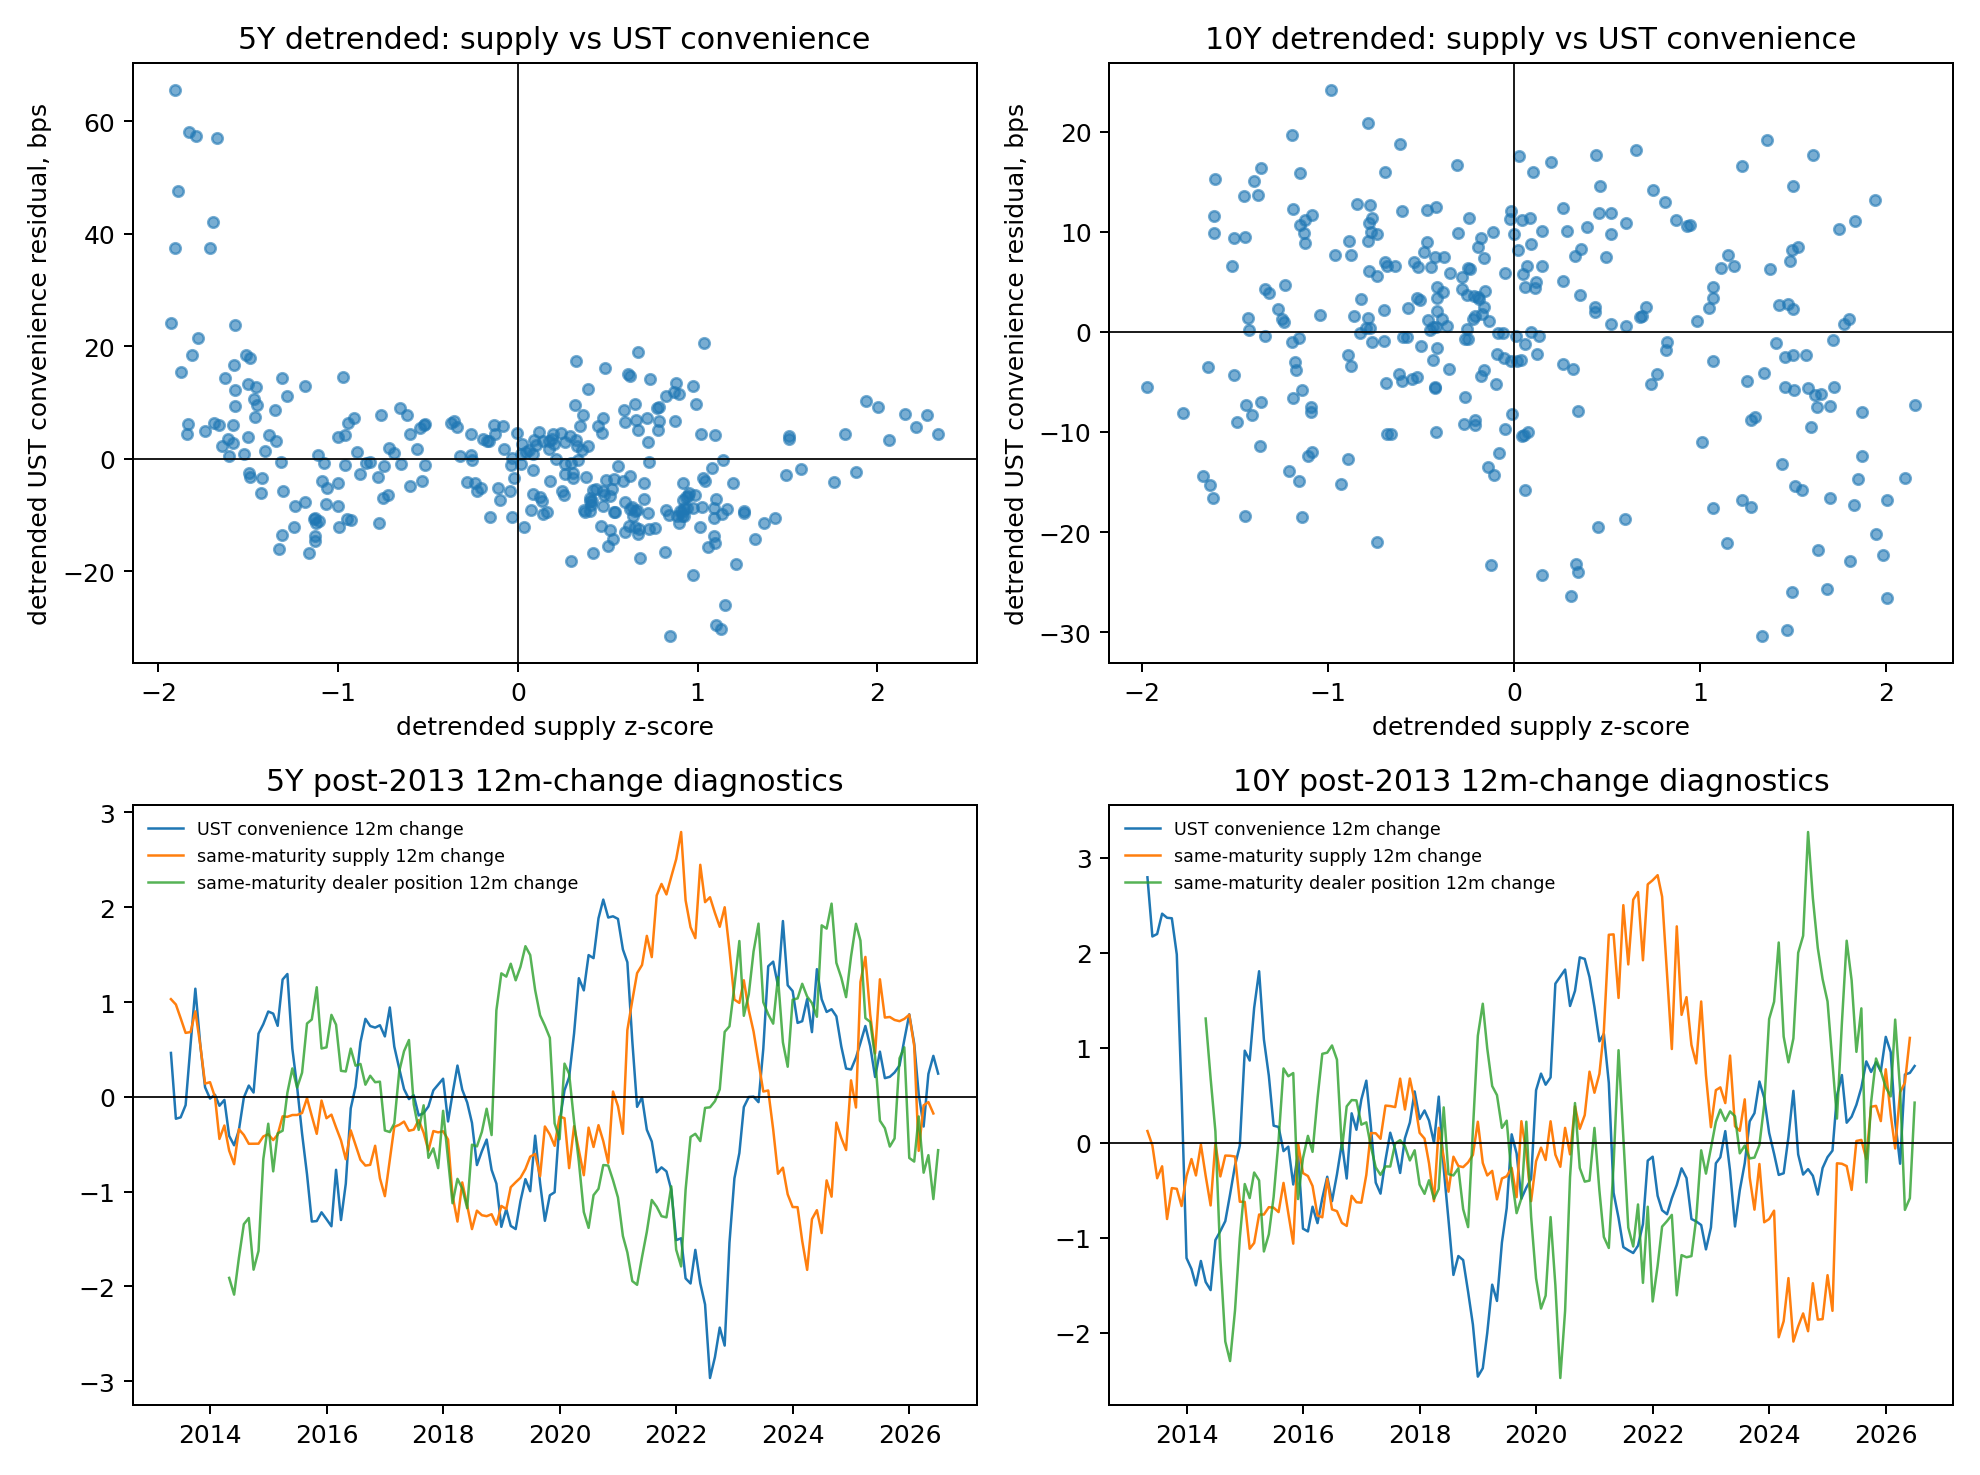

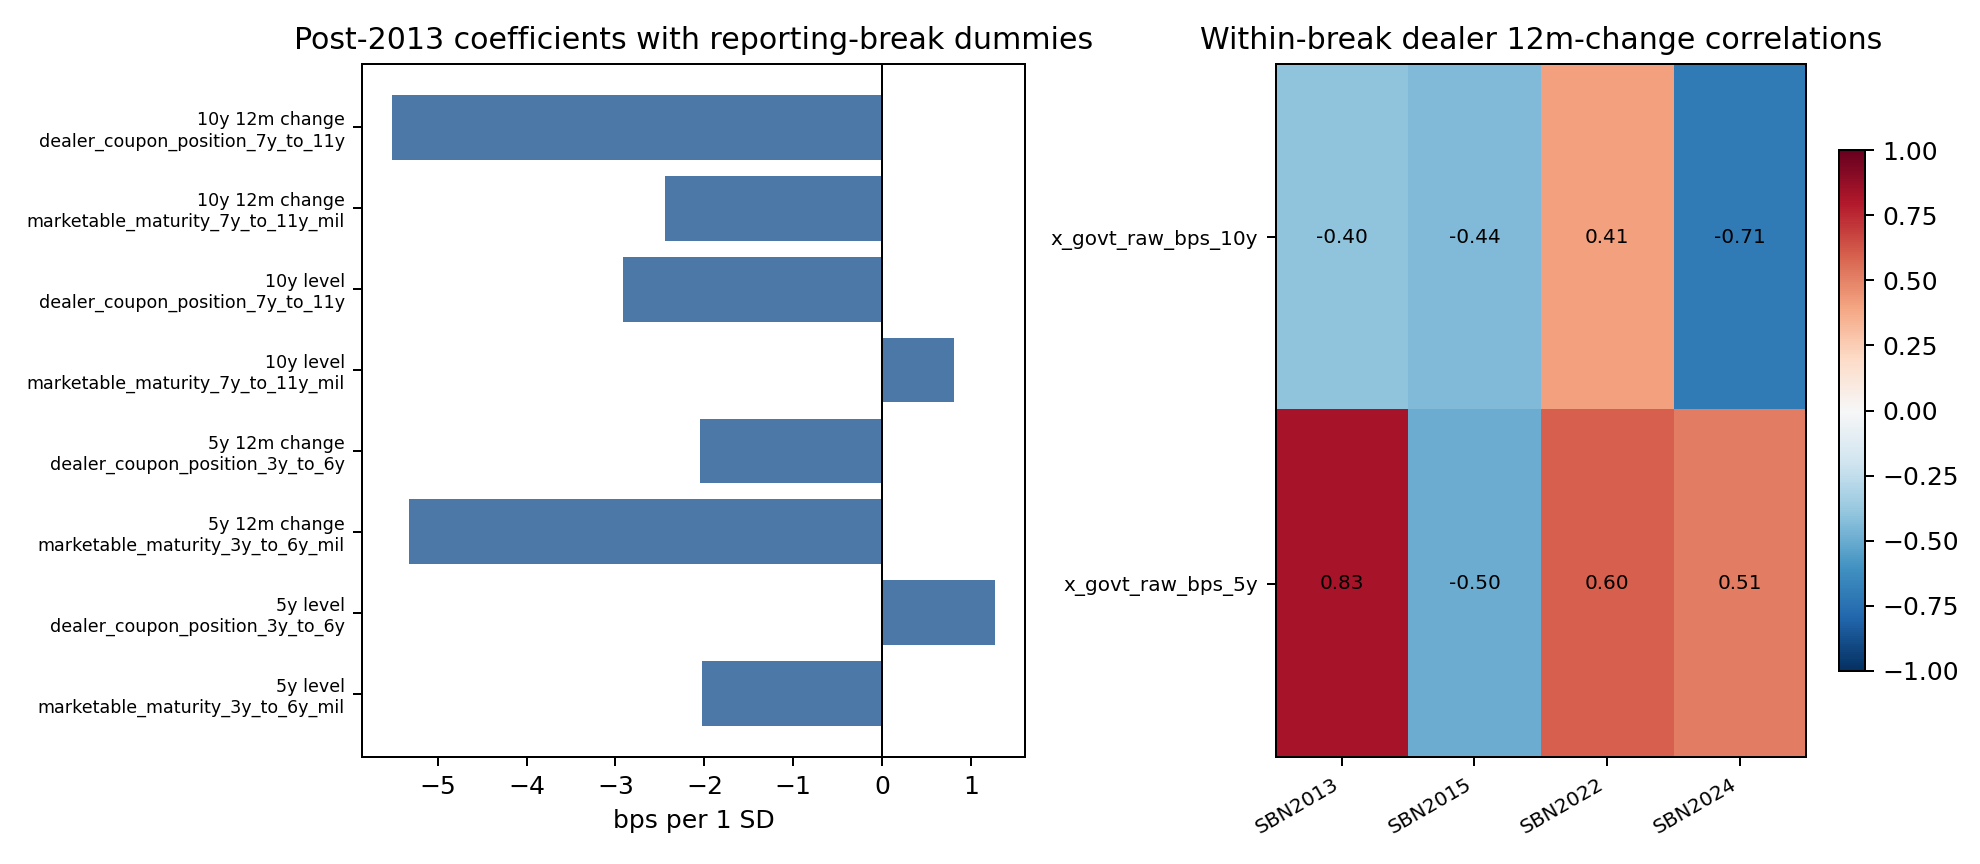

In [31]:
display(Image(filename=str(FIGURE_DIR / "eq5_supply_dealer_robustness_checks.png")))
display(Image(filename=str(FIGURE_DIR / "eq5_supply_dealer_reporting_break_checks.png")))


### Eq.5 extension interpretation

This layer suggested a supply/inventory research question, but it did not establish a mechanism. Section 15 now holds the controlling results: fixed composition, nominal-only supply reconciliation, complete-month filtering, exclusion of whole difference windows crossing reporting/benchmark regimes, and calendar-aware HAC. Differences from the legacy coefficients reflect a different reviewed population and statistical design, not a search for the strongest t-statistic.


## 15. Reviewed Interim Results: Replication and a Bounded Extension

### Question and scope

**Part A:** Can raw market instruments reconstruct the 5Y/10Y Treasury-convenience measure and its decline/rebound?

**Part B:** Is convenience associated with U.S. nominal maturity-bucket supply and dealer inventory once composition, persistence, and reporting breaks are addressed?

Part B is our exploratory extension, not the paper's original country/GDP regression. No causal design is claimed. Eq.5 uses swap-implied hedging premia at these maturities, not a newly invented independent outright-forward dataset.

### Reviewed method

- Fixed eight currencies (AUD, CAD, CHF, DKK, EUR, GBP, NZD, SEK), selected for historical coverage, with seven-currency/DKK-exclusion and median sensitivity. JPY/NOK do not have complete early histories.
- Monthly country means require at least 15 daily quotes. Every fixed-cohort currency must be present; no forward fill. June 2026 is incomplete and excluded.
- Equal-weight means preserve additive identities. Cross-sectional medians of individual components generally do **not** add up to the median total; the earlier median-component figure is illustrative, not an exact aggregate decomposition.
- Treasury MSPD nominal Notes/Bonds only; issue-line sums reconcile against reported unmatured class totals. Dealer positions exclude TIPS, include long-minus-short exposure, and are **not** spare balance-sheet capacity.
- Maturity bins (3,6]Y for 5Y and (7,11]Y for 10Y; the latter is chosen to match dealer reporting and differs from the paper's 6-11Y supply bin.
- Controlled post-April-2013 models: trend-adjusted levels, 1-month changes, 12-month changes. Absolute supply is the main predictor; supply share is a pre-specified composition sensitivity.
- Entire change windows crossing any dealer or benchmark regime are excluded. Calendar-aware Bartlett/Newey-West uses actual month gaps, 12/18 lags for overlapping annual changes. A March-June-2020 window exclusion checks whether the results depend on the crisis episode.

The early 2000-2006 fixed cohort has only 48/49 complete months, not the paper's full 84-month window. Long comparisons also span IBOR/OIS conventions, so they measure the authors' stitched series, not a constant-benchmark causal shift.


In [32]:
from src import analyze_treasury_interim
analyze_treasury_interim.main()

interim_periods = pd.read_csv(TABLE_DIR / "treasury_interim_period_means.csv")
interim_components = pd.read_csv(TABLE_DIR / "treasury_interim_component_periods.csv")
interim_bridge = pd.read_csv(TABLE_DIR / "treasury_interim_rebound_decomposition.csv")
interim_coefs = pd.read_csv(TABLE_DIR / "treasury_interim_coefficients.csv")
interim_reconciliation = pd.read_csv(TABLE_DIR / "treasury_interim_supply_reconciliation.csv")
interim_audit = pd.read_csv(TABLE_DIR / "treasury_interim_model_audit.csv")

assert interim_reconciliation["relative_error"].max() < 1e-6
assert interim_bridge[["eq5_bridge_error_bps", "eq6_bridge_error_bps"]].abs().max().max() < 1e-8
display(pd.read_csv(TABLE_DIR / "treasury_interim_cohort_coverage.csv"))
display(interim_periods)
display(interim_components)


Complete-month cutoff: 2026-05-31
tenor aggregation             period   mean_bps  n_months
   5y fixed8_mean          2000-2006  12.527194        49
   5y fixed8_mean          2010-2020 -10.057844       132
   5y fixed8_mean          2021-2025 -30.527354        59
   5y fixed8_mean 2023-calendar-year -40.643890        12
   5y fixed8_mean       2026-Jan-May -20.155770         5
  10y fixed8_mean          2000-2006  13.888017        48
  10y fixed8_mean          2010-2020 -20.869628       130
  10y fixed8_mean          2021-2025 -33.424513        56
  10y fixed8_mean 2023-calendar-year -38.447043        12
  10y fixed8_mean       2026-Jan-May -27.744092         5
tenor      cohort   transform supply_type              episode            variable  coef_bps_per_sd  se_calendar_hac   ci95_low  ci95_high  p_value  hac_months    raw_sd  coef_bps_per_raw_unit  n_months  r_squared first_month last_month
   5y fixed8_mean level_trend    trillion                  all  supply_trillion_5y       -1

,currency,tenor,n_valid_months,first_month,last_month,in_fixed8
0,AUD,5y,316,2000-01-31,2026-05-31,True
1,CAD,5y,307,2000-08-31,2026-05-31,True
2,CHF,5y,307,2000-06-30,2026-05-31,True
3,DKK,5y,306,2000-08-31,2026-05-31,True
4,EUR,5y,311,2000-06-30,2026-05-31,True
5,GBP,5y,309,2000-04-30,2026-05-31,True
6,JPY,5y,169,2011-05-31,2026-05-31,False
7,NOK,5y,212,2008-09-30,2026-05-31,False
8,NZD,5y,286,2000-05-31,2026-05-31,True
9,SEK,5y,308,2000-08-31,2026-05-31,True


,tenor,aggregation,period,mean_bps,n_months
0,5y,fixed8_mean,2000-2006,12.527194,49
1,5y,fixed8_mean,2010-2020,-10.057844,132
2,5y,fixed8_mean,2021-2025,-30.527354,59
3,5y,fixed8_mean,2023-calendar-year,-40.643890,12
4,5y,fixed8_mean,2026-Jan-May,-20.155770,5
5,5y,fixed8_median,2000-2006,17.007276,49
6,5y,fixed8_median,2010-2020,-9.813935,132
7,5y,fixed8_median,2021-2025,-30.251587,59
8,5y,fixed8_median,2023-calendar-year,-39.587002,12
9,5y,fixed8_median,2026-Jan-May,-19.616349,5


,tenor,period,n_months,x_govt_raw_bps,diff_y_raw_bps,rho_raw_bps,x_rf_raw_bps,us_swap_spread_bps,foreign_swap_spread_bps
0,5y,2000-2006,49,12.527194,34.106815,21.579621,-2.219565,42.642980,27.896221
1,5y,2010-2020,132,-10.057844,-38.790001,-28.732156,7.853633,9.969170,27.880647
2,5y,2021-2025,59,-30.527354,-107.750986,-77.223633,13.099226,-21.638986,21.987594
3,5y,2023,12,-40.643890,-103.625265,-62.981375,20.474192,-26.877284,34.240799
4,5y,2026-Jan-May,5,-20.155770,-98.698181,-78.542412,6.921699,-30.699538,-3.622069
5,10y,2000-2006,48,13.888017,8.968823,-4.919193,-2.182377,45.545191,29.474798
6,10y,2010-2020,130,-20.869628,-55.393081,-34.523453,3.989519,-0.553493,24.305654
7,10y,2021-2025,56,-33.424513,-101.025897,-67.601383,10.782304,-29.333397,14.873421
8,10y,2023,12,-38.447043,-87.871700,-49.424657,19.673041,-30.690895,27.429189
9,10y,2026-Jan-May,5,-27.744092,-98.267329,-70.523237,4.230821,-44.234080,-12.259167


In [33]:
display(interim_bridge.round(3))
display(pd.read_csv(TABLE_DIR / "treasury_interim_country_rebound.csv").round(3))
main_associations = interim_coefs[
    interim_coefs["cohort"].eq("fixed8_mean")
    & interim_coefs["supply_type"].eq("trillion")
    & interim_coefs["episode"].eq("all")
]
display(main_associations[["tenor", "transform", "variable", "hac_months", "coef_bps_per_sd",
                           "ci95_low", "ci95_high", "p_value", "n_months"]].round(3))
display(interim_coefs[interim_coefs["transform"].eq("change_12m") & interim_coefs["hac_months"].eq(12)]
        [["tenor", "cohort", "supply_type", "episode", "variable", "coef_bps_per_sd", "ci95_low", "ci95_high", "n_months"]].round(3))
display(interim_audit)


,tenor,comparison,start,end,convenience_change_bps,diff_y_change_bps,rho_change_bps,dollar_proxy_change_bps,us_swap_spread_change_bps,foreign_swap_spread_change_bps,eq5_bridge_error_bps,eq6_bridge_error_bps
0,5y,2023 average to 2026 Jan-May average,2023 annual average,2026 Jan-May average,20.488,4.927,-15.561,-13.552,-3.822,-37.863,-0.0,0.0
1,5y,2023 trough month to latest complete month,2023-04-30,2026-05-31,26.435,-30.572,-57.007,-12.638,-4.521,-43.595,0.0,-0.0
2,10y,2023 average to 2026 Jan-May average,2023 annual average,2026 Jan-May average,10.703,-10.396,-21.099,-15.442,-13.543,-39.688,-0.0,0.0
3,10y,2023 trough month to latest complete month,2023-04-30,2026-05-31,17.303,-41.358,-58.661,-14.800,-14.640,-46.744,-0.0,-0.0


,currency,tenor,x_govt_raw_bps_change_bps,diff_y_raw_bps_change_bps,rho_raw_bps_change_bps,x_rf_raw_bps_change_bps,us_swap_spread_bps_change_bps,foreign_swap_spread_bps_change_bps
0,AUD,10y,33.532,59.904,26.372,3.991,-13.564,-43.105
1,AUD,5y,29.288,105.577,76.288,2.198,-3.811,-30.902
2,CAD,10y,9.828,-25.141,-34.969,-13.532,-13.546,-36.906
3,CAD,5y,23.556,-23.853,-47.410,-3.327,-3.816,-30.700
4,CHF,10y,-20.673,-102.932,-82.259,-51.482,-13.508,-44.317
5,CHF,5y,9.843,-65.888,-75.732,-33.963,-3.805,-47.611
6,DKK,10y,-13.451,-23.181,-9.729,-25.436,-13.584,-25.569
7,DKK,5y,-3.769,-5.099,-1.330,-23.678,-3.862,-23.771
8,EUR,10y,20.576,14.132,-6.445,-22.454,-13.504,-56.534
9,EUR,5y,27.660,31.467,3.807,-22.335,-3.767,-53.763


,tenor,transform,variable,hac_months,coef_bps_per_sd,ci95_low,ci95_high,p_value,n_months
0,5y,level_trend,supply_trillion_5y,12,-11.241,-20.919,-1.563,0.023,156
1,5y,level_trend,dealer_billion_5y,12,2.152,-4.221,8.526,0.508,156
2,5y,change_1m,supply_trillion_5y,6,-0.098,-0.464,0.268,0.600,151
3,5y,change_1m,dealer_billion_5y,6,-0.115,-0.526,0.296,0.584,151
4,5y,change_12m,supply_trillion_5y,12,-4.336,-6.703,-1.970,0.000,104
5,5y,change_12m,dealer_billion_5y,12,0.119,-4.555,4.793,0.960,104
6,5y,change_12m,supply_trillion_5y,18,-4.336,-6.658,-2.015,0.000,104
7,5y,change_12m,dealer_billion_5y,18,0.119,-4.737,4.975,0.962,104
32,10y,level_trend,supply_trillion_10y,12,-9.095,-14.108,-4.083,0.000,154
33,10y,level_trend,dealer_billion_10y,12,-2.239,-5.968,1.490,0.239,154


,tenor,cohort,supply_type,episode,variable,coef_bps_per_sd,ci95_low,ci95_high,n_months
4,5y,fixed8_mean,trillion,all,supply_trillion_5y,-4.336,-6.703,-1.970,104
5,5y,fixed8_mean,trillion,all,dealer_billion_5y,0.119,-4.555,4.793,104
8,5y,fixed8_mean,share_pct,all,supply_share_pct_5y,-0.005,-3.901,3.890,104
9,5y,fixed8_mean,share_pct,all,dealer_billion_5y,1.568,-3.986,7.122,104
12,5y,fixed8_mean,trillion,exclude_covid_window,supply_trillion_5y,-3.286,-5.350,-1.222,88
13,5y,fixed8_mean,trillion,exclude_covid_window,dealer_billion_5y,1.762,-1.904,5.428,88
20,5y,fixed8_median,trillion,all,supply_trillion_5y,-6.082,-9.641,-2.522,104
21,5y,fixed8_median,trillion,all,dealer_billion_5y,0.197,-5.020,5.413,104
28,5y,fixed7_mean,trillion,all,supply_trillion_5y,-4.986,-7.455,-2.518,104
29,5y,fixed7_mean,trillion,all,dealer_billion_5y,0.122,-4.536,4.779,104


,tenor,cohort,transform,supply_type,episode,n_complete_months,n_excluded_regime_windows,calendar_span_months,n_design_columns
0,5y,fixed8_mean,level_trend,trillion,all,156,1,158,13
1,5y,fixed8_mean,change_1m,trillion,all,151,6,157,8
2,5y,fixed8_mean,change_12m,trillion,all,104,54,146,8
3,5y,fixed8_mean,change_12m,share_pct,all,104,54,146,8
4,5y,fixed8_mean,change_12m,trillion,exclude_covid_window,88,70,146,8
5,5y,fixed8_median,level_trend,trillion,all,156,1,158,13
6,5y,fixed8_median,change_1m,trillion,all,151,6,157,8
7,5y,fixed8_median,change_12m,trillion,all,104,54,146,8
8,5y,fixed7_mean,level_trend,trillion,all,157,1,158,13
9,5y,fixed7_mean,change_1m,trillion,all,152,6,157,8


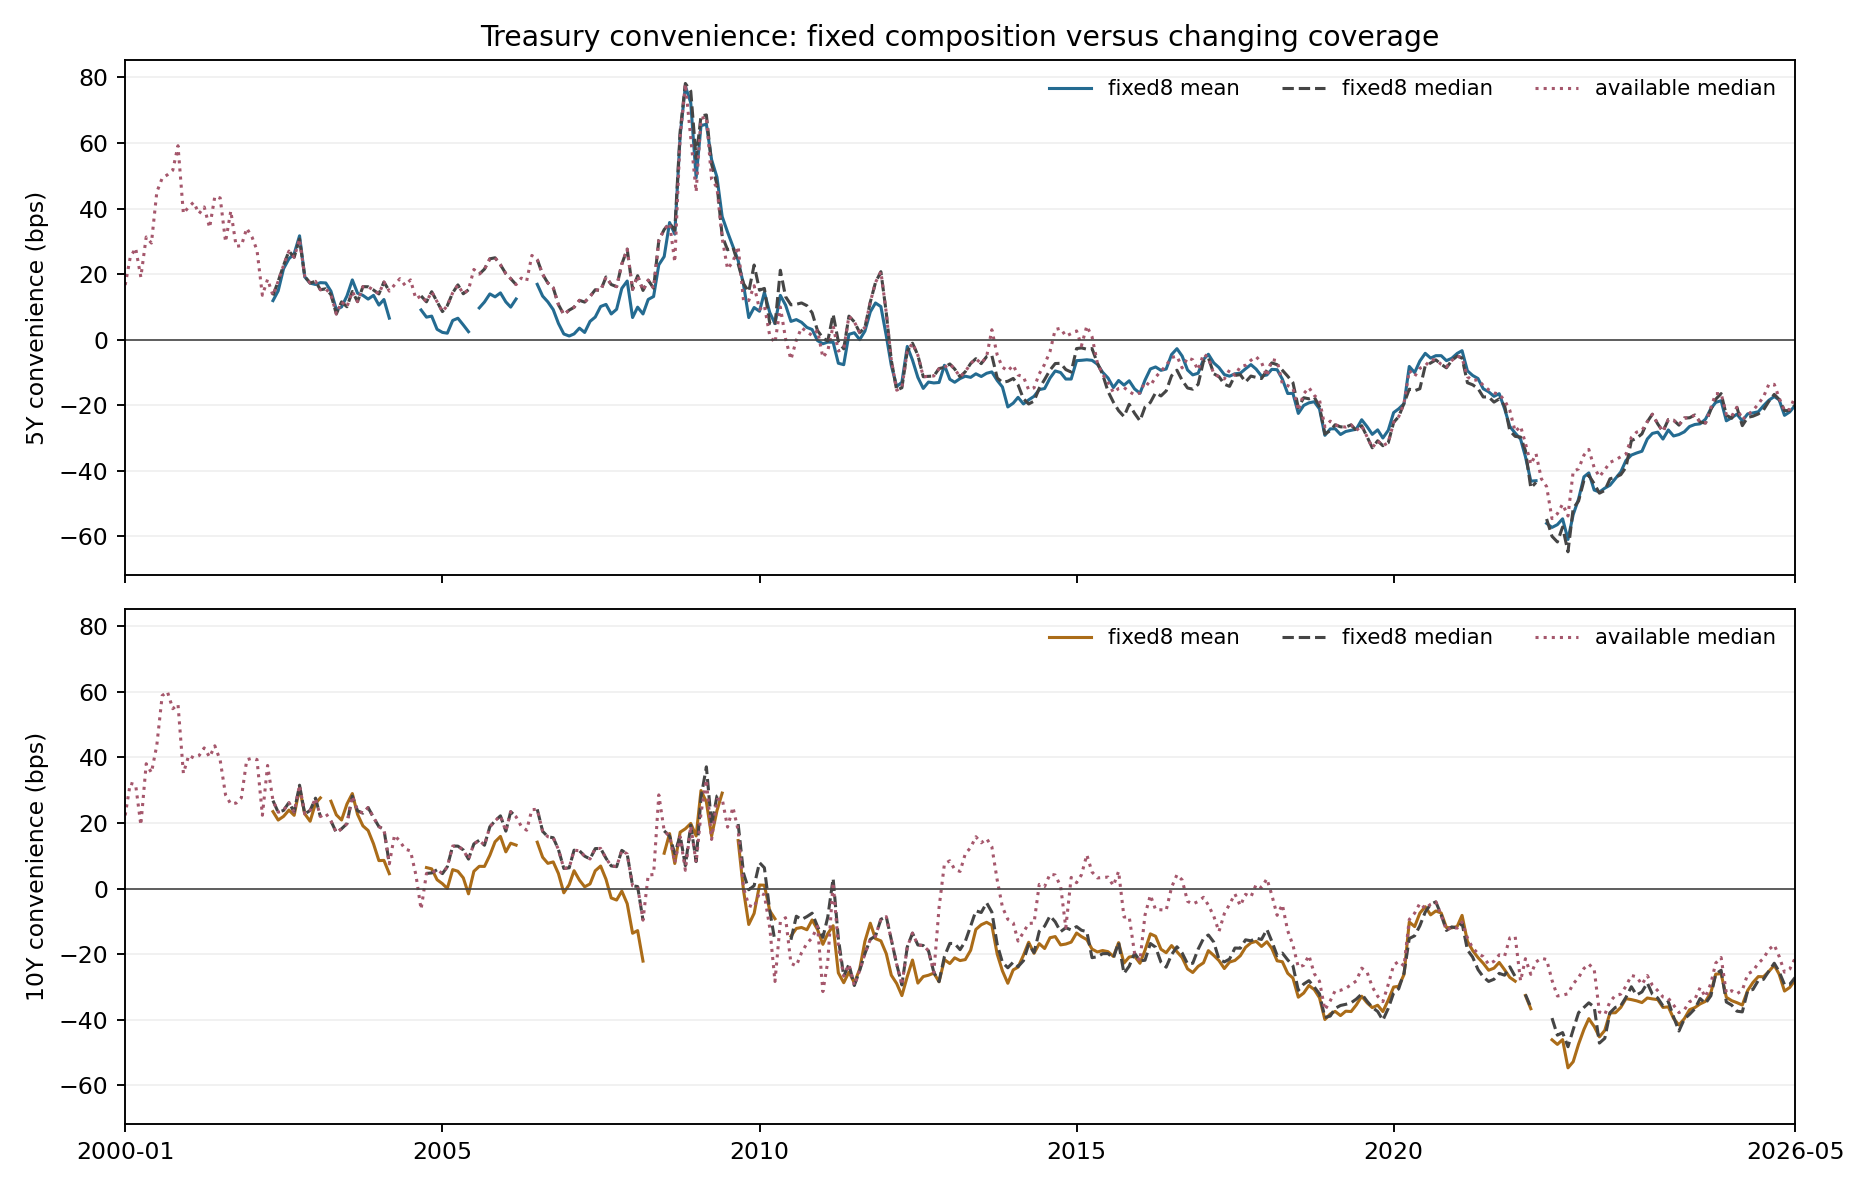

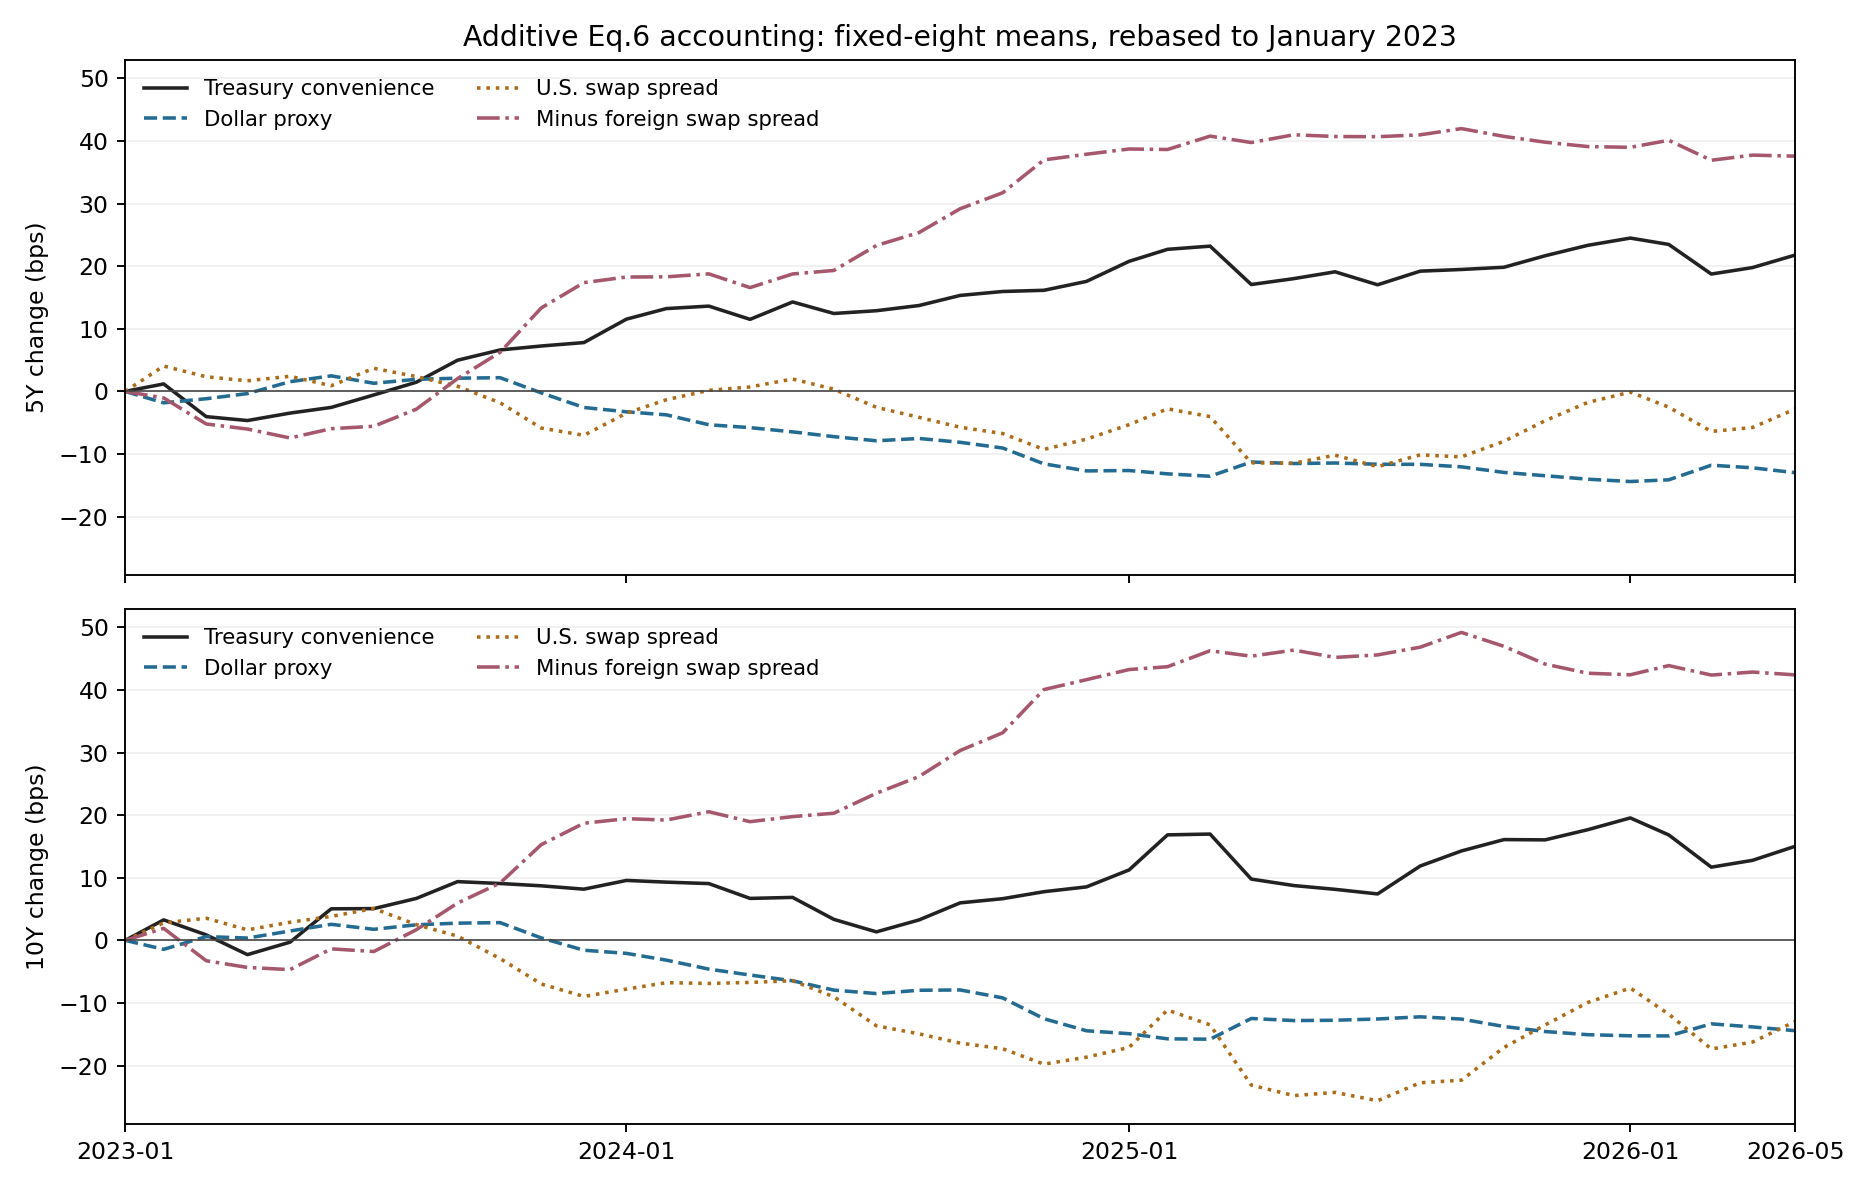

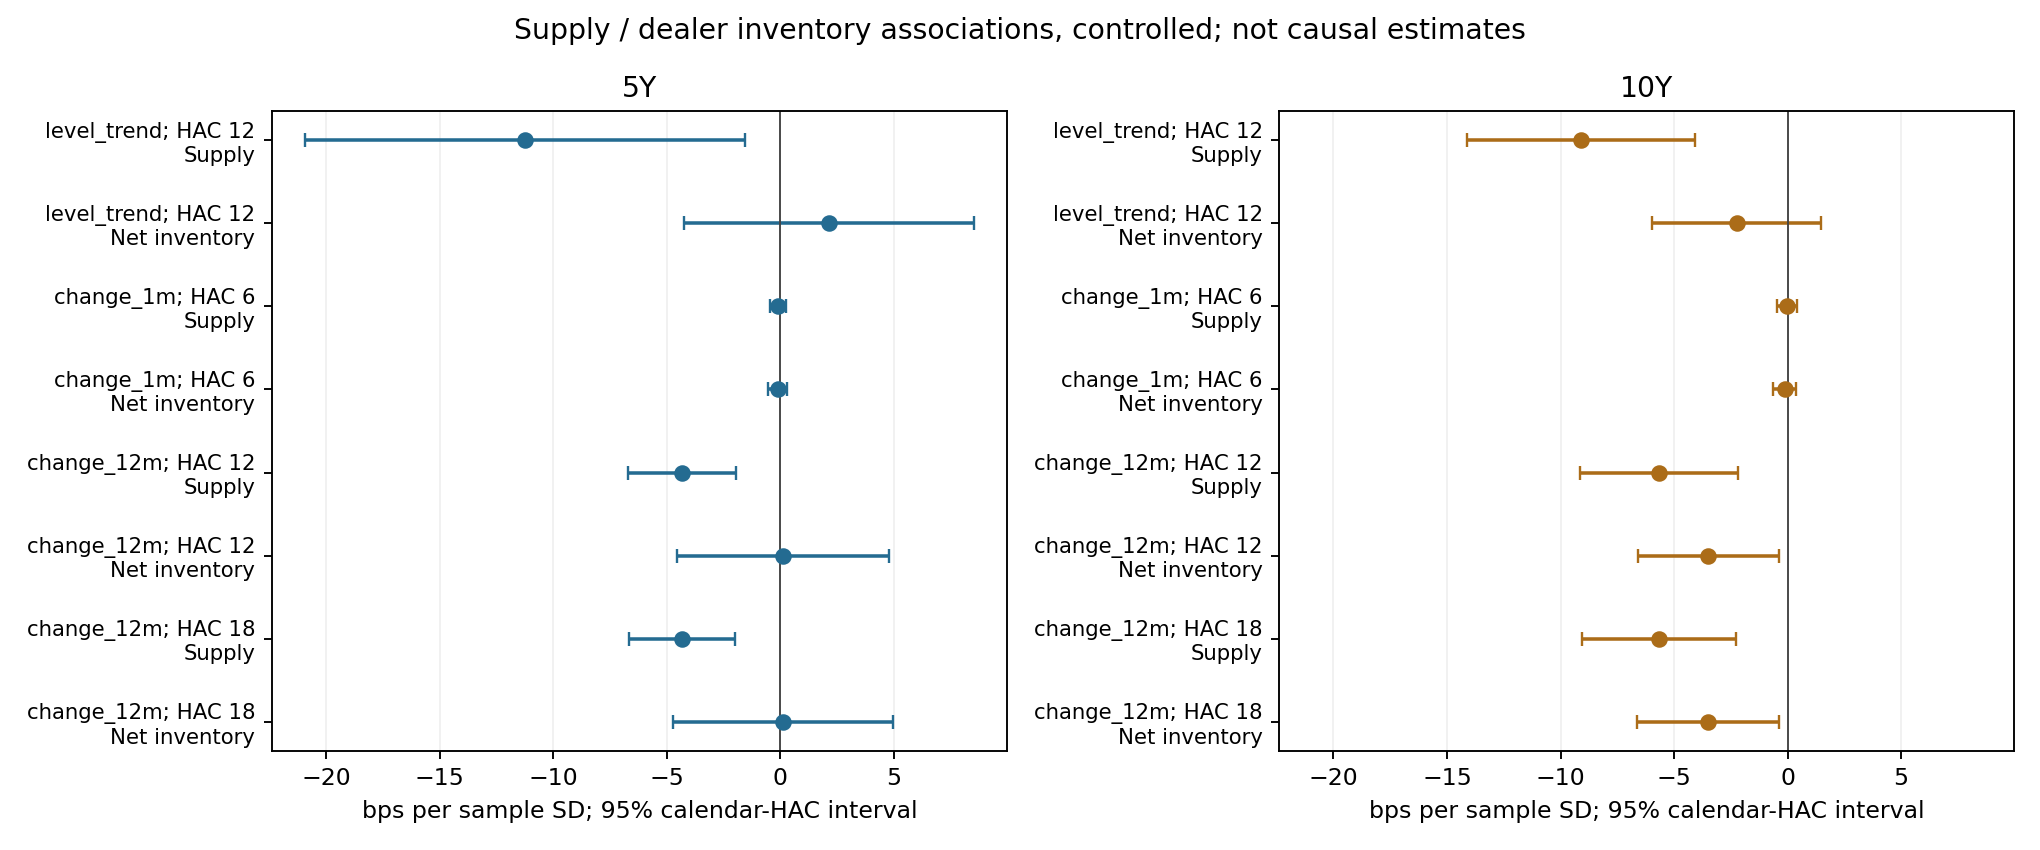

In [34]:
for name in ["treasury_interim_fixed_cohort.png", "treasury_interim_rebound_components.png", "treasury_interim_associations.png"]:
    display(Image(filename=str(FIGURE_DIR / name)))


### What the reviewed results say

1. **The decline survives a fixed-currency design.** On available complete months, fixed-eight mean 5Y convenience falls from about +12.53 bps (early window) to -30.53 bps (2021-2025), and 10Y from +13.89 to -33.42 bps. The size depends on aggregation and available months; this is not an exact full-sample Table 2 replication.
2. **The rebound is relative, not evidence that dollar specialness strengthened.** Comparing 2023 averages with 2026 Jan-May averages, 5Y convenience recovers +20.49 bps: dollar proxy -13.55, U.S. swap spread -3.82, minus foreign swap spread +37.86 bps. For 10Y: recovery +10.70 = -15.44 -13.54 +39.69. Foreign swap-spread compression is broad across all eight currencies. Its economic cause remains untested.
3. **Supply is a descriptive lead, not yet a maturity-specific causal mechanism.** Controlled annual changes associate one sample SD of nominal bucket supply with -4.34 bps (5Y; 95% calendar-HAC interval [-6.70,-1.97]) and -5.66 bps (10Y; [-9.13,-2.20]). Negative estimates persist under DKK exclusion, medians, HAC-18 and exclusion of COVID windows. One-month effects are weak; supply-share intervals include zero. This distinction argues against presenting the absolute-supply coefficient as proof of maturity-specific scarcity.
4. **General dealer-capacity evidence is not established.** The main 10Y inventory association is negative, but its interval includes zero when COVID windows are excluded or supply share replaces absolute supply. The 5Y inventory coefficient is not supported. Inventory is endogenous exposure, not measured capacity.

All intervals are asymptotic exploratory estimates; reported p-values are not adjusted for the sensitivity family. Identification, foreign supply/GDP controls, Fed holdings, and refreshed post-June-2026 quotes remain outside this interim extension. The standalone memo is `output/report/Treasury_Convenience_Interim_Results.md`.


## 15B. Why Did Foreign Swap Spreads Fall?

The next bounded question is whether the foreign-spread component moves because swaps fall, government yields rise, or both. This is a diagnostic extension to the replication, not a substitute for Eq.5 and not a causal test of QT.

For each country and tenor, on the **same raw daily observations**:

$$
\Delta s_i = 100\Delta y_i^{\mathrm{swap}} - 100\Delta y_i^{\mathrm{Govt}}.
$$

The comparison is fixed in advance: 2023 annual averages versus 2026 January-May averages. Alternatives are 2023 H2 and 2024 annual averages; every one-country exclusion is also shown. All 16 currency-tenor pairs have all 41 months, with at least 15 daily observations per month. Input variables and benchmark regimes remain unchanged over this recent window. This rules out a splice explanation, not all possible quote-quality issues.


    baseline excluded_currency tenor  n_currencies  negative_foreign_spreads  foreign_swap_bps  foreign_govt_yield_bps  usd_swap_bps  usd_govt_yield_bps  foreign_swap_spread_bps  us_swap_spread_bps  x_rf_raw_bps  x_govt_raw_bps  without_foreign_spread_change_bps
2023 average              none   10y             8                         8           -17.072                  22.616        19.468              33.011                  -39.688             -13.543       -15.442          10.703                            -28.985
2023 average              none    5y             8                         8           -53.180                 -15.317       -24.066             -20.244                  -37.863              -3.822       -13.552          20.488                            -17.375
Refresh tickers: 54 monthly country-tenor observations: 656


,currency,tenor,foreign_swap_bps,foreign_govt_yield_bps,foreign_swap_spread_bps,x_govt_raw_bps
0,AUD,10y,49.659,92.764,-43.105,33.532
1,AUD,5y,54.189,85.090,-30.902,29.288
2,CAD,10y,-29.075,7.831,-36.906,9.828
3,CAD,5y,-74.782,-44.082,-30.700,23.556
4,CHF,10y,-114.055,-69.738,-44.317,-20.673
5,CHF,5y,-133.417,-85.807,-47.611,9.843
6,DKK,10y,-15.681,9.888,-25.569,-13.451
7,DKK,5y,-49.172,-25.401,-23.771,-3.769
8,EUR,10y,-9.280,47.254,-56.534,20.576
9,EUR,5y,-42.600,11.163,-53.763,27.660


,baseline,excluded_currency,tenor,negative_foreign_spreads,foreign_swap_spread_bps,x_govt_raw_bps
0,2023 average,none,10y,8,-39.688,10.703
1,2023 average,none,5y,8,-37.863,20.488
2,2023 average,AUD,10y,7,-39.200,7.442
3,2023 average,AUD,5y,7,-38.857,19.231
4,2023 average,CAD,10y,7,-40.086,10.828
5,2023 average,CAD,5y,7,-38.886,20.050
6,2023 average,CHF,10y,7,-39.027,15.185
7,2023 average,CHF,5y,7,-36.470,22.009
8,2023 average,DKK,10y,7,-41.705,14.154
9,2023 average,DKK,5y,7,-39.876,23.953


,currency,tenor,regime,n_regimes,first_date,last_date,swap_variable,government_variable,floating_benchmark
0,AUD,10y,sofr,1,2023-01-03,2026-05-29,aud_ibor_irs_10y_adsw10q,aud_sofr_govt_10y_bv100127,3M Bank Bill
1,AUD,5y,sofr,1,2023-01-03,2026-05-29,aud_sofr_irs_5y_adswap5q,aud_sofr_govt_5y_bv050127,3M Bank Bill
2,CAD,10y,sofr,1,2023-01-03,2026-05-29,cad_sofr_irs_10y_cdso10,cad_sofr_govt_10y_bv100101,CORRA
3,CAD,5y,sofr,1,2023-01-03,2026-05-29,cad_sofr_irs_5y_cdso5,cad_sofr_govt_5y_bv050101,CORRA
4,CHF,10y,sofr,1,2023-01-03,2026-05-29,chf_sofr_irs_10y_sfsnt10,chf_sofr_govt_10y_bv100256,SARON Fixing (At Close)
5,CHF,5y,sofr,1,2023-01-03,2026-05-29,chf_sofr_irs_5y_sfsnt5,chf_sofr_govt_5y_bv050256,SARON Fixing (At Close)
6,DKK,10y,sofr,1,2023-01-03,2026-05-29,dkk_ibor_irs_10y_dksw10v3,dkk_sofr_govt_10y_bv100267,3M Cibor
7,DKK,5y,sofr,1,2023-01-03,2026-05-29,dkk_ibor_irs_5y_dksw5v3,dkk_sofr_govt_5y_bv050267,3M Cibor
8,EUR,10y,sofr,1,2023-01-03,2026-05-29,eur_sofr_irs_10y_eeswe10,eur_sofr_govt_10y_bv100910,ESTR
9,EUR,5y,sofr,1,2023-01-03,2026-05-29,eur_sofr_irs_5y_eeswe5,eur_sofr_govt_5y_bv050910,ESTR


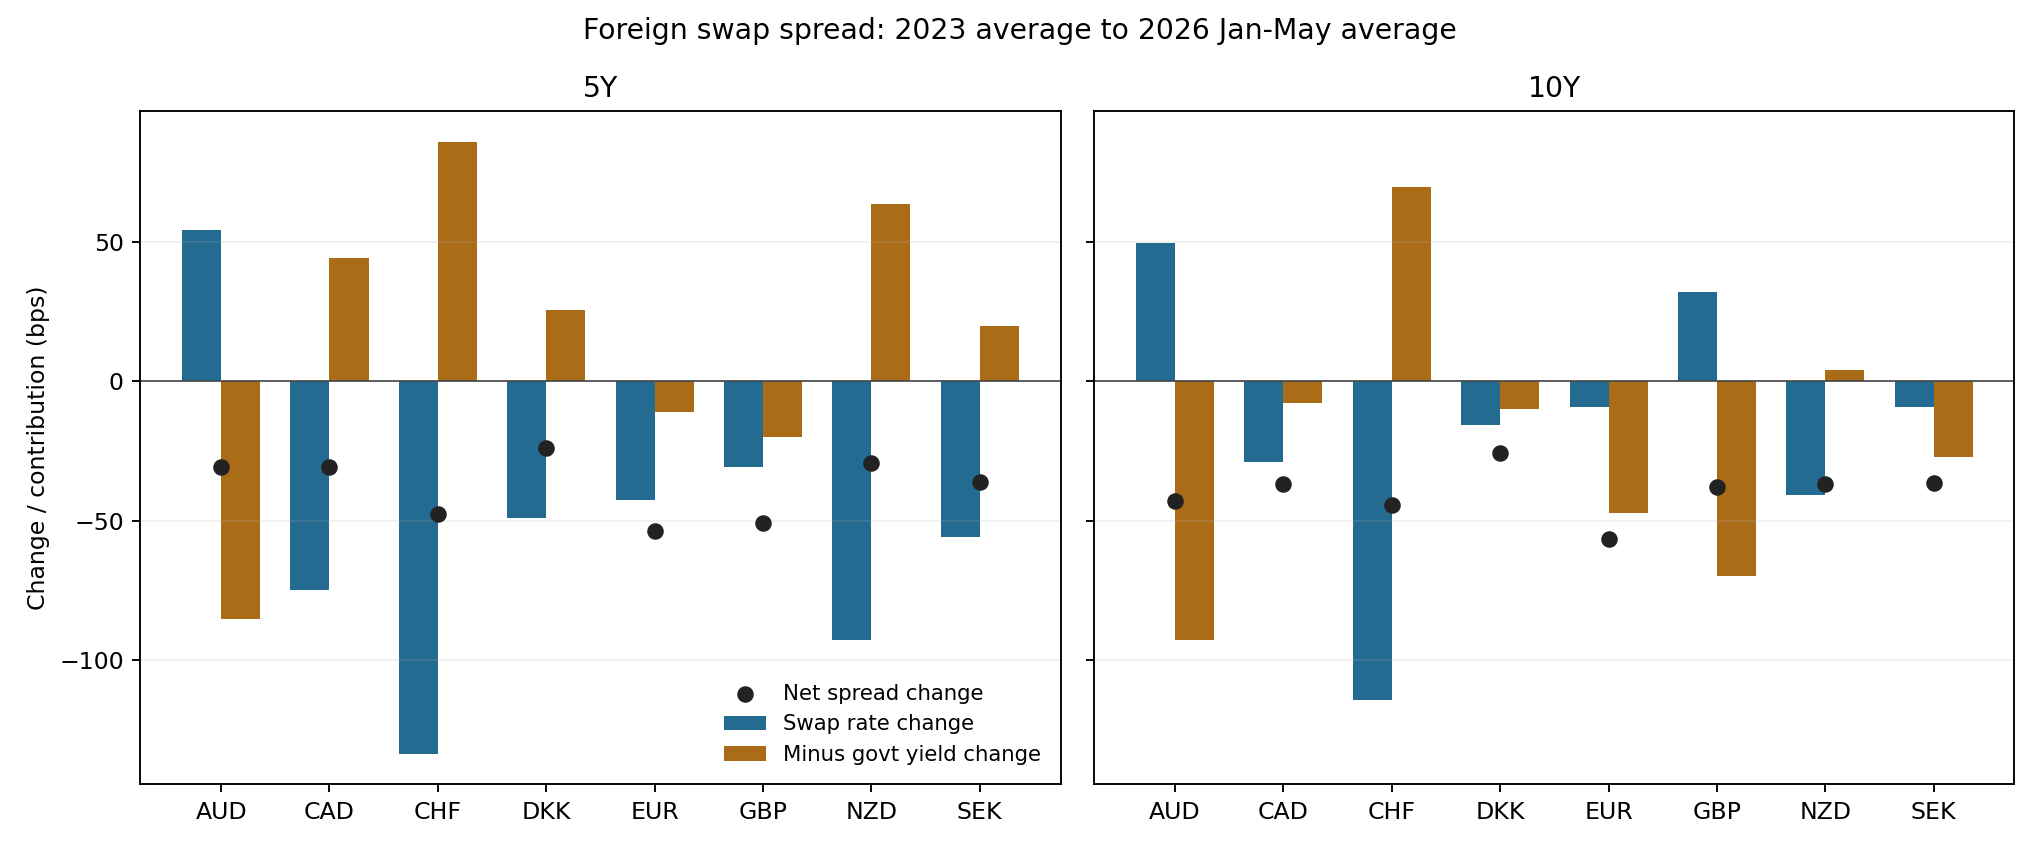

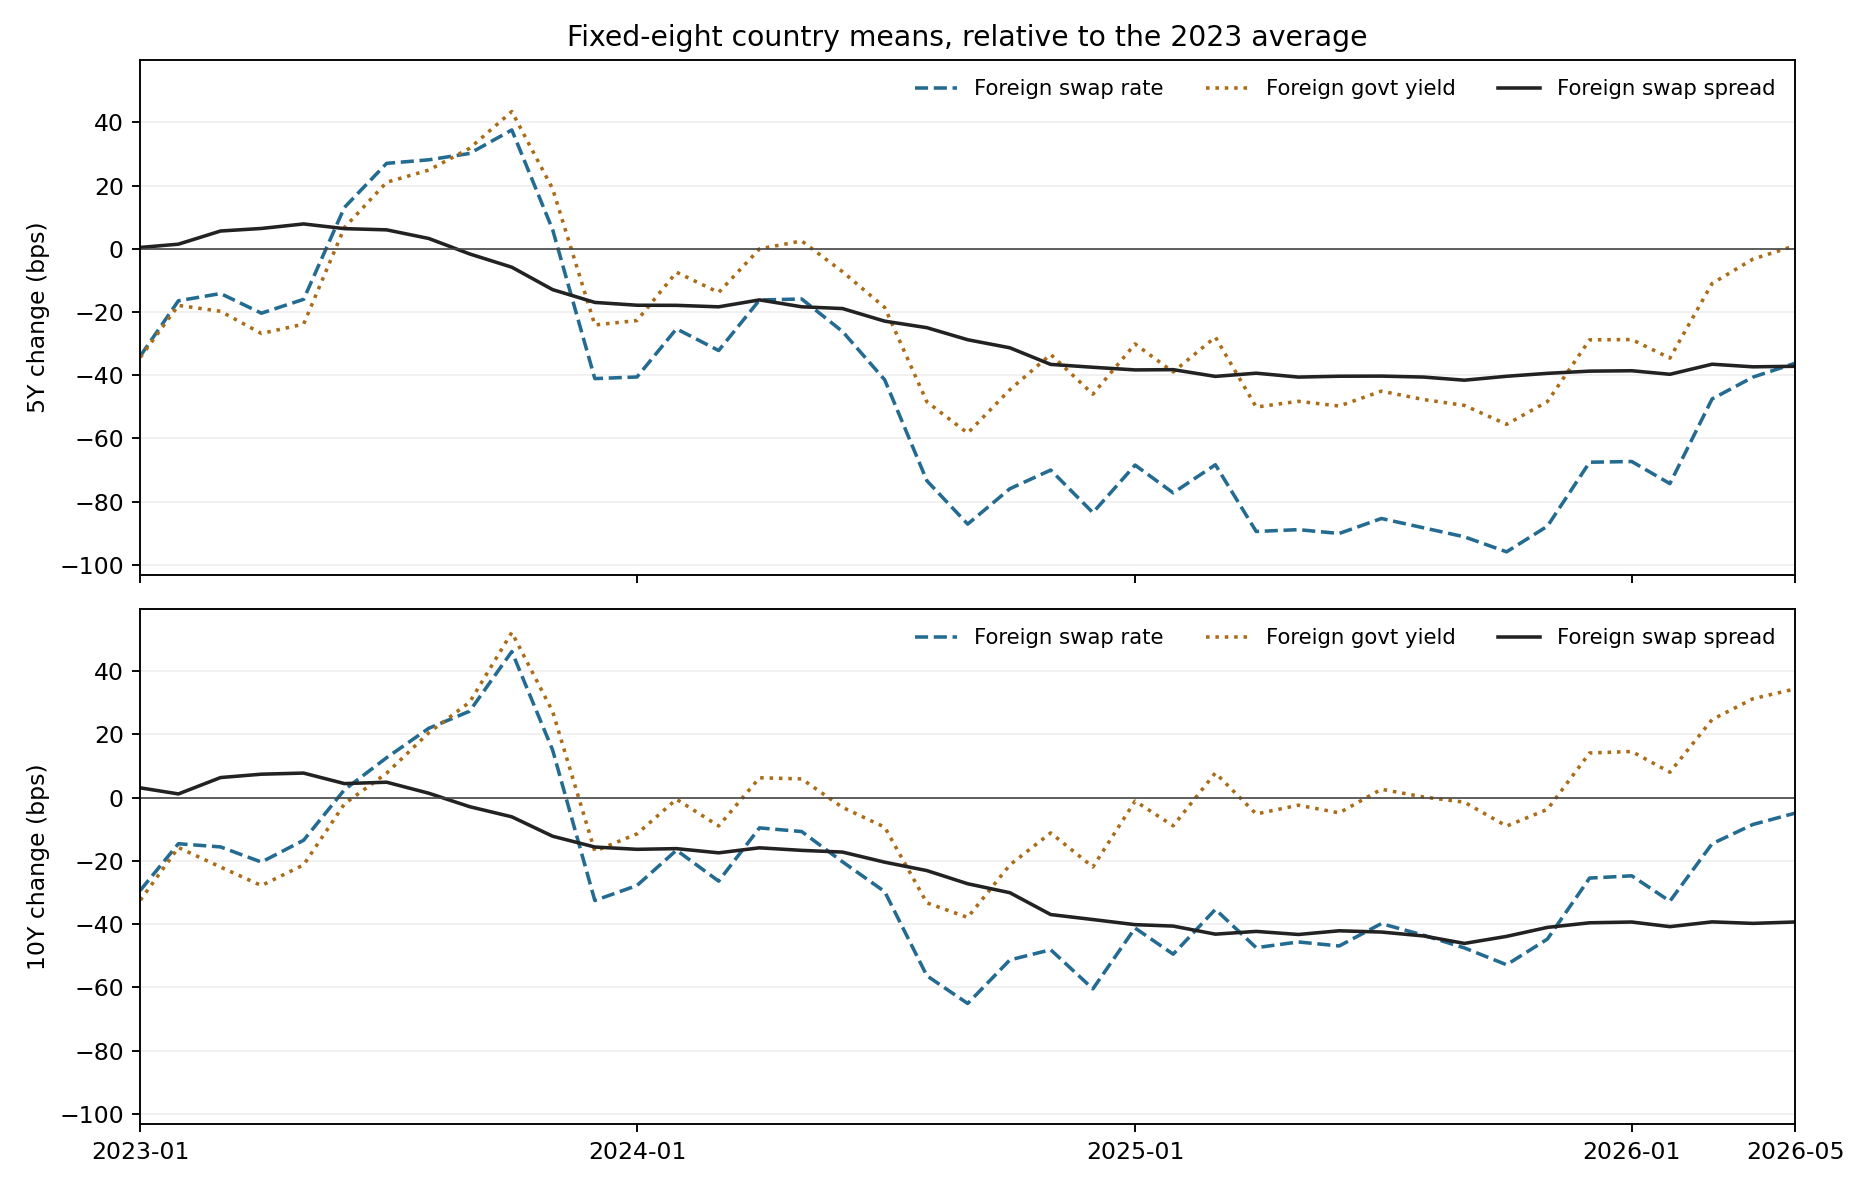

In [35]:
from src import analyze_foreign_swap_spread_rebound
analyze_foreign_swap_spread_rebound.main()
foreign_leg_changes = pd.read_csv(TABLE_DIR / "foreign_swap_spread_country_changes.csv")
foreign_leg_sensitivity = pd.read_csv(TABLE_DIR / "foreign_swap_spread_sensitivity.csv")
foreign_leg_audit = pd.read_csv(TABLE_DIR / "foreign_swap_spread_instrument_audit.csv")
assert foreign_leg_changes[["leg_bridge_error_bps", "eq6_bridge_error_bps"]].abs().max().max() < 1e-8
assert foreign_leg_audit.n_regimes.eq(1).all()
display(foreign_leg_changes[["currency", "tenor", "foreign_swap_bps", "foreign_govt_yield_bps",
                             "foreign_swap_spread_bps", "x_govt_raw_bps"]].round(3))
display(foreign_leg_sensitivity[["baseline", "excluded_currency", "tenor", "negative_foreign_spreads",
                                 "foreign_swap_spread_bps", "x_govt_raw_bps"]].round(3))
display(foreign_leg_audit)
for name in ["foreign_swap_spread_country_legs.png", "foreign_swap_spread_monthly_legs.png"]:
    display(Image(filename=str(FIGURE_DIR / name)))


### Findings and limits

- **5Y:** Foreign swap rates fall 53.18 bps while government yields fall only 15.32 bps. The spread falls 37.86 bps. **10Y:** Swap rates fall 17.07 bps while government yields rise 22.62 bps; the spread falls 39.69 bps.
- All eight currencies have falling foreign spreads under each of the three baseline windows. Removing any single currency retains a positive convenience rebound: 5Y +19.23 to +23.95 bps, 10Y +7.44 to +15.18 bps. This is a broad result, although absolute yield directions differ across countries.
- Holding the foreign-spread component unchanged, while retaining the other observed Eq.6 changes, would give -17.37 bps (5Y) and -28.99 bps (10Y), rather than the measured rebounds. This is an accounting exercise, **not** an identified equilibrium counterfactual.
- German/EUR and UK/GBP 5Y combine falling swaps with rising government yields. CHF has both legs falling, with swaps falling more. A common spread direction is not evidence for one common cause.
- The foreign benchmarks are heterogeneous. AUD/DKK/SEK are labeled term-bank rates; CAD/CHF/EUR/GBP are labeled overnight rates. NZD has conflicting OCR instrument-name / Bank-Bill floating-leg metadata and a tenor-basis adjustment; Section 15D retains this as REVIEW. A SOFR construction label does not make every foreign swap an OIS.

[BIS (December 2024)](https://www.bis.org/publications/negative-interest-rate-swap-spreads-signal-pressure-government-debt-absorption) already discusses negative international swap spreads and cash-bond absorption, repo/balance-sheet costs, and swap receiving demand. These are competing hypotheses, not causes established by our data. [ECB (November 2024)](https://www.ecb.europa.eu/press/blog/date/2024/html/ecb.blog241114~6a3182c0bd.en.html) also discusses QT and OIS term premia, so QT is not restricted to the cash-bond leg. Our incremental question is how foreign spread changes alter **relative, currency-hedged Treasury convenience**.

### Data and next mechanism test

No new Bloomberg inputs are necessary for the completed accounting result. The optional refresh list contains 54 already downloaded, non-empty PX_LAST tickers, from 2023 to the download date, for the fixed eight currencies and USD at 5Y/10Y. It refreshes the endpoint; it does not identify a mechanism.

Next obtain comparable German/UK nominal government-bond stock/net issuance and sovereign holdings of ECB/BoE, mainly from official public sources. Check valuation, units and security scope before constructing investor-absorbable stock. Then choose a bond-absorption or swap-flow hypothesis and a defensible identification design. Optional Bloomberg quote/curve/repo checks need DES/FLDS verification; generic benchmark bonds are not exact substitutes for constant-maturity BVAL curves.

Details: `output/report/Foreign_Swap_Spread_Rebound_Memo.md`. This is a descriptive extension; EM/3M expansion is not the next data priority.


## 15C. Final Study: Refreshed Quotes and September 2026 Results

### Scope and provenance

Equation 5 directly estimates government CIP from government yields and the Appendix swap-implied hedging premium. Equation 6 explains that estimate using the same raw legs. Its near-zero residual tests internal accounting, not an independent dollar-convenience estimate.

The 2026-10-09 refresh contains 54 exact ticker blocks. Seven CAD 10Y January 2023 quotations absent from the new download are retained from the old **identical-ticker** file, with provenance. No synthetic date rows or forward filling enter the analysis. Different quote sources such as DKK BLC3 and generic composites are not mixed.

Eight currencies (AUD, CAD, CHF, DKK, EUR, GBP, NZD, SEK), two tenors, and 45 complete months produce 720 country-tenor-months. Each monthly mean requires at least 15 paired daily observations and one benchmark regime. Equal-weight country means preserve the additive identities. October is incomplete and excluded.

The public V4 Data Appendix explicitly says the released dataset is **not identical** to the data used in published papers. We validate against its series and splice dates. This does not establish identical paper Table 2 counts, standard errors, or every original figure.

Combined-regime government-CIP checks pass 20/20. Separate-regime checks pass 39/40: DKK 5Y SOFR retains a CHECK label (correlation 0.978, MAE 1.04 bps). The combined match does not remove this narrower diagnostic limitation.


In [36]:
from src.refresh_treasury_5y10y import main as refresh_final_inputs
from src.analyze_treasury_final import main as analyze_final_study
import json

refresh_receipt = refresh_final_inputs()
final_summary = analyze_final_study()
display(pd.Series({k: final_summary[k] for k in [
    'complete_month_end', 'country_tenor_months', 'months_per_pair',
    'minimum_daily_quotes_per_month', 'gov_good_match', 'gov_total_checks',
    'gov_max_mae_bps', 'gov_min_corr', 'association_end']}))
display(pd.read_csv(TABLE_DIR / 'treasury_refresh_qc.csv'))
final_validation = pd.read_csv(TABLE_DIR / 'treasury_final_replication_validation.csv')
display(final_validation.groupby(['check_type', 'status']).size().rename('checks').reset_index())


{
  "source": "data/refresh/Foreign_Spread_5Y10Y_2026-10-09.xlsx",
  "sha256": "bdfb0fc1b213fbc640ab24bd75c6e9ddd0f7f97a63c7dde9e58725550ec2e3a2",
  "refresh_blocks": 54,
  "numeric_quotes": 51839,
  "retained_history_quotes": 7,
  "retained_variables": [
    "cad_sofr_irs_10y_cdso10"
  ],
  "min_series_end": "2026-10-08",
  "max_series_end": "2026-10-09",
  "max_history_revision_bps": 0.8399999999999963,
  "government_cip_good_matches": 20,
  "rho_diagnostic_good": 20,
  "eq6_max_residual_bps": 1.1368683772161605e-13,
  "notes": [
    "Historical fallback is an observed same-ticker quote, not forward fill.",
    "Only the fixed-eight SOFR-regime series are extended; JPY/NOK and other maturities remain baseline.",
    "The public benchmark ends in June 2025; later dates have no independent public match."
  ]
}


tenor  x_govt_raw_bps  x_rf_raw_bps  us_swap_spread_bps  foreign_swap_spread_bps
  10y          11.119       -15.198             -12.732                  -39.049
   5y          20.646       -13.165              -3.070                  -36.881
Complete months: 2026-09-30 ; country-tenor months: 720
           baseline             endpoint tenor  x_govt_raw_bps
2023 annual average 2026 Jan-May average   10y          10.703
2023 annual average 2026 Jan-May average    5y          20.488
2023 annual average 2026 Jan-Sep average   10y          11.119
2023 annual average 2026 Jan-Sep average    5y          20.646
2023 annual average      2026 Q3 average   10y          11.740
2023 annual average      2026 Q3 average    5y          20.667
2023 annual average       September 2026   10y          13.048
2023 annual average       September 2026    5y          19.893
    2023 H2 average 2026 Jan-May average   10y           7.327
    2023 H2 average 2026 Jan-May average    5y          17.065
    2023

complete_month_end                2026-09-30
country_tenor_months                     720
months_per_pair                           45
minimum_daily_quotes_per_month            16
gov_good_match                            20
gov_total_checks                          20
gov_max_mae_bps                     1.106547
gov_min_corr                        0.990624
association_end                   2026-05-31
dtype: object

,currency,variable,ticker,n_numeric,first_date,last_date,errors,min,max,unit,n_overlap,mae_bps,max_abs_revision_bps
0,USD,usd_sofr_govt_10y_bv100082,BV100082 BVLI INDEX,943,2023-01-03,2026-10-08,0,3.30430,5.33660,percent,855,0.000094,0.080
1,USD,usd_sofr_irs_10y_usosfr10,USOSFR10 BGN CURNCY,953,2023-01-03,2026-10-09,0,3.02225,4.91215,percent,862,0.000191,0.165
2,USD,usd_sofr_govt_5y_bv050082,BV050082 BVLI INDEX,943,2023-01-03,2026-10-08,0,3.34550,5.08650,percent,855,0.000164,0.140
3,USD,usd_sofr_irs_5y_usosfr5,USOSFR5 BGN CURNCY,953,2023-01-03,2026-10-09,0,3.10400,4.81048,percent,862,0.000267,0.230
4,AUD,aud_sofr_bs_10y_adbsqq10,ADBSQQ10 BGN CURNCY,978,2023-01-02,2026-10-09,0,-0.87500,13.00000,bps,888,0.000000,0.000
5,AUD,aud_sofr_govt_10y_bv100127,BV100127 BVLI INDEX,947,2023-01-03,2026-10-09,0,3.18960,5.41530,percent,858,0.000152,0.130
6,AUD,aud_ibor_irs_10y_adsw10q,ADSW10Q CURNCY,974,2023-01-02,2026-10-09,0,3.60900,5.30300,percent,882,0.000000,0.000
7,AUD,aud_sofr_bs_5y_adbsqq5,ADBSQQ5 BGN CURNCY,982,2023-01-02,2026-10-09,0,-3.75000,8.00000,bps,890,0.000000,0.000
8,AUD,aud_sofr_govt_5y_bv050127,BV050127 BVLI INDEX,947,2023-01-03,2026-10-09,0,2.82780,5.10860,percent,858,0.000221,0.190
9,AUD,aud_sofr_irs_5y_adswap5q,ADSWAP5Q CURNCY,972,2023-01-02,2026-10-09,0,3.26700,5.09150,percent,880,0.000000,0.000


,check_type,status,checks
0,eq6_identity_residual,IDENTITY_OK,40
1,rho_vs_public_combined,DIAGNOSTIC_GOOD,20
2,rho_vs_public_regime,DIAGNOSTIC_GOOD,40
3,x_govt_vs_public_combined,GOOD_MATCH,20
4,x_govt_vs_public_regime,CHECK,1
5,x_govt_vs_public_regime,GOOD_MATCH,39


### Refreshed accounting result

The comparison is **2023 annual average versus 2026 January-September average**, rather than a selected trough and peak. Treasury convenience rises approximately **20.65 bps at 5Y** and **11.12 bps at 10Y**. Levels remain negative relative to the hedged foreign bonds in the recent monthly chart.

Foreign swap spreads fall approximately **36.88 bps** and **39.05 bps**. Their negative sign in Equation 6 creates the positive accounting contribution. The dollar proxy and U.S. swap spread both move against the rebound. Under Equation 5, the government-yield differential falls, but the swap-implied forward premium falls further.

This is a relative-price result. A foreign government bond becoming cheaper relative to its local swap benchmark can increase measured relative UST convenience without an improvement in absolute U.S. safety or market liquidity.


,tenor,x_govt_raw_bps,x_rf_raw_bps,us_swap_spread_bps,foreign_swap_spread_bps,diff_y_raw_bps,rho_raw_bps
18,10y,11.119,-15.198,-12.732,-39.049,-20.388,-31.506
19,5y,20.646,-13.165,-3.070,-36.881,-8.765,-29.411


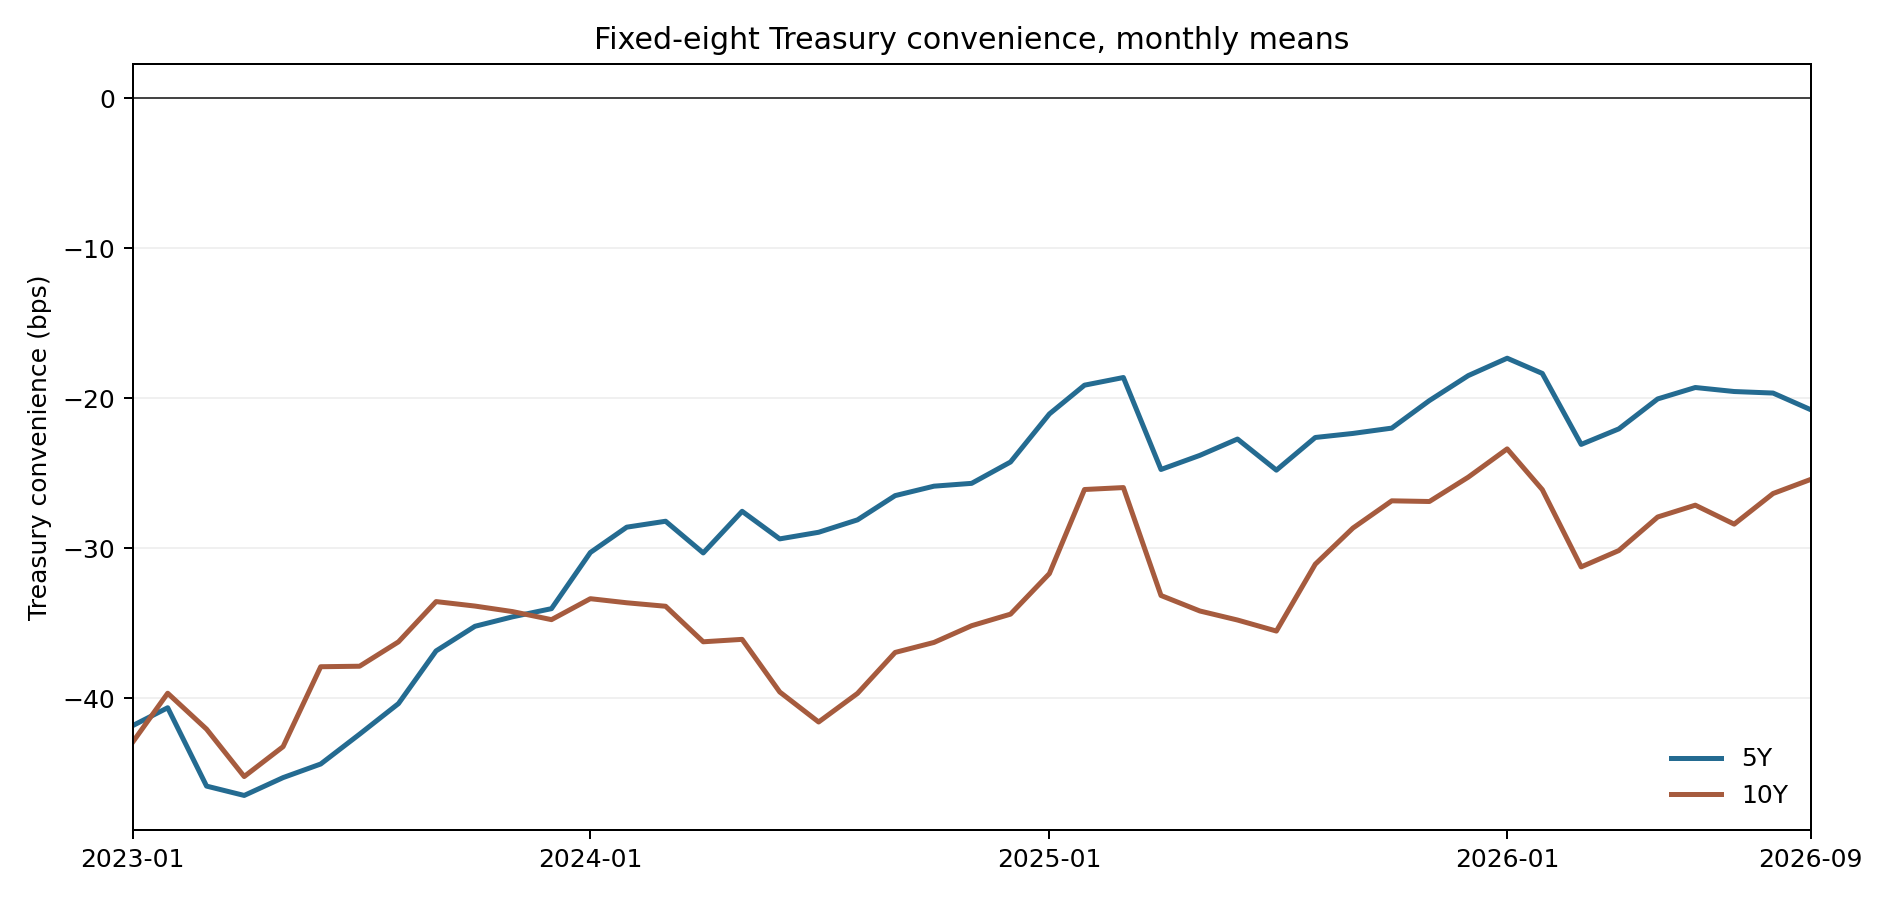

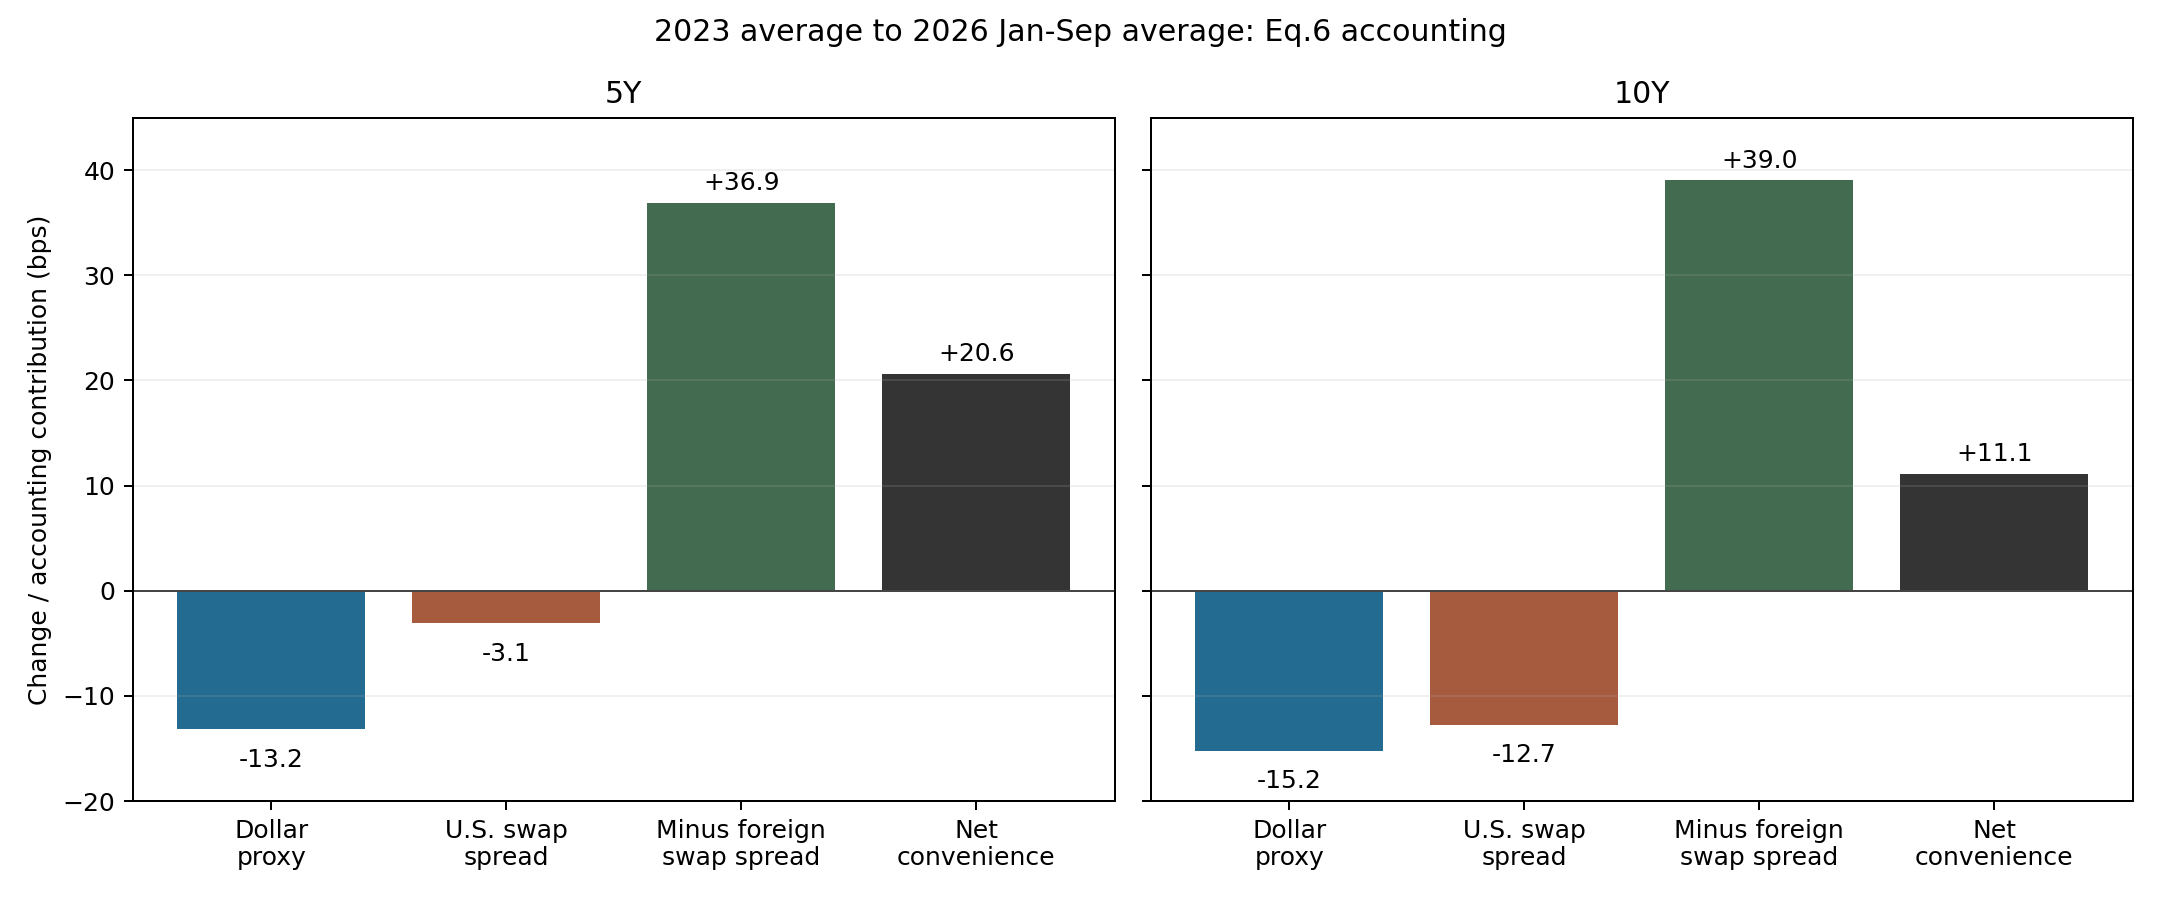

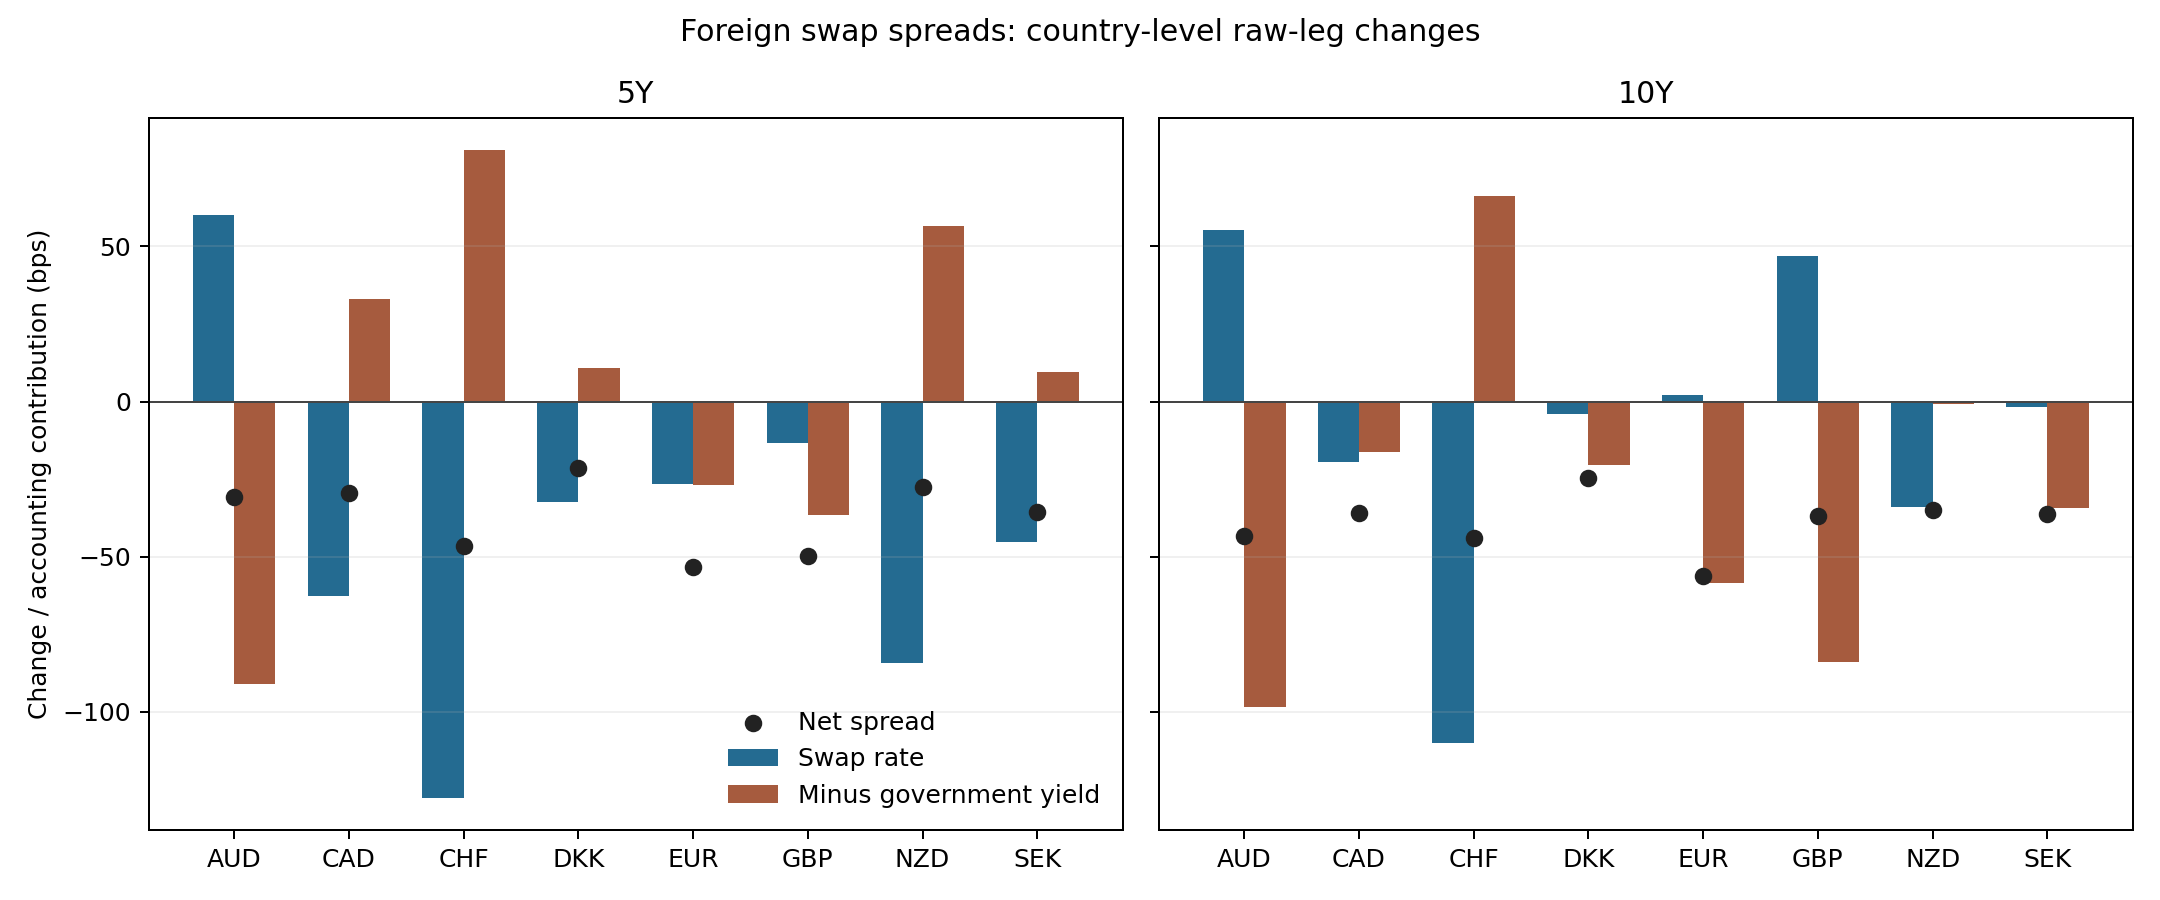

,currency,tenor,foreign_swap_bps,foreign_govt_yield_bps,foreign_swap_spread_bps,x_govt_raw_bps
16,AUD,10y,55.239,98.590,-43.351,35.586
17,AUD,5y,60.027,90.961,-30.934,30.791
18,CAD,10y,-19.625,16.349,-35.973,10.112
19,CAD,5y,-62.712,-33.184,-29.528,23.651
20,CHF,10y,-110.203,-66.167,-44.035,-21.451
21,CHF,5y,-127.756,-81.060,-46.696,9.445
22,DKK,10y,-3.937,20.576,-24.512,-12.677
23,DKK,5y,-32.349,-10.938,-21.411,-4.422
24,EUR,10y,2.201,58.511,-56.309,20.884
25,EUR,5y,-26.438,26.882,-53.320,27.841


In [37]:
final_changes = pd.read_csv(TABLE_DIR / 'treasury_final_country_changes.csv')
final_sensitivity = pd.read_csv(TABLE_DIR / 'treasury_final_rebound_sensitivity.csv')
final_primary = final_sensitivity[
    final_sensitivity.baseline.eq('2023 annual average') &
    final_sensitivity.endpoint.eq('2026 Jan-Sep average') &
    final_sensitivity.excluded_currency.eq('none')]
display(final_primary[['tenor', 'x_govt_raw_bps', 'x_rf_raw_bps',
    'us_swap_spread_bps', 'foreign_swap_spread_bps', 'diff_y_raw_bps', 'rho_raw_bps']].round(3))
for name in ['recent_convenience', 'rebound_accounting', 'foreign_legs']:
    display(Image(filename=str(FIGURE_DIR / f'treasury_final_{name}.png')))
display(final_changes[final_changes.baseline.eq('2023 annual average') &
    final_changes.endpoint.eq('2026 Jan-Sep average')][[
    'currency', 'tenor', 'foreign_swap_bps', 'foreign_govt_yield_bps',
    'foreign_swap_spread_bps', 'x_govt_raw_bps']].round(3))


### Sensitivity and uncertainty

We compare three baseline averages and four endpoint windows and remove each currency in turn. The mean rebound remains positive in every displayed baseline/endpoint comparison. All 16 country-tenor foreign spreads decline in the primary comparison, while individual convenience changes vary. These accounting checks are descriptive, not confidence intervals or equilibrium counterfactuals.

Foreign swap benchmarks remain heterogeneous: AUD bank-bill, DKK Cibor and SEK Stibor are term bank benchmarks; CAD/CHF/EUR/GBP are labeled overnight benchmarks. NZD's OCR-name / Bank-Bill metadata conflict remains unresolved (Section 15D). The SOFR label describes the USD construction and does not make every foreign rate an OIS.


,baseline,endpoint,tenor,x_govt_raw_bps,foreign_swap_spread_bps,negative_foreign_spread_changes
0,2023 annual average,2026 Jan-May average,10y,10.703,-39.688,8
1,2023 annual average,2026 Jan-May average,5y,20.488,-37.863,8
18,2023 annual average,2026 Jan-Sep average,10y,11.119,-39.049,8
19,2023 annual average,2026 Jan-Sep average,5y,20.646,-36.881,8
36,2023 annual average,2026 Q3 average,10y,11.740,-37.885,8
37,2023 annual average,2026 Q3 average,5y,20.667,-35.024,8
54,2023 annual average,September 2026,10y,13.048,-36.674,8
55,2023 annual average,September 2026,5y,19.893,-33.129,8
72,2023 H2 average,2026 Jan-May average,10y,7.327,-34.627,8
73,2023 H2 average,2026 Jan-May average,5y,17.065,-33.175,8


,min,max
tenor,,
10y,7.623,15.771
5y,19.197,24.227


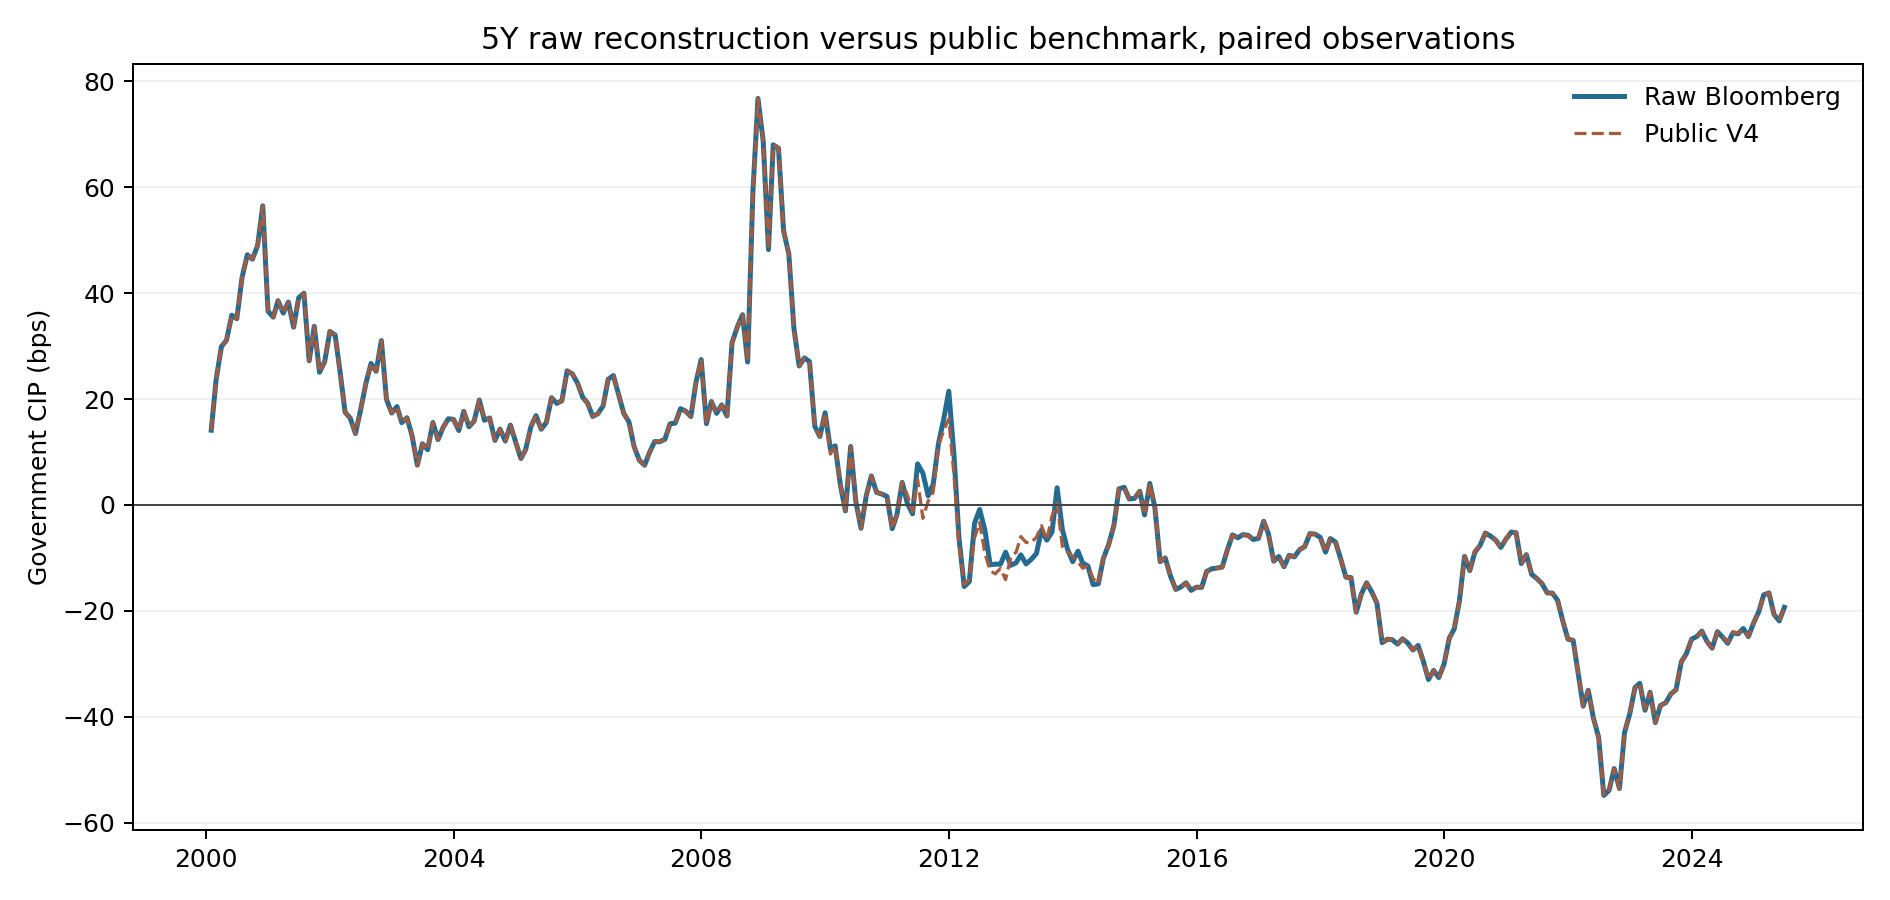

In [38]:
display(final_sensitivity[final_sensitivity.excluded_currency.eq('none')][[
    'baseline', 'endpoint', 'tenor', 'x_govt_raw_bps',
    'foreign_swap_spread_bps', 'negative_foreign_spread_changes']].round(3))
leave_one_out = final_sensitivity[
    final_sensitivity.baseline.eq('2023 annual average') &
    final_sensitivity.endpoint.eq('2026 Jan-Sep average') &
    final_sensitivity.excluded_currency.ne('none')]
display(leave_one_out.groupby('tenor').x_govt_raw_bps.agg(['min', 'max']).round(3))
display(Image(filename=str(FIGURE_DIR / 'treasury_final_validation_trend.png')))


### Supply and dealer-inventory associations

These regressions retain their **May 2026 endpoint**. The September accounting update does not extend unrefreshed explanatory variables. Annual changes, full-window benchmark/reporting-break exclusion, and calendar-aware HAC (12 months) reduce several obvious sources of spurious precision.

Higher same-maturity nominal Treasury supply has a negative conditional association with convenience in the primary annual-change specification. The relationship weakens under supply-share alternatives. Dealer inventory evidence is mixed: 5Y is inconclusive and the 10Y result weakens when COVID windows are excluded. Net positions measure inventory, not spare intermediation capacity. P-values are exploratory and not multiplicity-adjusted.


In [39]:
final_associations = pd.read_csv(TABLE_DIR / 'treasury_final_association_coefficients.csv')
primary_models = final_associations[
    final_associations.cohort.eq('fixed8_mean') &
    final_associations['transform'].eq('change_12m') &
    final_associations.supply_type.eq('trillion') &
    final_associations.episode.eq('all') & final_associations.hac_months.eq(12)]
display(primary_models[['tenor', 'variable', 'coef_bps_per_sd',
    'ci95_low', 'ci95_high', 'n_months', 'first_month', 'last_month']].round(3))
display(pd.read_csv(TABLE_DIR / 'treasury_final_association_audit.csv'))


,tenor,variable,coef_bps_per_sd,ci95_low,ci95_high,n_months,first_month,last_month
4,5y,supply_trillion_5y,-4.336,-6.703,-1.970,104,2014-04-30,2026-05-31
5,5y,dealer_billion_5y,0.119,-4.555,4.793,104,2014-04-30,2026-05-31
36,10y,supply_trillion_10y,-5.662,-9.121,-2.203,104,2014-04-30,2026-05-31
37,10y,dealer_billion_10y,-3.489,-6.591,-0.388,104,2014-04-30,2026-05-31


,tenor,cohort,transform,supply_type,episode,n_complete_months,n_excluded_regime_windows,calendar_span_months,n_design_columns
0,5y,fixed8_mean,level_trend,trillion,all,156,1,158,13
1,5y,fixed8_mean,change_1m,trillion,all,151,6,157,8
2,5y,fixed8_mean,change_12m,trillion,all,104,54,146,8
3,5y,fixed8_mean,change_12m,share_pct,all,104,54,146,8
4,5y,fixed8_mean,change_12m,trillion,exclude_covid_window,88,70,146,8
5,5y,fixed8_median,level_trend,trillion,all,156,1,158,13
6,5y,fixed8_median,change_1m,trillion,all,151,6,157,8
7,5y,fixed8_median,change_12m,trillion,all,104,54,146,8
8,5y,fixed7_mean,level_trend,trillion,all,157,1,158,13
9,5y,fixed7_mean,change_1m,trillion,all,152,6,157,8


### Final interpretation and delivery

The strongest new result is that the recent relative-convenience rebound survives the September refresh and follows foreign swap-spread compression in the additive accounting. The outright foreign yield directions differ by country. This distinction matters more than attributing the change to a single dollar or U.S. Treasury narrative.

[BIS (2024)](https://www.bis.org/publications/negative-interest-rate-swap-spreads-signal-pressure-government-debt-absorption) discusses government-debt absorption, financing/balance-sheet costs and swap receiving demand as competing spread channels. [ECB (2024)](https://www.ecb.europa.eu/press/blog/date/2024/html/ecb.blog241114~6a3182c0bd.en.html) discusses QT and OIS term premia. These sources motivate hypotheses, not causal conclusions from our panel.

The final presentation and its PDF are in `output/final/`. Native chart data derive from `treasury_final_presentation_data.json`. Findings and provenance are in `output/report/Treasury_Convenience_Final_Findings.md`, `treasury_refresh_receipt.json`, and the final CSV tables. Raw licensed Bloomberg inputs must not be publicly redistributed.


## 15D. Post-Meeting Research: Benchmark Comparability and Risk Sensitivity

### Question and boundary

Charlotte and Qiyuan discussed the work with Rob Reider and Calin Ciordas. Calin highlighted raw-data replication and benchmark credit components; Rob suggested credit-risk variables as a possible extension. The approved proposal retains the rebound question and asks whether the higher convenience level is accompanied by improved behavior when risk rises.

**October 23 snapshot, retained for audit.** This section uses the earlier exports and tests weekly changes against $\Delta\log(\mathrm{VIX})$. Equity and IG/HY inputs were absent from those exports; Section 15E now uses the newly supplied files and supersedes this section for current risk conclusions. The original paper already uses sovereign CDS in later tables; adding CDS is not automatically a new contribution.

The research sequence is: measurement audit, benchmark-cohort sensitivity, matched-sample risk extension, then revisit supply/dealer associations. New Bloomberg templates request a few focused series, not a repeat of the full CIP download.


In [40]:
from src.analyze_post_meeting_research import main as analyze_post_meeting
post_meeting_summary = analyze_post_meeting()
display(pd.Series(post_meeting_summary))
benchmark_audit = pd.read_csv(TABLE_DIR / 'post_meeting_benchmark_definition_audit.csv')
display(benchmark_audit[['currency', 'tenor', 'ticker', 'floating_leg', 'name', 'interpretation']])


{
  "updated": "2026-10-23",
  "scope": "Existing data only; VIX-only diagnostic, not complete Table 5 or the HY extension",
  "risk_last_week": "2026-05-29",
  "vix_last_observation": "2026-06-03",
  "nzd_definition_status": "REVIEW: OCR-name versus Bank-Bill metadata conflict; no raw formula changed",
  "all_cohort_rebounds_positive": true,
  "all_cohort_foreign_spreads_decline": true,
  "risk_model_fits": 40,
  "risk_coefficient_rows": 72,
  "missing_series": [
    "SPX Index",
    "LUACOAS Index",
    "LF98OAS Index"
  ],
  "caveats": [
    "Not exact paper replication: fixed-eight means, joint-date weekly means, VIX only.",
    "A positive level rebound does not establish improved risk sensitivity or absolute safe-haven quality.",
    "Pre/post interactions are conditional associations; regime and episode composition can confound them.",
    "HAC 26-week intervals and p-values are exploratory and not multiplicity adjusted."
  ]
}


updated                                                                      2026-10-23
scope                                 Existing data only; VIX-only diagnostic, not c...
risk_last_week                                                               2026-05-29
vix_last_observation                                                         2026-06-03
nzd_definition_status                 REVIEW: OCR-name versus Bank-Bill metadata con...
all_cohort_rebounds_positive                                                       True
all_cohort_foreign_spreads_decline                                                 True
risk_model_fits                                                                      40
risk_coefficient_rows                                                                72
missing_series                                [SPX Index, LUACOAS Index, LF98OAS Index]
caveats                               [Not exact paper replication: fixed-eight mean...
dtype: object

,currency,tenor,ticker,floating_leg,name,interpretation
0,AUD,10y,ADSW10Q CURNCY,3M Bank Bill,AUD SWAP (QTRLY) 10 YR,Term bank benchmark per supplied metadata
1,AUD,5y,ADSWAP5Q CURNCY,3M Bank Bill,AUD SWAP 5 YR,Term bank benchmark per supplied metadata
2,CAD,10y,CDSO10 CURNCY,CORRA,CAD SWAP 10 YR,Overnight benchmark per supplied metadata
3,CAD,5y,CDSO5 CURNCY,CORRA,CAD SWAP 5 YR,Overnight benchmark per supplied metadata
4,CHF,10y,SFSNT10 CURNCY,SARON Fixing (At Close),CHF SWAP 10 YR,Overnight benchmark per supplied metadata
5,CHF,5y,SFSNT5 CURNCY,SARON Fixing (At Close),CHF SWAP 5 YR,Overnight benchmark per supplied metadata
6,DKK,10y,DKSW10V3 BLC3 CURNCY,3M Cibor,DKK SWAP (VS 3 MO) 10 YR (ALTERNATIVE SOURCE),Term bank benchmark per supplied metadata
7,DKK,5y,DKSW5V3 BLC3 CURNCY,3M Cibor,DKK SWAP (VS 3 MO) 5 YR (ALTERNATIVE SOURCE),Term bank benchmark per supplied metadata
8,EUR,10y,EESWE10 CURNCY,ESTR,EUR SWAP 10 YR,Overnight benchmark per supplied metadata
9,EUR,5y,EESWE5 CURNCY,ESTR,EUR SWAP 5 YR,Overnight benchmark per supplied metadata


### Benchmark uncertainty does not explain away the rebound

NZD's `NDSO5/NDSO10` names refer to OCR, but their supplement floating-leg labels say Bank Bill. The construction also uses `NZBBCO5/NZBBCO10` tenor basis. We retain the raw formula and public-series match; the economic label remains **REVIEW** until terminal DES confirms the rate and basis legs.

Excluding NZD preserves the 2023-average to 2026-January-September rebound: about **20.63 bps (5Y)** and **9.09 bps (10Y)**. Excluding both NZD and DKK also preserves it. The overnight-metadata subset and term-bank-metadata subset each show positive rebounds and declining foreign spreads. These are descriptive cohort checks, not an experiment isolating credit risk.

An additional NZD sensitivity defines a term-equivalent swap benchmark as the downloaded OCR candidate plus the signed tenor-basis adjustment. Adding that adjustment to **both** the benchmark-CIP proxy and the foreign swap spread leaves Eq.5 / Eq.6 Treasury convenience unchanged. The change reallocates about **0.58 bps (5Y)** and **0.41 bps (10Y)** between the fixed-eight components over this comparison. This is an algebraic sensitivity, not a claim that the alternative convention is correct.


,cohort,tenor,n_currencies,x_govt_raw_bps,x_rf_raw_bps,us_swap_spread_bps,foreign_swap_spread_bps
0,fixed8,10y,8,11.119,-15.198,-12.732,-39.049
1,fixed8,5y,8,20.646,-13.165,-3.070,-36.881
2,exclude_NZD,10y,7,9.090,-17.818,-12.726,-39.634
3,exclude_NZD,5y,7,20.632,-14.523,-3.063,-38.217
4,exclude_NZD_DKK,10y,6,12.718,-16.715,-12.721,-42.154
5,exclude_NZD_DKK,5y,6,24.807,-13.154,-3.057,-41.018
6,overnight_metadata4,10y,4,4.121,-26.493,-12.723,-43.337
7,overnight_metadata4,5y,4,21.916,-19.879,-3.056,-44.851
8,term_metadata3,10y,3,15.716,-6.250,-12.731,-34.697
9,term_metadata3,5y,3,18.920,-7.380,-3.071,-29.371


,tenor,x_govt_raw_bps,x_rf_raw_bps,us_swap_spread_bps,foreign_swap_spread_bps,adjustment_bps,aligned_x_rf_change_bps,aligned_foreign_spread_change_bps,fixed8_component_reallocation_bps
0,10y,25.320,3.138,-12.771,-34.952,3.279,6.417,-31.673,0.410
1,5y,20.746,-3.664,-3.123,-27.533,4.629,0.965,-22.904,0.579


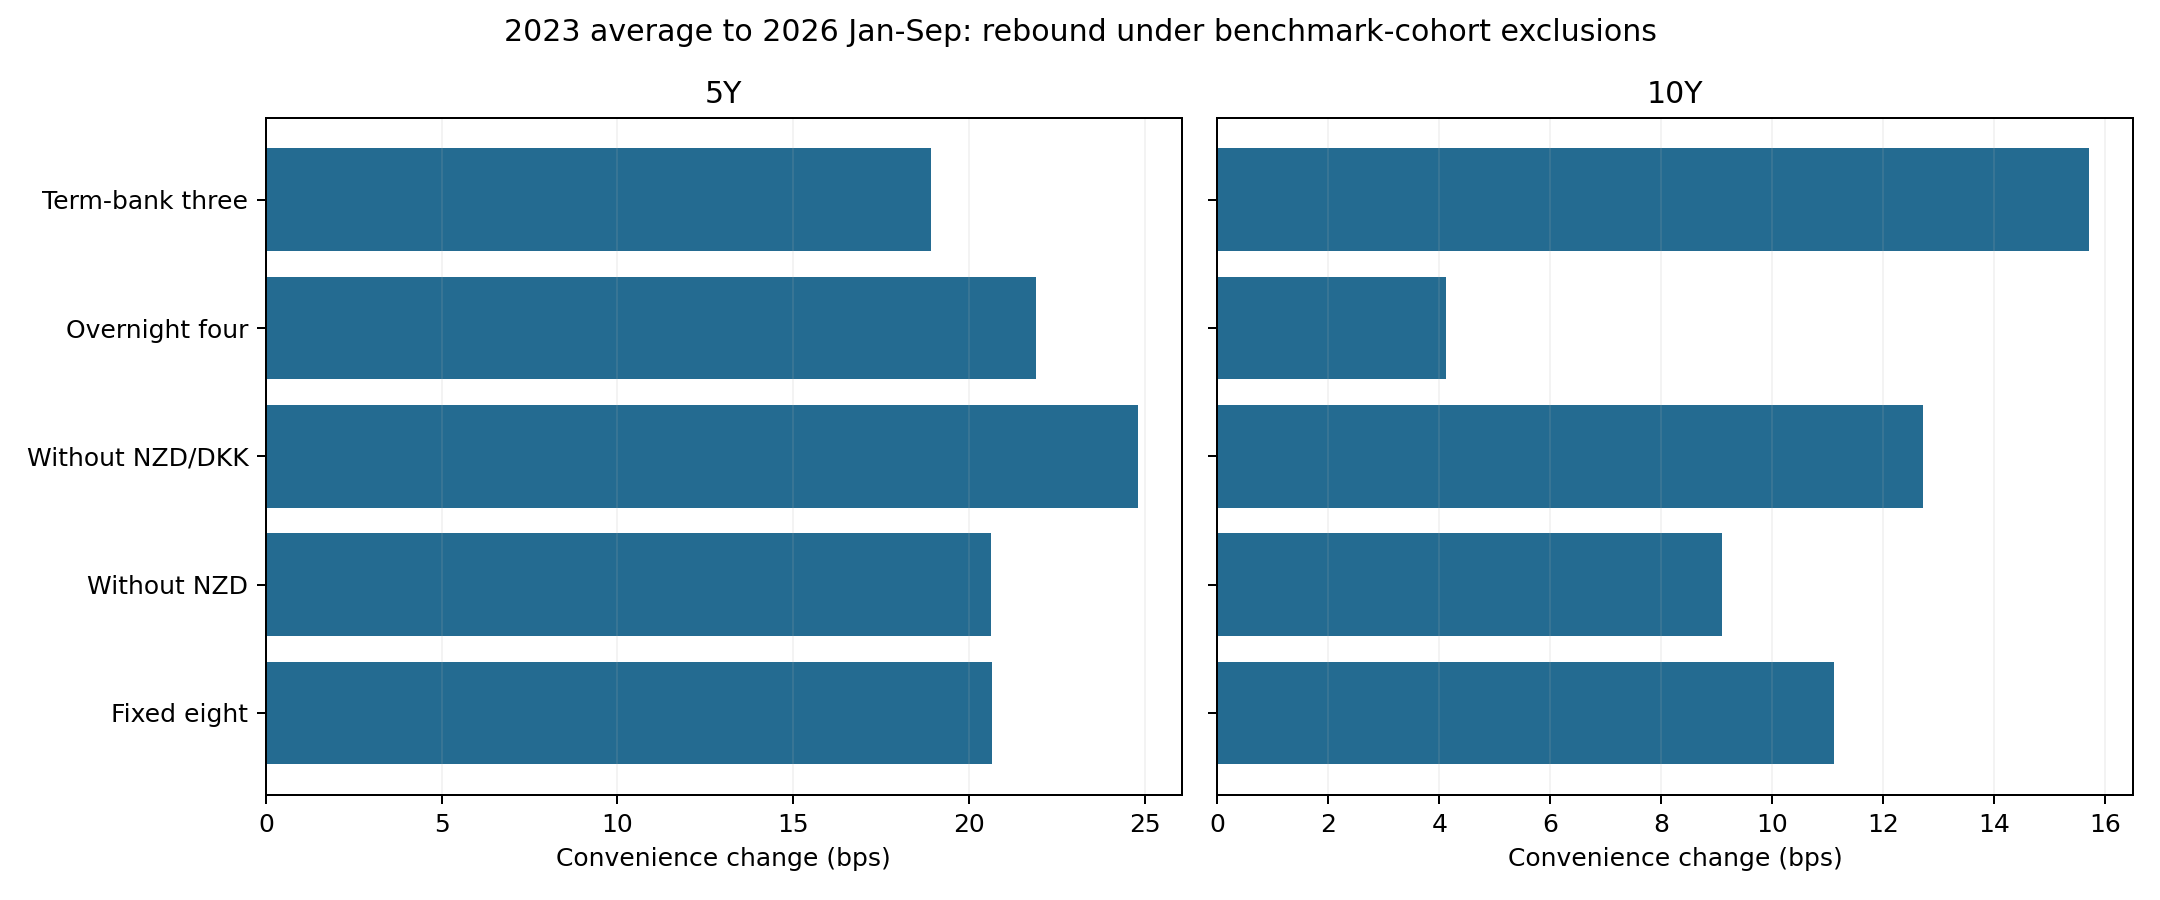

In [41]:
benchmark_sensitivity = pd.read_csv(TABLE_DIR / 'post_meeting_benchmark_sensitivity.csv')
display(benchmark_sensitivity[['cohort', 'tenor', 'n_currencies', 'x_govt_raw_bps',
    'x_rf_raw_bps', 'us_swap_spread_bps', 'foreign_swap_spread_bps']].round(3))
display(pd.read_csv(TABLE_DIR / 'post_meeting_nzd_component_sensitivity.csv').round(3))
display(Image(filename=str(FIGURE_DIR / 'post_meeting_benchmark_sensitivity.png')))


### Weekly VIX diagnostic

Use fixed-eight equal-country means calculated on **the same daily observations as VIX**. A week needs at least three joint trading days and one regime signature. Weekly means are differenced on a complete Friday calendar; missing weeks and benchmark-transition weeks are not bridged or filled. The last complete available week is **May 29, 2026**, not September. Annual/monthly rebound windows and weekly risk windows remain distinct.

For each tenor, estimate the same-sample regressions for Treasury convenience and its three Eq.6 components, using 26-week calendar-aware Bartlett HAC. The coefficient identity must also reconcile. Period splits follow the paper's 2010-2015 / 2016-2020 / 2021-onward structure, but our fixed-eight means, joint-date coverage and extended endpoint differ from the paper. These are directional replication diagnostics, not exact Table 5 cells.

The pooled pre/post-2023 model includes regime intercepts and a VIX interaction. A second interaction model restricts the sample to the latest common benchmark regime. Interaction confidence intervals test the coefficient difference directly; significance in one period and not another is not itself evidence of a change.


,tenor,model,contrast,beta_bps_per_log_vix,ci95_low,ci95_high,n_weeks,n_pre2023,n_post2023,first_week,last_week
0,10y,2010-2015,beta_vix,3.237,-1.092,7.565,298,298,0,2010-01-15,2015-12-25
4,10y,2016-2020,beta_vix,-1.690,-3.565,0.184,259,259,0,2016-01-01,2020-12-25
8,10y,2021-latest,beta_vix,-3.945,-5.952,-1.937,240,83,157,2021-01-15,2026-05-29
12,10y,post2023_interaction,pre2023_beta,0.022,-2.180,2.224,797,640,157,2010-01-15,2026-05-29
13,10y,post2023_interaction,post2023_beta,-4.048,-5.960,-2.135,797,640,157,2010-01-15,2026-05-29
14,10y,post2023_interaction,beta_change,-4.069,-6.975,-1.164,797,640,157,2010-01-15,2026-05-29
24,10y,recent_regime_interaction,pre2023_beta,-6.014,-13.940,1.911,184,27,157,2022-06-17,2026-05-29
25,10y,recent_regime_interaction,post2023_beta,-4.048,-5.974,-2.121,184,27,157,2022-06-17,2026-05-29
26,10y,recent_regime_interaction,beta_change,1.967,-5.931,9.864,184,27,157,2022-06-17,2026-05-29
36,5y,2010-2015,beta_vix,5.203,1.571,8.835,309,309,0,2010-01-15,2015-12-25


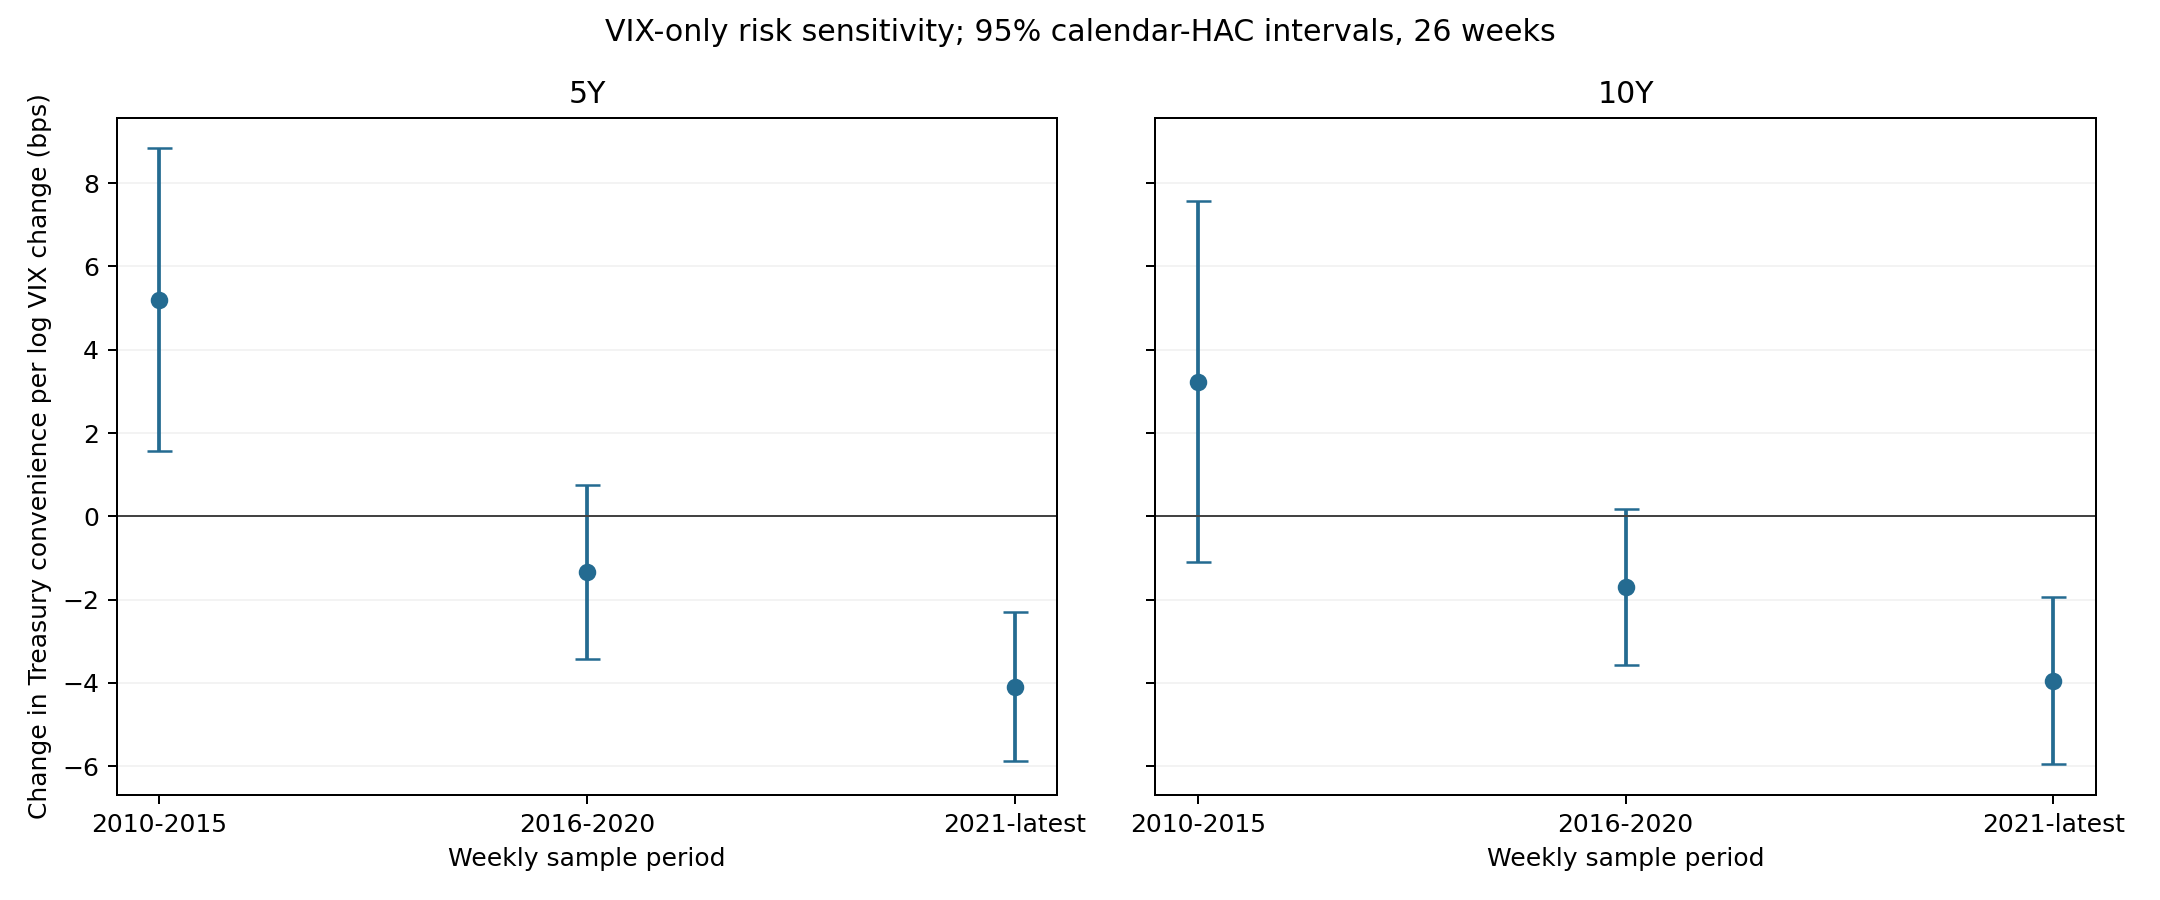

,tenor,outcome,beta_bps_per_log_vix,ci95_low,ci95_high
13,10y,x_govt_raw_bps,-4.048,-5.960,-2.135
16,10y,x_rf_raw_bps,1.490,0.593,2.386
19,10y,us_swap_spread_bps,-3.877,-7.197,-0.556
22,10y,foreign_swap_spread_bps,1.661,-0.403,3.725
49,5y,x_govt_raw_bps,-4.003,-5.972,-2.033
52,5y,x_rf_raw_bps,1.633,0.975,2.292
55,5y,us_swap_spread_bps,-2.859,-5.280,-0.438
58,5y,foreign_swap_spread_bps,2.777,0.985,4.569


In [42]:
vix_models = pd.read_csv(TABLE_DIR / 'post_meeting_vix_risk_models.csv')
gov_risk = vix_models[vix_models.outcome.eq('x_govt_raw_bps')]
display(gov_risk[['tenor', 'model', 'contrast', 'beta_bps_per_log_vix',
    'ci95_low', 'ci95_high', 'n_weeks', 'n_pre2023', 'n_post2023',
    'first_week', 'last_week']].round(3))
display(Image(filename=str(FIGURE_DIR / 'post_meeting_vix_sensitivity.png')))
display(vix_models[vix_models.model.eq('post2023_interaction') &
    vix_models.contrast.eq('post2023_beta')][[
    'tenor', 'outcome', 'beta_bps_per_log_vix', 'ci95_low', 'ci95_high']].round(3))


### Interpretation and next empirical test

**The level rebound is not evidence that risk-off behavior has recovered.** Post-2023 VIX coefficients for Treasury convenience are approximately **-4.00 (5Y)** and **-4.05 (10Y)** bps per unit log-VIX change, with exploratory 95% HAC intervals below zero. A 10% VIX increase corresponds to about **-0.38/-0.39 bps** of relative convenience change in this bivariate diagnostic, not a causal stress response.

On these same regression dates, the dollar/basis proxy has positive VIX loadings (about **+1.63/+1.49** at 5Y/10Y), while U.S. swap spreads have negative loadings (**-2.86/-3.88**) and foreign swap spreads positive loadings (**+2.78/+1.66**). The Eq.6 coefficient bridge reconciles. The 10Y foreign-spread interval includes zero. Thus an average-level rebound driven by foreign-spread compression can coexist with negative risk-off convenience exposure; long-window level accounting and weekly risk covariation answer different questions.

Claims about *improvement versus before 2023* are more fragile: the long-history interaction is negative, but the latest-regime-only comparison points toward a less-negative 5Y beta and an inconclusive 10Y change. The latter has only about half a year of pre-2023 weekly observations. Hence the defensible finding is that convenience levels rebounded while recent VIX exposure remains negative; the magnitude and direction of a structural beta shift are not settled.

Next download `SPX Index`, `LUACOAS Index` (IG OAS candidate), `LF98OAS Index` (HY OAS candidate), and refresh `VIX Index` through September 2026. MOVE/BBDXY refreshes are optional robustness inputs. Confirm index definitions and percentage-point/basis-point units at the terminal; these credit indices are not yet confirmed as the original paper's exact IG series. Fit VIX/equity/IG and nested +HY models on **identical dates**, report HAC intervals, incremental fit and stability, and preserve a common recent-regime sensitivity. Do not infer an exogenous credit shock from HY OAS.

The NZD template refreshes OCR, Bank-Bill swap and tenor-basis candidates on matched dates; DES definitions still require human confirmation. No raw formula should be selected merely because it maximizes a public-series match. Foreign supply/QT work remains conditional future work, not the immediate priority.


## 15E. November Data: Matched-Sample Credit-Risk Extension

### Inputs and scope

The two returned Bloomberg workbooks contain **12 numeric series / 31,329 quotes** and successful cached NAME/identifier responses. Observations end September 30, 2026. Original files are archived under `data/refresh/risk_extension_2026-11-02/` with SHA-256 receipts; spreadsheet text is treated as data, never executable instructions.

SPX is the price index. We provisionally interpret the downloaded LUACOAS/LF98OAS levels as percentage-point OAS and multiply changes by 100 to express bps. The manual DES/unit cells remain blank. R-squared, VIX loadings and tests of a credit coefficient are invariant to a constant rescaling of that credit regressor, but the numerical per-bp coefficient depends on the unit convention. Neither index has been established as the original paper's exact IG series.

The validated CIP outcome panel is unchanged. The new factors and both comparison cohorts use the same joint daily dates. We require all six risk inputs to be observed, including optional MOVE/BBDXY, to keep all displayed specifications on one calendar. Weekly means require at least three joint dates and one regime signature; differences never bridge missing weeks or benchmark transitions. The incomplete week containing September 30 is excluded. The last complete week is **September 25**, with **173/172 post-2023 observations at 5Y/10Y**.


In [43]:
from src.analyze_credit_risk_extension import main as analyze_credit_risk
credit_summary = analyze_credit_risk()
display(pd.Series({k: credit_summary[k] for k in [
    'updated', 'numeric_series', 'numeric_quotes', 'last_quote',
    'last_complete_risk_week', 'nzd_status', 'unit_convention', 'outcome_snapshot']}))
credit_qc = pd.read_csv(TABLE_DIR / 'credit_risk_download_qc.csv')
display(credit_qc[['sheet', 'ticker', 'live_name', 'expected_unit', 'n_numeric',
    'first_date', 'last_date', 'n_errors', 'unit_status']])


{
  "updated": "2026-11-02",
  "sources": [
    {
      "path": "data/refresh/risk_extension_2026-11-02/Risk_Extension_Bloomberg_BDH_Template.xlsx",
      "sha256": "10c71211fbe041d626926b0f67d84908343d750981e942e2a38f5c01201f48c8"
    },
    {
      "path": "data/refresh/risk_extension_2026-11-02/NZD_Benchmark_Check_Bloomberg_BDH_Template.xlsx",
      "sha256": "866e9b01e2a2733eb904e68bca0408d3fe485db9a1eca38172bb6975319d998e"
    }
  ],
  "numeric_series": 12,
  "numeric_quotes": 31329,
  "last_quote": "2026-09-30",
  "last_complete_risk_week": "2026-09-25",
  "regression_fits": 304,
  "coefficient_rows": 1600,
  "unit_convention": "IG/HY raw percentage points converted x100 to bps; manual unit cells still blank",
  "nzd_status": "OIS/3M names resolved by terminal BDP; detailed DES and pricing conventions remain open",
  "outcome_snapshot": "2026-10-09 CIP snapshot unchanged; new market factors and NZD diagnostics only",
  "caveats": [
    "Not full/exact paper Table 5 replication: f

updated                                                           2026-11-02
numeric_series                                                            12
numeric_quotes                                                         31329
last_quote                                                        2026-09-30
last_complete_risk_week                                           2026-09-25
nzd_status                 OIS/3M names resolved by terminal BDP; detaile...
unit_convention            IG/HY raw percentage points converted x100 to ...
outcome_snapshot           2026-10-09 CIP snapshot unchanged; new market ...
dtype: object

,sheet,ticker,live_name,expected_unit,n_numeric,first_date,last_date,n_errors,unit_status
0,SPX,SPX Index,S&P 500 INDEX,index points,4211,2010-01-04,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
1,VIX,VIX Index,Cboe Volatility Index,index points,4244,2010-01-04,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
2,IG_OAS,LUACOAS Index,Bloomberg US Agg Corporate Avg,percentage points candidate,4221,2010-01-04,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
3,HY_OAS,LF98OAS Index,Bloomberg US Corporate High Yi,percentage points candidate,4221,2010-01-04,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
4,MOVE,MOVE Index,MOVE,index points,4278,2010-01-01,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
5,BBDXY,BBDXY Index,BBG US Dollar Spot,index points,4303,2010-01-04,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
6,OCR_5Y,NDSO5 Curncy,NZD SWAP OIS 5Y,percentage points,974,2023-01-02,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
7,BANK_5Y,NDSWAP5 Curncy,NZD SWAP SA(V 3M) 5Y,percentage points,971,2023-01-02,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
8,TBS_5Y,NZBBCO5 Curncy,NZD BS (3M VS OIS) 5Y,basis points,978,2023-01-02,2026-09-30,0,Manual DES/unit cells blank; provisional recor...
9,OCR_10Y,NDSO10 Curncy,NZD SWAP OIS 10Y,percentage points,977,2023-01-02,2026-09-30,0,Manual DES/unit cells blank; provisional recor...


### Question and estimators

Following the mentor suggestion, test whether HY adds information after VIX, equity and IG, rather than searching for a significant new variable. On identical dates, compare:

$$
\Delta x_t = \alpha + \beta_V\Delta\log VIX_t
 + \beta_E\Delta\log SPX_t + \beta_I\Delta IG_t + \varepsilon_t,
$$

with the nested model adding $\beta_H\Delta HY_t$. A VIX-only specification is a reference; MOVE and dollar-index changes provide a further robustness specification. These are conditional associations, not identified credit shocks. OAS uses a Treasury reference curve and can share mechanical drivers with swap spreads.

We retain 2010-2015, 2016-2020 and 2021-2025 comparisons, plus the post-2023 extension. The fixed-eight and excluding-NZD cohorts keep identical observation dates. Inference uses calendar-aware HAC at 26 weeks, with 13-week sensitivity for recent models. Interactions allow **all included risk slopes** to change after 2023, rather than forcing non-VIX slopes to remain constant. P-values/intervals are exploratory and not multiplicity-adjusted. No in-sample fit improvement is described as forecasting performance.


,tenor,spec,factor,beta,ci95_low,ci95_high,p_exploratory,n_weeks
897,10y,VIX_only,dlog_vix,-3.8893,-5.6863,-2.0923,0.0000,172
907,10y,VIX_equity_IG,dlog_vix,-2.7889,-5.6985,0.1207,0.0603,172
908,10y,VIX_equity_IG,spx_return,13.9406,-9.8063,37.6875,0.2499,172
909,10y,VIX_equity_IG,d_ig_bps,0.0199,-0.0287,0.0686,0.4215,172
932,10y,plus_HY,dlog_vix,-2.6691,-5.5026,0.1643,0.0648,172
933,10y,plus_HY,spx_return,11.9047,-14.7420,38.5515,0.3812,172
934,10y,plus_HY,d_ig_bps,0.0386,-0.0238,0.1009,0.2251,172
935,10y,plus_HY,d_hy_bps,-0.0083,-0.0395,0.0229,0.6022,172
966,10y,plus_HY_controls,dlog_vix,-3.0361,-5.5444,-0.5279,0.0177,172
967,10y,plus_HY_controls,spx_return,9.3912,-14.1159,32.8984,0.4336,172


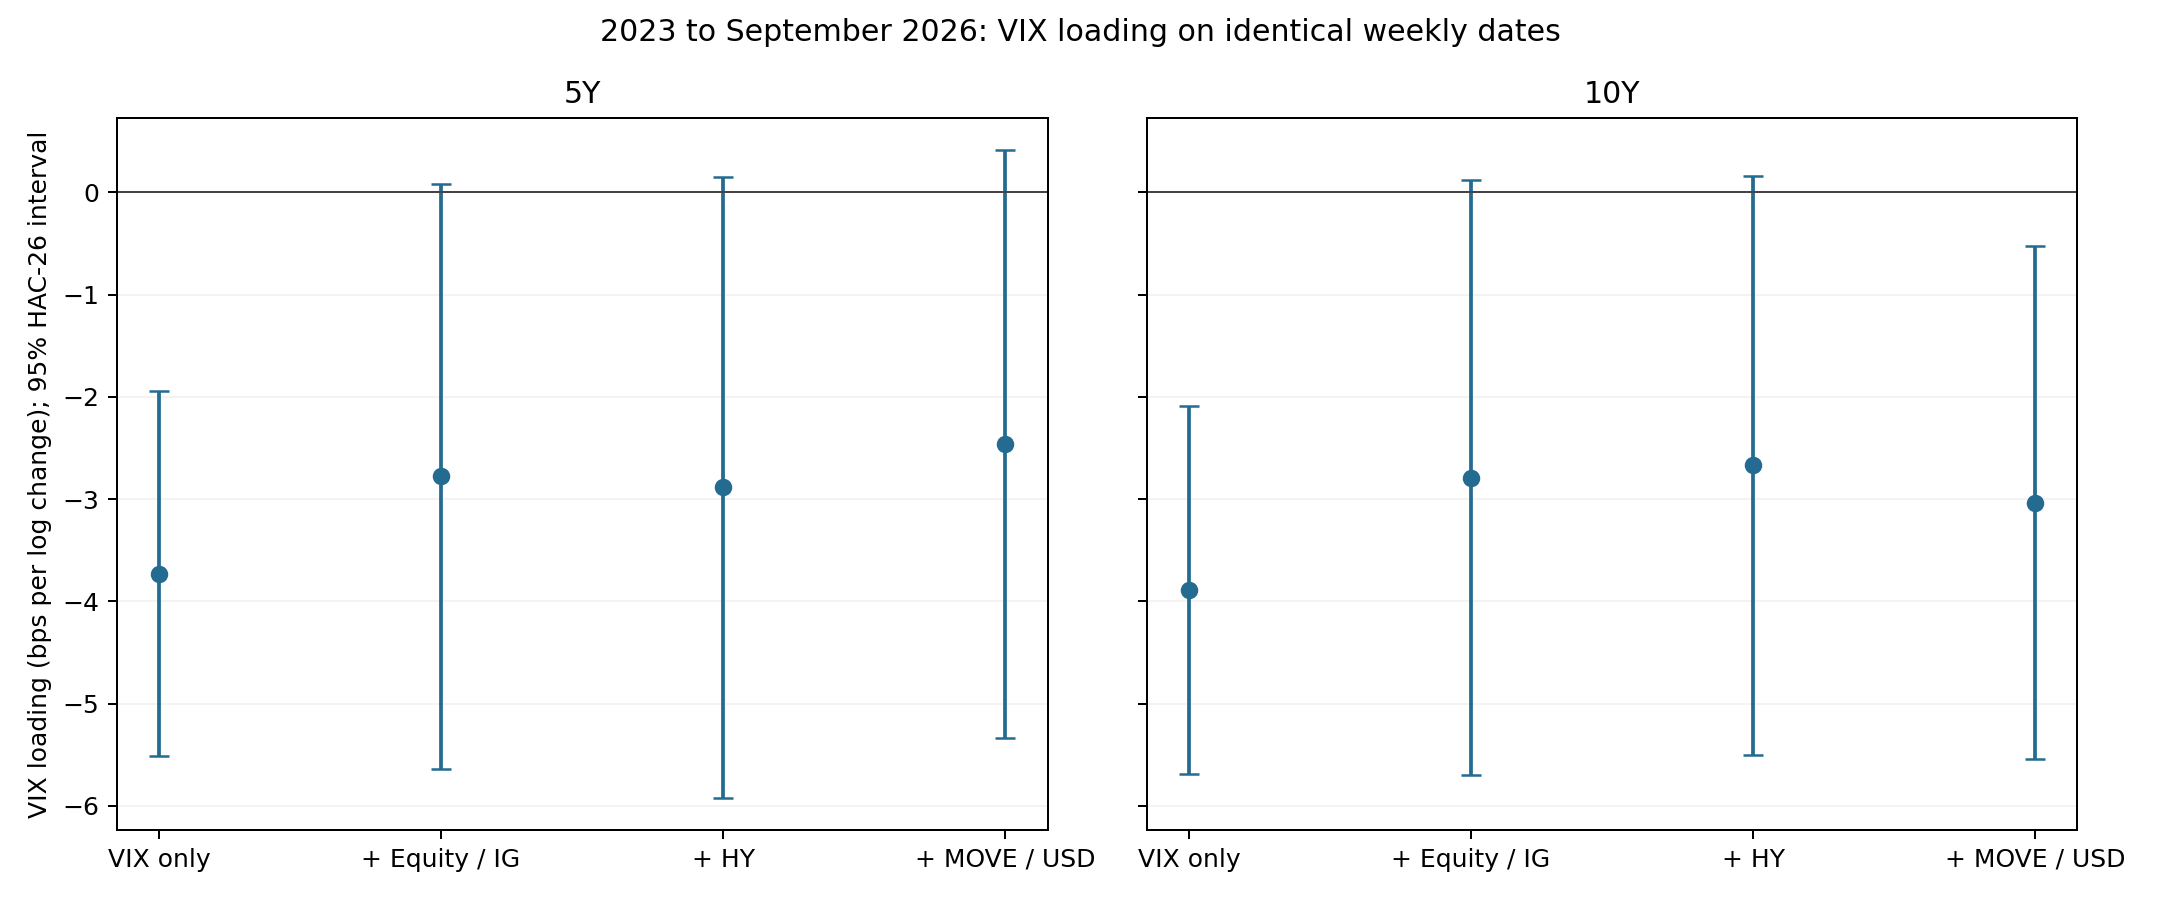

In [44]:
credit_coef = pd.read_csv(TABLE_DIR / 'credit_risk_coefficients.csv')
credit_fits = pd.read_csv(TABLE_DIR / 'credit_risk_model_fits.csv')
credit_increment = pd.read_csv(TABLE_DIR / 'credit_risk_hy_incremental.csv')
credit_recent = credit_coef[
    credit_coef.cohort.eq('fixed8') & credit_coef.window.eq('post2023') &
    credit_coef.outcome.eq('x_govt_raw_bps') & credit_coef.hac_weeks.eq(26)]
display(credit_recent[['tenor', 'spec', 'factor', 'beta', 'ci95_low',
    'ci95_high', 'p_exploratory', 'n_weeks']].round(4))
display(Image(filename=str(FIGURE_DIR / 'credit_risk_vix_conditional.png')))


### Current finding: no clear incremental HY signal

For the recent fixed-eight sample, adding HY to VIX/equity/IG changes in-sample R-squared from approximately **7.93% to 8.04% (5Y)** and **7.55% to 7.66% (10Y)**: gains of only **0.11 / 0.12 percentage points**. The HY coefficients are approximately **+0.0076 / -0.0083 bps of convenience per 1 bp of HY change** under the provisional unit convention. Their 95% HAC intervals cross zero; exploratory p-values are approximately **0.70 / 0.60**.

Ordinary R-squared cannot decrease when a nested OLS model adds a variable, so a small positive gain is not itself evidence for HY. Adjusted R-squared actually declines: about **6.29% to 5.85% (5Y)** and **5.90% to 5.45% (10Y)**. Neither fit measure is an out-of-sample test.

This is not evidence that credit risk is irrelevant. It is a bounded negative result: these HY series do not provide a clear **additional** recent signal conditional on the selected controls. Excluding NZD, changing HAC from 26 to 13 weeks, and adding MOVE/BBDXY do not reveal a robust recent HY effect. Other historical windows and component outcomes are retained in the output tables; they are not substitutes for the pre-specified recent test.


,tenor,window,n_weeks_base,Base R2 (%),With HY R2 (%),R2 increase (percentage points),Base adjusted R2 (%),With HY adjusted R2 (%)
48,10y,2010-2015,295,9.266,9.275,0.009,8.331,8.024
52,10y,2016-2020,259,3.380,3.656,0.276,2.244,2.139
56,10y,2021-2025,222,6.613,6.780,0.167,5.328,5.061
60,10y,post2023,172,7.546,7.662,0.115,5.895,5.450
72,5y,2010-2015,306,15.630,15.730,0.100,14.792,14.610
76,5y,2016-2020,259,1.741,2.326,0.586,0.585,0.788
80,5y,2021-2025,228,8.732,9.257,0.525,7.510,7.630
84,5y,post2023,173,7.927,8.038,0.111,6.292,5.848


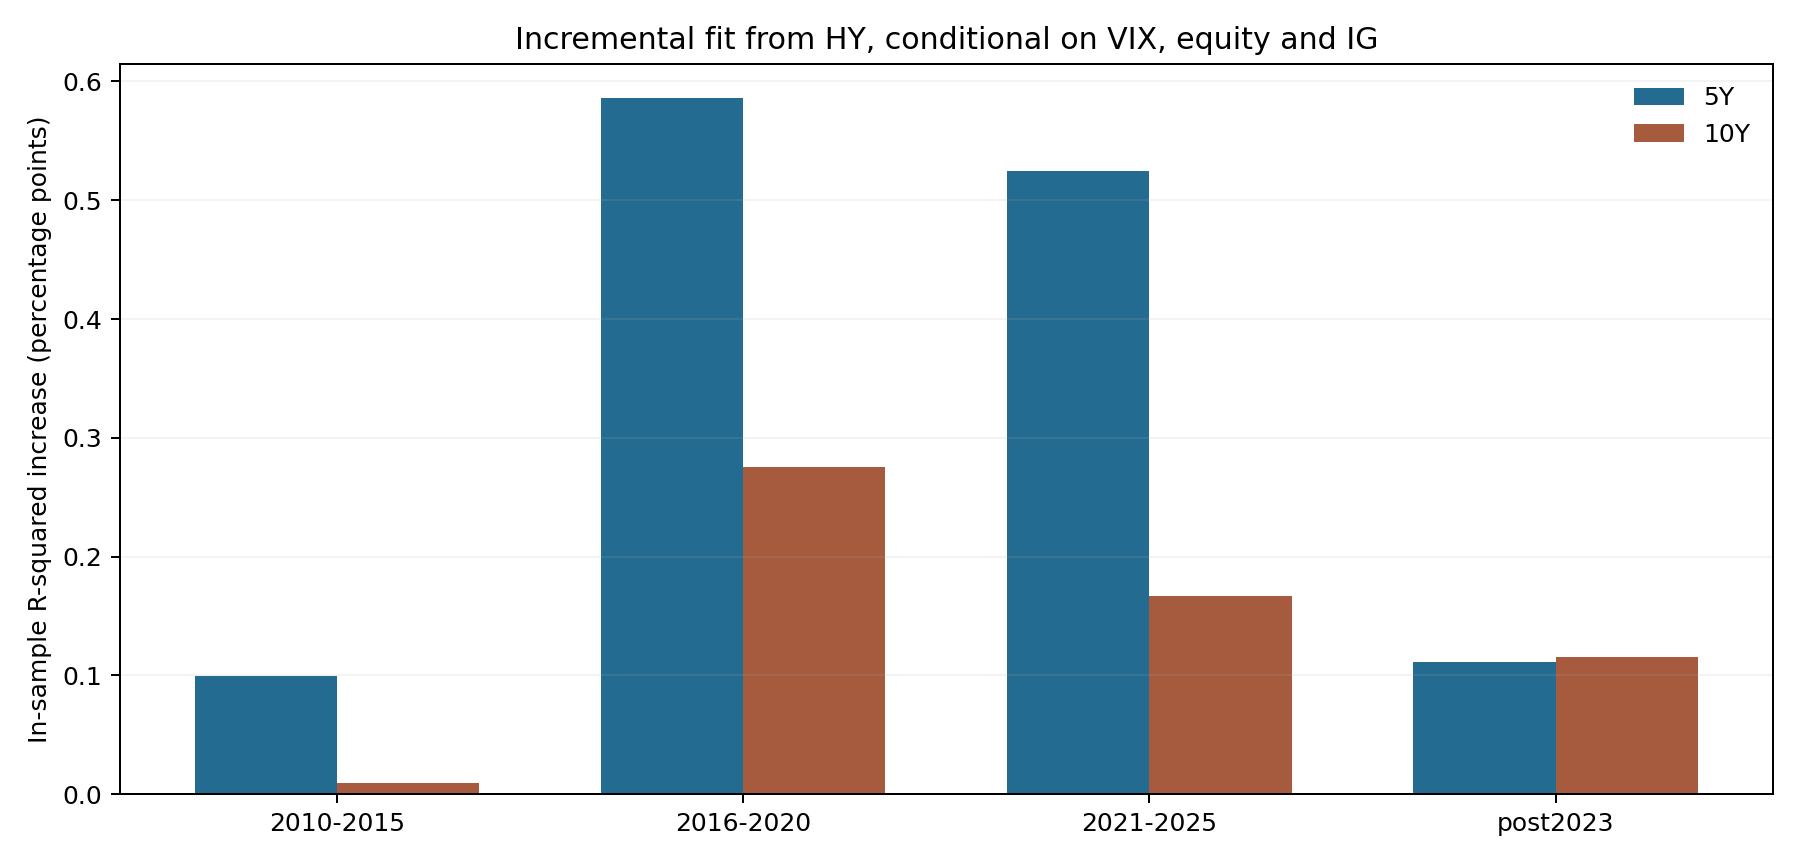

,cohort,tenor,spec,hac_weeks,beta,ci95_low,ci95_high,p_exploratory
131,exclude_NZD,10y,plus_HY,13,-0.0137,-0.0472,0.0197,0.4212
135,exclude_NZD,10y,plus_HY,26,-0.0137,-0.0457,0.0182,0.3995
163,exclude_NZD,10y,plus_HY_controls,13,-0.0146,-0.0488,0.0196,0.4015
169,exclude_NZD,10y,plus_HY_controls,26,-0.0146,-0.0471,0.0178,0.3769
531,exclude_NZD,5y,plus_HY,13,0.0081,-0.0298,0.0461,0.6751
535,exclude_NZD,5y,plus_HY,26,0.0081,-0.0302,0.0465,0.6783
563,exclude_NZD,5y,plus_HY_controls,13,0.0096,-0.0305,0.0497,0.6398
569,exclude_NZD,5y,plus_HY_controls,26,0.0096,-0.0314,0.0506,0.6468
931,fixed8,10y,plus_HY,13,-0.0083,-0.0406,0.0241,0.6154
935,fixed8,10y,plus_HY,26,-0.0083,-0.0395,0.0229,0.6022


In [45]:
increment_display = credit_increment[
    credit_increment.cohort.eq('fixed8') & credit_increment.outcome.eq('x_govt_raw_bps') &
    ~credit_increment.window.str.endswith('interaction')][[
    'tenor', 'window', 'n_weeks_base', 'r_squared_base', 'r_squared_hy', 'delta_r_squared',
    'adj_r_squared_base', 'adj_r_squared_hy']].copy()
for col in ['r_squared_base', 'r_squared_hy', 'delta_r_squared', 'adj_r_squared_base', 'adj_r_squared_hy']:
    increment_display[col] *= 100
display(increment_display.rename(columns={
    'r_squared_base': 'Base R2 (%)', 'r_squared_hy': 'With HY R2 (%)',
    'delta_r_squared': 'R2 increase (percentage points)',
    'adj_r_squared_base': 'Base adjusted R2 (%)', 'adj_r_squared_hy': 'With HY adjusted R2 (%)'}).round(3))
display(Image(filename=str(FIGURE_DIR / 'credit_risk_hy_incremental_fit.png')))
hy_robustness = credit_coef[
    credit_coef.window.eq('post2023') & credit_coef.spec.isin(['plus_HY', 'plus_HY_controls']) &
    credit_coef.outcome.eq('x_govt_raw_bps') & credit_coef.factor.eq('d_hy_bps')]
display(hy_robustness[['cohort', 'tenor', 'spec', 'hac_weeks', 'beta',
    'ci95_low', 'ci95_high', 'p_exploratory']].round(4))


### How this changes the earlier VIX interpretation

On the refreshed matched sample, VIX-only coefficients remain negative: about **-3.73 / -3.89** at 5Y/10Y. With equity and IG controls they become approximately **-2.78 / -2.79**, and their 95% intervals just include zero. The +HY model similarly gives about **-2.89 / -2.67** with intervals covering zero. Adding MOVE/BBDXY preserves negative point estimates but gives different significance across tenors.

Therefore the stronger October 23 bivariate statement must not be promoted into a robust causal or conditional safe-haven conclusion. The defensible current account is: **relative-convenience levels rebounded, but the available conditional risk tests do not establish recovery of safe-haven behavior**. Neither a positive beta recovery nor a uniquely identified deterioration is demonstrated. The all-history and latest-regime interaction checks remain sample-sensitive, and the latter has only **29/27 pre-2023 observations**.


In [46]:
credit_interactions = credit_coef[
    credit_coef.cohort.eq('fixed8') & credit_coef.window.str.endswith('interaction') &
    credit_coef.spec.eq('plus_HY') & credit_coef.outcome.eq('x_govt_raw_bps') &
    credit_coef.factor.eq('dlog_vix')]
display(credit_interactions[['tenor', 'window', 'contrast', 'beta', 'ci95_low',
    'ci95_high', 'n_pre2023', 'n_post2023']].round(3))
credit_weekly = pd.read_csv(CLEANED_DIR / 'credit_risk_weekly_panel.csv')
credit_joint = credit_weekly[credit_weekly.cohort.eq('fixed8') &
    credit_weekly.tenor.eq('5y') & credit_weekly.valid_change & credit_weekly.week.ge('2023-01-01')]
display(credit_joint[['dlog_vix', 'spx_return', 'd_ig_bps', 'd_hy_bps']].corr().round(3))


,tenor,window,contrast,beta,ci95_low,ci95_high,n_pre2023,n_post2023
1056,10y,full_interaction,pre2023_beta,-1.308,-3.362,0.745,637,172
1057,10y,full_interaction,post2023_beta,-2.669,-5.482,0.144,637,172
1058,10y,full_interaction,beta_change,-1.361,-4.774,2.053,637,172
1152,10y,recent_regime_interaction,pre2023_beta,9.992,-3.061,23.044,27,172
1153,10y,recent_regime_interaction,post2023_beta,-2.669,-5.534,0.196,27,172
1154,10y,recent_regime_interaction,beta_change,-12.661,-25.275,-0.046,27,172
1456,5y,full_interaction,pre2023_beta,-0.292,-3.064,2.480,655,173
1457,5y,full_interaction,post2023_beta,-2.885,-5.901,0.130,655,173
1458,5y,full_interaction,beta_change,-2.594,-6.640,1.453,655,173
1552,5y,recent_regime_interaction,pre2023_beta,3.321,-12.441,19.084,29,173


,dlog_vix,spx_return,d_ig_bps,d_hy_bps
dlog_vix,1.000,-0.798,0.487,0.624
spx_return,-0.798,1.000,-0.577,-0.708
d_ig_bps,0.487,-0.577,1.000,0.819
d_hy_bps,0.624,-0.708,0.819,1.000


### NZD: names resolved, pricing conventions still open

The cached terminal NAME fields identify `NDSO5/10` as **NZD SWAP OIS**, `NDSWAP5/10` as **NZD SWAP SA(V 3M)**, and `NZBBCO5/10` as **NZD BS (3M VS OIS)**. The earlier Bank-Bill label for the NDSO instrument is therefore inconsistent with the terminal name. The four re-downloaded OIS/basis legs match the old snapshot on **905 dates each**, with no numeric revision.

Across 967/973 joint dates, the raw bank-swap-minus-OIS gap tracks the downloaded basis (correlations about **0.906 / 0.922**), but is not identical: the same-sign MAE is about **3.73 / 4.20 bps** at 5Y/10Y. The opposite-sign gap is substantially larger. This supports further convention reconciliation, not automatic substitution or an exact par-swap identity. The `SA(V 3M)` name suggests a fixed-leg frequency issue worth checking, but detailed DES frequencies, day counts, quote timing and basis leg conventions remain unconfirmed. The user has no DES screenshots for now; this uncertainty is retained.

No validated Treasury-convenience outcome is overwritten. The prior exclusion and component-reallocation sensitivity remains relevant. Next narrow measurement task: obtain the detailed NZD DES terms when convenient, then decide whether an aligned benchmark requires an explicit convention adjustment. Do not choose a formula solely by whichever matches the public series best.


,tenor,n_joint_dates,first_date,last_date,gap_basis_corr,mae_same_sign_bps,mean_same_sign_gap_bps,mae_opposite_sign_bps,definition_status
0,5y,967,2023-01-02,2026-09-30,0.9060,3.7303,-3.7045,32.2210,BDP NAME confirms OIS / 3M distinction; detail...
1,10y,973,2023-01-02,2026-09-30,0.9221,4.2047,-4.1824,30.6909,BDP NAME confirms OIS / 3M distinction; detail...


,variable,n_overlap,mae_bps,max_abs_revision_bps
0,nzd_sofr_irs_5y_ndso5,905,0.0,0.0
1,nzd_sofr_tbs_5y_nzbbco5,905,0.0,0.0
2,nzd_sofr_irs_10y_ndso10,905,0.0,0.0
3,nzd_sofr_tbs_10y_nzbbco10,905,0.0,0.0


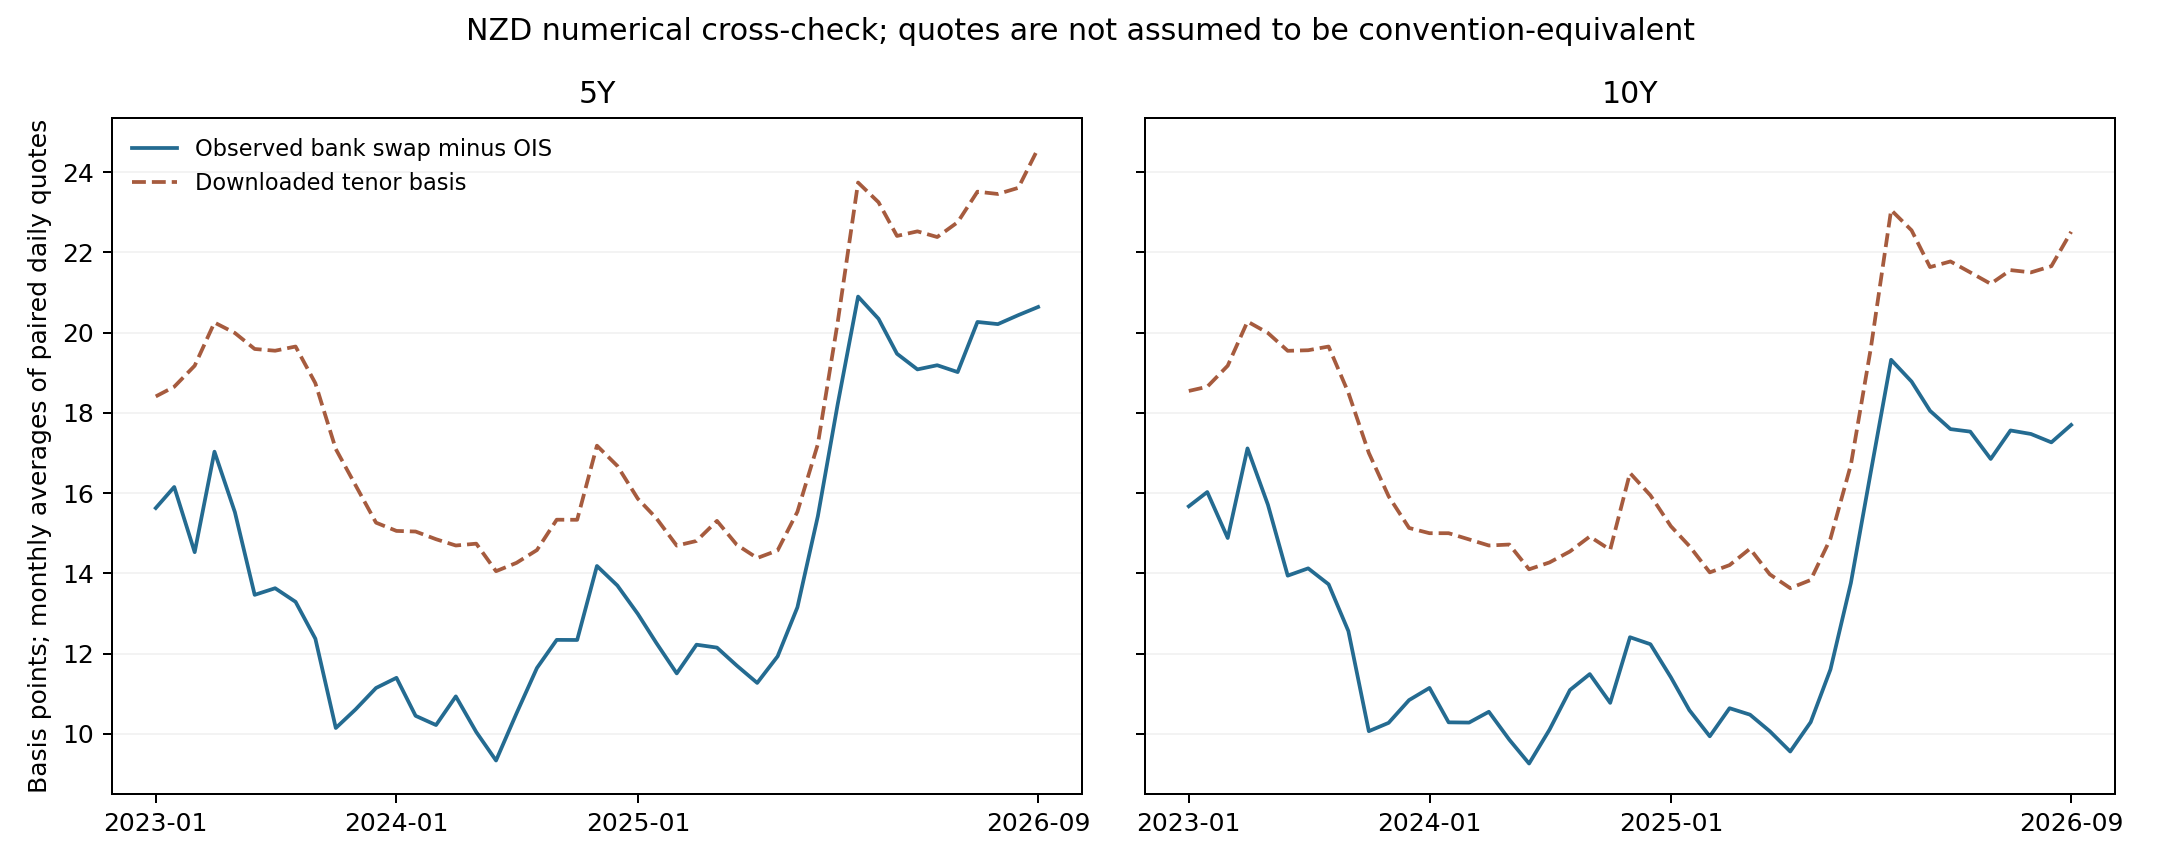

In [47]:
display(pd.read_csv(TABLE_DIR / 'credit_risk_nzd_checks.csv').round(4))
display(pd.read_csv(TABLE_DIR / 'credit_risk_nzd_revisions.csv').round(6))
display(Image(filename=str(FIGURE_DIR / 'credit_risk_nzd_quote_check.png')))


### Research decision

The new exports are numerically usable for this bounded first pass; another broad Bloomberg download is not needed. The primary HY test is now implemented and its weak incremental result should be reported, not removed. The project remains anchored in raw replication, robust level accounting and the distinction between convenience levels and risk sensitivity.

NZD's detailed conventions remain an open measurement task. Section 15F now organizes the paper-period comparison, joint risk tests and stress-week evidence; this section retains the conditional-beta and incremental-HY results. A causal foreign-supply or dealer-capacity claim still needs a separate design; the HY covariate does not provide it. Updated plots, QC, coefficient tables, matched-sample fit comparisons and source receipts are in `output/figures/` and `output/tables/credit_risk_*`.


## 15F. Risk Properties After the Rebound

### Question and scope

Does the recent rebound in relative Treasury convenience also indicate a return of safe-haven behavior? These are different hypotheses: a higher average convenience level need not mean that convenience rises during market stress. This section adds three checks using existing data only. The outcomes remain the validated fixed-eight 5Y/10Y measures; excluding NZD is a same-calendar sensitivity.

**Main result:** recent risk exposure is jointly nonzero, while stress-week Treasury convenience changes are negative and dollar-convenience proxy changes are positive. This supports separating the rebound in levels from claims of restored safe-haven behavior. It does not identify why pricing changed or establish an absolute Treasury-return effect.

Sources: the local frozen `Decoupling Dollar and Treasury Privilege.pdf`, Section 5.3 / Equation 7 and Table 5 (PDF pages 23-25 and 51); the November archived exports and the existing cleaned raw/public panels. Input and paper hashes, parameters and caveats are saved in `output/tables/risk_properties_summary.json`. Full results remain inspectable in the `risk_properties_*` CSVs, not just the displayed subsets.


In [48]:
from src.analyze_risk_properties import main as analyze_risk_properties
risk_properties_summary = analyze_risk_properties()
risk_paper = pd.read_csv(TABLE_DIR / 'risk_properties_table5_comparison.csv')
risk_wald = pd.read_csv(TABLE_DIR / 'risk_properties_joint_tests.csv')
risk_stress = pd.read_csv(TABLE_DIR / 'risk_properties_stress_results.csv')


{
  "calibration_start": "2010-01-15",
  "calibration_end": "2022-12-30",
  "calibration_weeks": 677,
  "quantile": 0.9,
  "threshold_dlog_vix": 0.14981996543936482,
  "equivalent_vix_percent_increase": 16.162509123867583,
  "threshold_inputs": "VIX-only calendar; no Treasury outcomes or post-2022 observations",
  "bootstrap_block_weeks": 8,
  "bootstrap_reps": 2000,
  "seed": 20261102,
  "updated": "2026-11-02",
  "paper_sha256": "7ba103d5085e9effaccaee4aa6df7e2d0bddd2e0c4bafcd5059f3fe9c3092a49",
  "paper_pages_inspected": [
    13,
    23,
    24,
    25,
    50,
    51
  ],
  "table5_rows": 54,
  "joint_test_rows": 320,
  "stress_result_rows": 192,
  "input_receipts": [
    {
      "path": "output/cleaned/raw_g10_benchmark_eq6_5y10y_refreshed_panel.csv",
      "sha256": "10b3961af010082c6f8e3b93276eed543acfa4677ce47ccf2ea935de3bdf2d02"
    },
    {
      "path": "output/cleaned/public_cip_cleaned.csv",
      "sha256": "783643c57bd05b9d13e553db31a9eb1c420b66c315a1f791037968a4873efb8b

### 1. Align the risk specification with Table 5

Equation 7 / Table 5 uses **one risk factor at a time**, not a joint VIX/equity/IG regression. The inspected paper's data end in **June 2025**. The comparison therefore uses 2010-2015, 2016-2020 and 2021-June 2025, ending at the complete week of June 27. The Section 15E multivariate and post-2023 models remain extensions rather than exact Table 5 replications.

The bounded comparison covers 18 government-CIP cells: two tenors, three periods and three factors. Weekly means are differenced, using the existing joint daily calendar, valid adjacent weeks and calendar-aware Newey-West 26. Public available-G10 mean and median variants share the raw model's dates; neither is selected by whichever best matches the paper. The exact original cross-country aggregation, IG ticker/unit and data vintage are not fully reconciled. In particular, the IG per-percentage-point display is only a candidate scale. Do not call the 54 variant rows 54 independently replicated paper cells.


In [49]:
risk_spec = pd.read_csv(TABLE_DIR / 'risk_properties_table5_specification.csv')
display(risk_spec[['dimension', 'remaining_gap']])
risk_vix = risk_paper[risk_paper.variant.eq('raw_fixed8_mean') & risk_paper.factor.eq('dlog_vix')]
display(risk_vix[['tenor', 'period', 'n_weeks', 'beta_on_display_scale',
    'ci95_low', 'ci95_high', 'paper_printed_beta']].round(3))


,dimension,remaining_gap
0,Model,Aligned model form
1,Periods,"Aligned dates; first change starts Jan 15, 201..."
2,Frequency / inference,Partly aligned; within-week timing and exact o...
3,G10 aggregation,Not claimed exact
4,IG risk series,Definition / scale unresolved
5,Measure vintage,Public appendix warns released data differ fro...
6,Coverage,Partial replication


,tenor,period,n_weeks,beta_on_display_scale,ci95_low,ci95_high,paper_printed_beta
0,5y,2010-2015,306,5.277,1.615,8.939,6.37
9,5y,2016-2020,259,-1.383,-3.423,0.657,-0.02
18,5y,2021-2025H1,204,-3.972,-5.834,-2.110,-5.50
27,10y,2010-2015,295,3.504,-0.890,7.897,4.69
36,10y,2016-2020,259,-1.791,-3.585,0.003,-1.10
45,10y,2021-2025H1,197,-3.655,-5.879,-1.430,-4.54


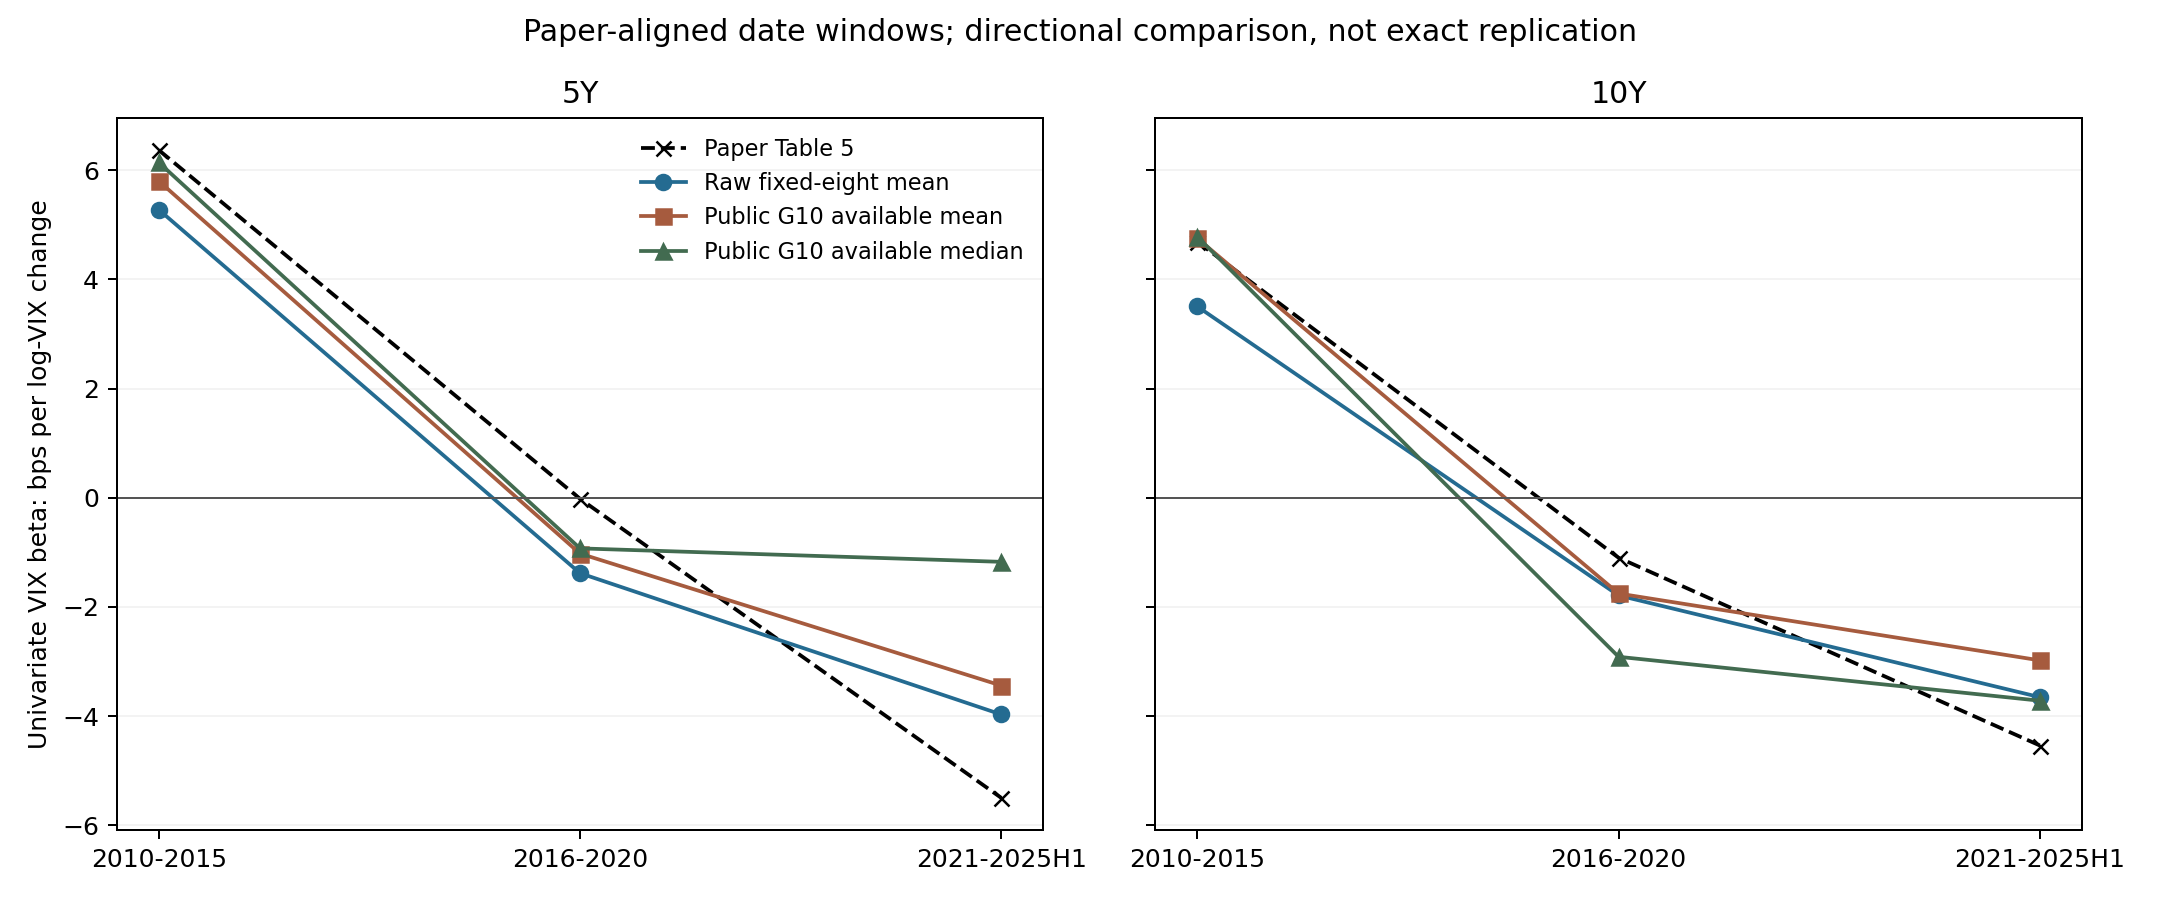

In [50]:
display(Image(filename=str(FIGURE_DIR / 'risk_properties_table5_vix_comparison.png')))


The raw fixed-eight VIX betas move from **+5.28 to -3.97** at 5Y and **+3.50 to -3.65** at 10Y between the first and final paper windows. Their directions agree with the paper, but magnitudes are not identical. Public aggregation sensitivity matters: the 2021-June 2025 5Y public median beta is about -1.18 and its interval covers zero, unlike the raw and public-mean variants. Sign agreement is not exact numerical validation, and within-period confidence intervals do not test a between-period difference.

### 2. Test risk exposure jointly

For the +HY specification, test whether all four post-2023 loadings are zero. In the interaction models, separately test whether all four slope changes are zero. Intercepts and regime intercept controls are not part of these restrictions. Use the full HAC covariance, including cross-coefficient covariance; this is not a collection of independent single-coefficient tests.

The six labeled primary government-CIP tests use the fixed-eight sample and HAC-26: two post-period loading tests, two full-history change tests and two latest-regime change tests. Holm adjustment applies to this six-test family only, not all analyses in the project. Excluding NZD, using HAC-13 and dropping HY are recorded as sensitivities. These are bounded exploratory tests, not independently preregistered confirmatory evidence.


In [51]:
risk_primary = risk_wald[risk_wald.p_holm_primary_family.notna()]
display(risk_primary[['tenor', 'window', 'test', 'n_pre2023', 'n_post2023',
    'p_exploratory', 'p_holm_primary_family']].round(6))
risk_change_sensitivity = risk_wald[risk_wald.spec.eq('plus_HY') &
    risk_wald.outcome.eq('x_govt_raw_bps') & risk_wald.window.eq('full_interaction') &
    risk_wald.test.eq('slope_changes_zero')]
display(risk_change_sensitivity.pivot(index=['cohort', 'tenor'],
    columns='hac_weeks', values='p_exploratory').round(4))


,tenor,window,test,n_pre2023,n_post2023,p_exploratory,p_holm_primary_family
169,10y,post2023,post_loadings_zero,0,172,0.000002,0.000012
195,10y,full_interaction,slope_changes_zero,637,172,0.000805,0.001610
227,10y,recent_regime_interaction,slope_changes_zero,27,172,0.000000,0.000000
249,5y,post2023,post_loadings_zero,0,173,0.000494,0.001481
275,5y,full_interaction,slope_changes_zero,655,173,0.029238,0.029238
307,5y,recent_regime_interaction,slope_changes_zero,29,173,0.000155,0.000622


hac_weeks              13      26
cohort      tenor                
exclude_NZD 10y    0.0599  0.0341
            5y     0.0749  0.0194
fixed8      10y    0.0065  0.0008
            5y     0.0798  0.0292

Post-2023 risk loadings are jointly nonzero at both tenors (Holm p about **0.00148 / 0.000012**, 5Y/10Y). This also holds in the recorded HAC-13 / excluding-NZD sensitivities. It does not contradict the individual VIX/HY intervals covering zero: correlated factors can be informative as a group without their individual effects being precisely isolated. This is in-sample association, not out-of-sample predictive performance or a direction-of-safety test.

The slope-change evidence is less robust. For fixed-eight full-history 5Y, p moves from **0.029** with HAC-26 to **0.080** with HAC-13. For 10Y excluding NZD, it moves from **0.034** to **0.060**. The latest-regime change tests reject in this calculation but use only **29/27 pre-2023 weeks**; large-sample Wald inference with so short a reference period is fragile. None of these results establishes a causal structural break or a recovered safe-haven premium.

### 3. Fix stress weeks without using Treasury outcomes

Use the 90th percentile of weekly VIX log increases in 2010-2022, estimated from the **VIX-only native calendar**, not the CIP-covered calendar. A week needs at least three VIX quotes; a missing week prevents the next change from bridging the gap. The stress rule is:

$$
S_t=\mathbf{1}\{\Delta\log(\overline{\mathrm{VIX}}_t)>\tau\},
\qquad \tau=Q_{0.90,\,2010:2022}(\Delta\log\overline{\mathrm{VIX}}).
$$

The 677 calibration changes give **tau = 0.14982**, equivalent to a weekly-average VIX increase above **16.16%**. This threshold is fixed before these outcome comparisons and never recalibrated on post-2022 Treasury results. It is not a genuinely prospective preregistration: the broader post-2023 pattern was already known.

The outcome analysis uses the unchanged joint-date CIP weekly panel, while stress labels use native VIX dates. This distinction is intentional; the stress dummy does not replace the matched-date VIX regressor in earlier models. There are 195 calendar weeks in the recent window, **13 usable stress weeks** and **160/159 ordinary weeks** at 5Y/10Y. Missing/invalid outcome weeks are excluded, not imputed. The units are changes in relative convenience, not bond price or total returns.


In [52]:
risk_post = risk_stress[risk_stress.cohort.eq('fixed8') & risk_stress.period.eq('post2023')]
display(risk_post[risk_post.contrast.eq('stress_mean') &
    risk_post.outcome.isin(['x_govt_raw_bps', 'x_rf_raw_bps'])][[
    'tenor', 'outcome', 'estimate_bps', 'hac26_ci_low', 'hac26_ci_high', 'n_stress']].round(3))
risk_stress_net = risk_post[risk_post.outcome.eq('x_govt_raw_bps') &
    risk_post.contrast.eq('stress_minus_ordinary')]
display(risk_stress_net[['tenor', 'estimate_bps', 'hac26_ci_low', 'hac26_ci_high',
    'bootstrap_ci_low', 'bootstrap_ci_high', 'p_holm_stress_primary_family']].round(4))


,tenor,outcome,estimate_bps,hac26_ci_low,hac26_ci_high,n_stress
132,10y,x_govt_raw_bps,-1.067,-1.954,-0.180,13
135,10y,x_rf_raw_bps,0.536,-0.063,1.135,13
180,5y,x_govt_raw_bps,-1.095,-2.079,-0.111,13
183,5y,x_rf_raw_bps,0.640,0.097,1.183,13


,tenor,estimate_bps,hac26_ci_low,hac26_ci_high,bootstrap_ci_low,bootstrap_ci_high,p_holm_stress_primary_family
134,10y,-1.2550,-2.0842,-0.4258,-2.2799,-0.2642,0.0060
182,5y,-1.2352,-2.1937,-0.2767,-2.5248,-0.1983,0.0115


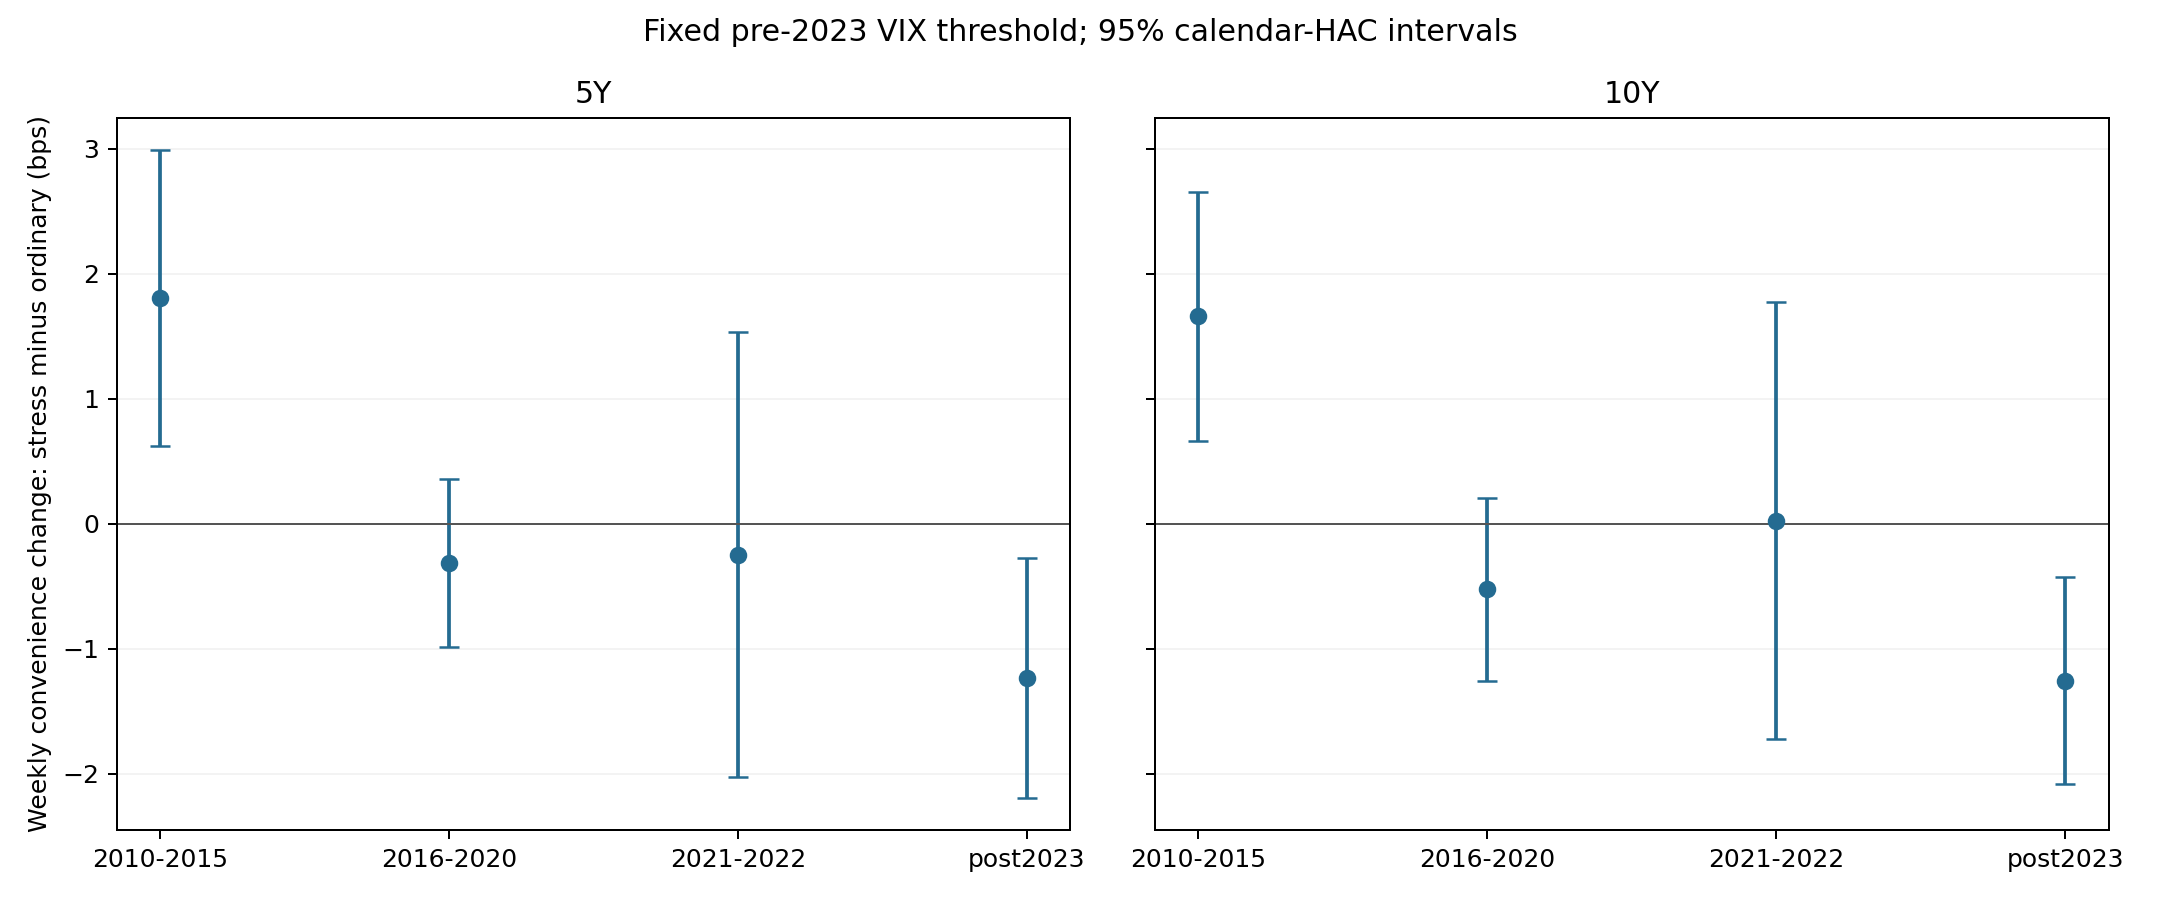

In [53]:
display(Image(filename=str(FIGURE_DIR / 'risk_properties_stress_comparison.png')))


Recent stress weeks show average Treasury-convenience changes of **-1.09 / -1.07 bps**, versus ordinary-week changes of about **+0.14 / +0.19 bps** at 5Y/10Y. The stress-minus-ordinary contrasts are **-1.24 / -1.26 bps**. Both HAC-26 intervals and the paired moving-block bootstrap intervals are below zero. A separate Holm correction for these two primary stress contrasts gives p about **0.0115 / 0.0060**; other component comparisons remain exploratory.

Bootstrap settings are fixed at eight-calendar-week circular blocks, 2,000 draws and seed 20261102. Calendar gaps, stress states and all four components are sampled together; the additive identity is checked in every draw. Percentile intervals condition on the historical threshold and do not incorporate threshold-estimation uncertainty. Only 13 stress observations support the recent estimate, so finite-sample uncertainty, time-varying conditions and non-random coverage remain material.

### 4. Reconcile the stress result with Equation 6

The dollar-convenience proxy increases on stress weeks: about **+0.64 / +0.54 bps**. Its stress-minus-ordinary difference is **+0.73 / +0.63 bps**; the 10Y stress-mean interval alone includes zero. Thus these are not identical statements about significance.

The stress-minus-ordinary Treasury differences satisfy the same accounting bridge:

$$
\begin{aligned}
\text{5Y: } -1.235 &\simeq +0.728 -0.713 -1.251,\\
\text{10Y: } -1.255 &\simeq +0.632 -0.957 -0.930.
\end{aligned}
$$

The terms on the right are dollar convenience, U.S. swap spread and **minus** the foreign swap spread. Positive dollar-convenience contributions are more than offset by the point-estimated swap-spread terms. The two individual spread terms have wide intervals, especially at 10Y. Their accounting contribution is not proof of a supply, credit, dealer or monetary-policy mechanism, and the benchmark proxy retains the convention limitations documented above.


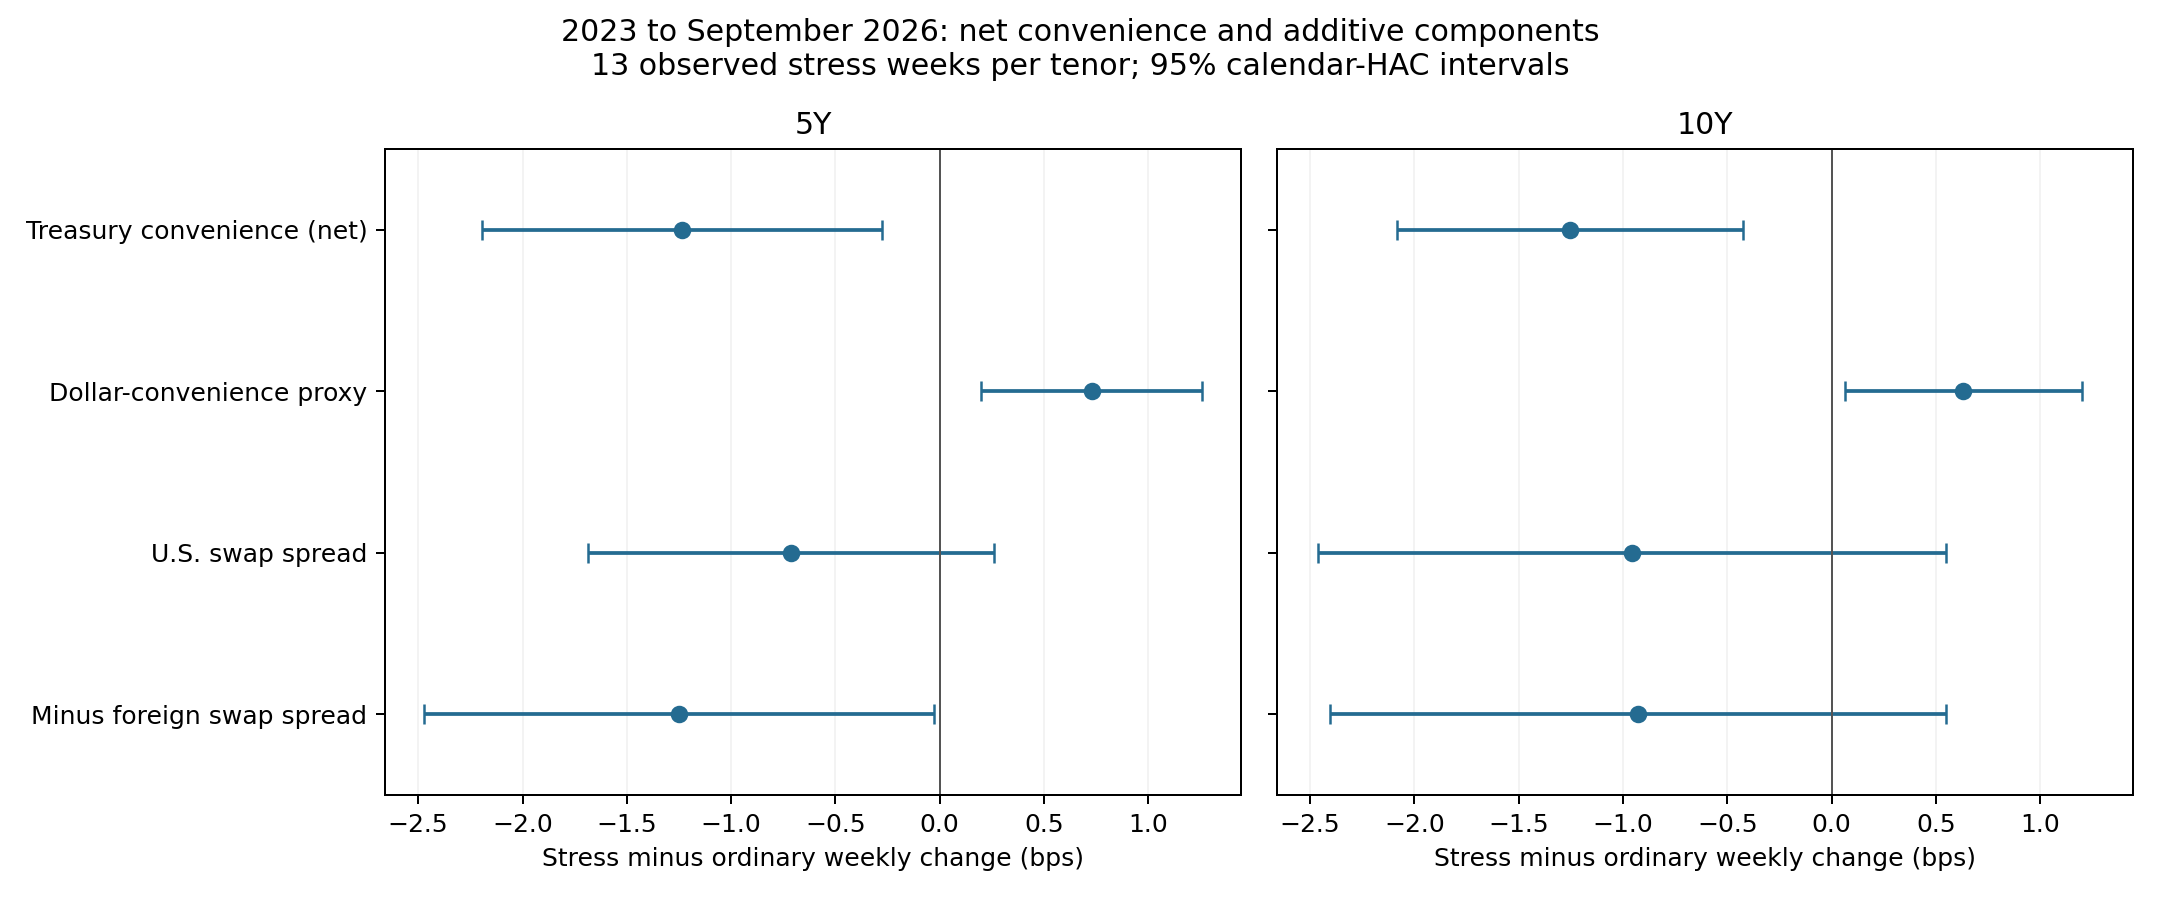

In [54]:
display(Image(filename=str(FIGURE_DIR / 'risk_properties_stress_components.png')))


### Influence checks and research conclusion

Excluding NZD preserves negative recent stress-minus-ordinary contrasts (about **-1.41 bps at both tenors**). Deleting each stress week in turn keeps the fixed-eight contrast negative: approximately **[-1.48, -0.77]** at 5Y and **[-1.50, -0.91]** at 10Y. These are point-estimate influence ranges, **not confidence intervals** and not evidence that every reduced-sample test is significant. The historical positive-to-negative contrast in the figure is descriptive; a change in the stress response has not been causally identified.

The strongest current synthesis is: **a rebound in average relative convenience can coexist with a negative convenience response during VIX-defined stress, even while dollar convenience rises.** The first-pass HY extension offers little incremental recent fit; the joint tests show that this does not imply risk is irrelevant. This narrows the economic question from "did Treasury safety return?" to "which relative swap/government pricing terms drive levels and stress behavior, and how sensitive are those conclusions to benchmarks?"

No additional broad Bloomberg export is required for these completed checks. The detailed NZD DES terms and the original paper's exact aggregation/IG definition remain necessary if seeking an exact Table 5 replication. Section 15G now implements country-level stress-component accounting with current raw data; a causal foreign-supply/QT/dealer explanation still needs a separate design and appropriately matched evidence. Do not promote the accounting identity or this stress association into that claim.


## 15G. Which Markets Account for the Stress-Week Contrast?

### Keep the comparison fixed

This is an attribution of the Section 15F result, **not a new search for stress events or a newly balanced sample**. Reuse its saved VIX flags unchanged, the fixed-eight joint daily dates, Friday weekly means, valid adjacent weeks and the September 25, 2026 endpoint. Every country has the same 13 stress weeks and 160/159 ordinary weeks at 5Y/10Y. Holidays, incomplete weeks and regime transitions are still excluded. Removing a country never adds dates that were unavailable in the original fixed-eight calculation.

The markets are AUD/Australia, CAD/Canada, CHF/Switzerland, DKK/Denmark, **EUR/Germany's government-bond leg**, GBP/UK, NZD/New Zealand and SEK/Sweden. EUR is not a pooled euro-area sovereign portfolio. JPY/NOK and EM remain outside this fixed-eight extension.

Let the stress-minus-ordinary contrast operator be $C(z)=E[\Delta z\mid S=1]-E[\Delta z\mid S=0]$. For currency pair $i$ define $D_i=C(x_i^{Govt})$ and $w=1/8$:

$$
D=\frac{1}{8}\sum_i D_i
 = C(s^{US})+\frac{1}{8}\sum_i\left[C(x_i^{Rf})-C(s_i^{foreign})\right].
$$

The U.S. swap-spread input is identical across these pairs in the recent window and is counted **once** in the second expression. A pair's weighted contribution $D_i/8$ includes one-eighth of this common U.S. term. Do not add the common term again to the weighted-pair contributions. The country-specific term excludes the shared U.S. component but still includes pairwise dollar funding; it is not an isolated local causal shock.

Sources are the unchanged raw panel, November market inputs, saved weekly panel and stress calendar. `output/tables/country_stress_summary.json` records their hashes. The script checks weekly mean reconciliation, each pair's Equation 6 identity and the aggregate ledger; all countries share the same calendar, not independent samples.


In [55]:
from src.analyze_country_stress_attribution import main as analyze_country_stress
country_stress_summary = analyze_country_stress()
country_stress_attribution = pd.read_csv(TABLE_DIR / 'country_stress_attribution.csv')
country_stress_estimates = pd.read_csv(TABLE_DIR / 'country_stress_estimates.csv')
country_stress_ledger = pd.read_csv(TABLE_DIR / 'country_stress_accounting_ledger.csv')
country_stress_omissions = pd.read_csv(TABLE_DIR / 'country_stress_leave_one_country_out.csv')
country_stress_events = pd.read_csv(TABLE_DIR / 'country_stress_event_contributions.csv', parse_dates=['week'])
display(pd.read_csv(TABLE_DIR / 'country_stress_weekly_reconciliation.csv').round(12))


{
  "updated": "2026-11-02",
  "currencies": [
    "AUD",
    "CAD",
    "CHF",
    "DKK",
    "EUR",
    "GBP",
    "NZD",
    "SEK"
  ],
  "weight": 0.125,
  "start_week": "2023-01-06",
  "end_week": "2026-09-25",
  "country_week_rows": 3120,
  "country_estimate_rows": 288,
  "max_weekly_reconciliation_error_bps": 2.1316282072803006e-14,
  "max_accounting_residual_bps": 1.5543122344752192e-15,
  "stress_rule": "Reuse risk_properties_stress_calendar.csv unchanged; no threshold refit",
  "inference": "HAC-26 country intervals are exploratory, unadjusted for multiple comparisons; ranking is descriptive",
  "caveats": [
    "Same fixed-eight joint dates; deleting a country never expands the calendar.",
    "The common U.S. leg is counted once, not eight independent observations.",
    "Country-specific includes pairwise dollar funding; it does not isolate a local causal shock.",
    "Thirteen stress weeks and unresolved benchmark conventions limit mechanism claims."
  ],
  "input_receipt

,tenor,metric,max_weekly_mean_error_bps
0,5y,x_govt_raw_bps,0.0
1,5y,x_rf_raw_bps,0.0
2,5y,us_swap_spread_bps,0.0
3,5y,foreign_swap_spread_bps,0.0
4,10y,x_govt_raw_bps,0.0
5,10y,x_rf_raw_bps,0.0
6,10y,us_swap_spread_bps,0.0
7,10y,foreign_swap_spread_bps,0.0


### 1. Negative pair contrasts are concentrated, not uniform

AUD, EUR/Germany and SEK have the largest negative pair contrasts at both tenors. At 5Y their own pair contrasts are about **-3.99, -2.57 and -2.46 bps**; at 10Y they are **-3.74, -2.46 and -2.42 bps**. Dividing by eight gives their contributions to the fixed-eight average. CAD/CHF 5Y are slightly positive, GBP 5Y and NZD 5Y are near zero, and GBP 10Y is positive.

This is a descriptive ranking, not evidence that each of the three effects is statistically different from every other country. The figure's country-level HAC-26 intervals are exploratory and **not adjusted for multiple comparisons**. The eight country observations within a stress week are correlated; 13 stress weeks do not become 104 independent stress observations.


In [56]:
display(country_stress_attribution.pivot(index='currency', columns='tenor',
    values=['pair_contrast_bps', 'weighted_pair_contribution_bps']).round(3))


pair_contrast_bps        weighted_pair_contribution_bps       
tenor                  10y     5y                            10y     5y
currency                                                               
AUD                 -3.739 -3.988                         -0.467 -0.499
CAD                 -0.548  0.042                         -0.069  0.005
CHF                 -0.691  0.189                         -0.086  0.024
DKK                 -0.381 -1.076                         -0.048 -0.134
EUR                 -2.460 -2.569                         -0.307 -0.321
GBP                  0.395 -0.001                          0.049 -0.000
NZD                 -0.194 -0.018                         -0.024 -0.002
SEK                 -2.423 -2.461                         -0.303 -0.308

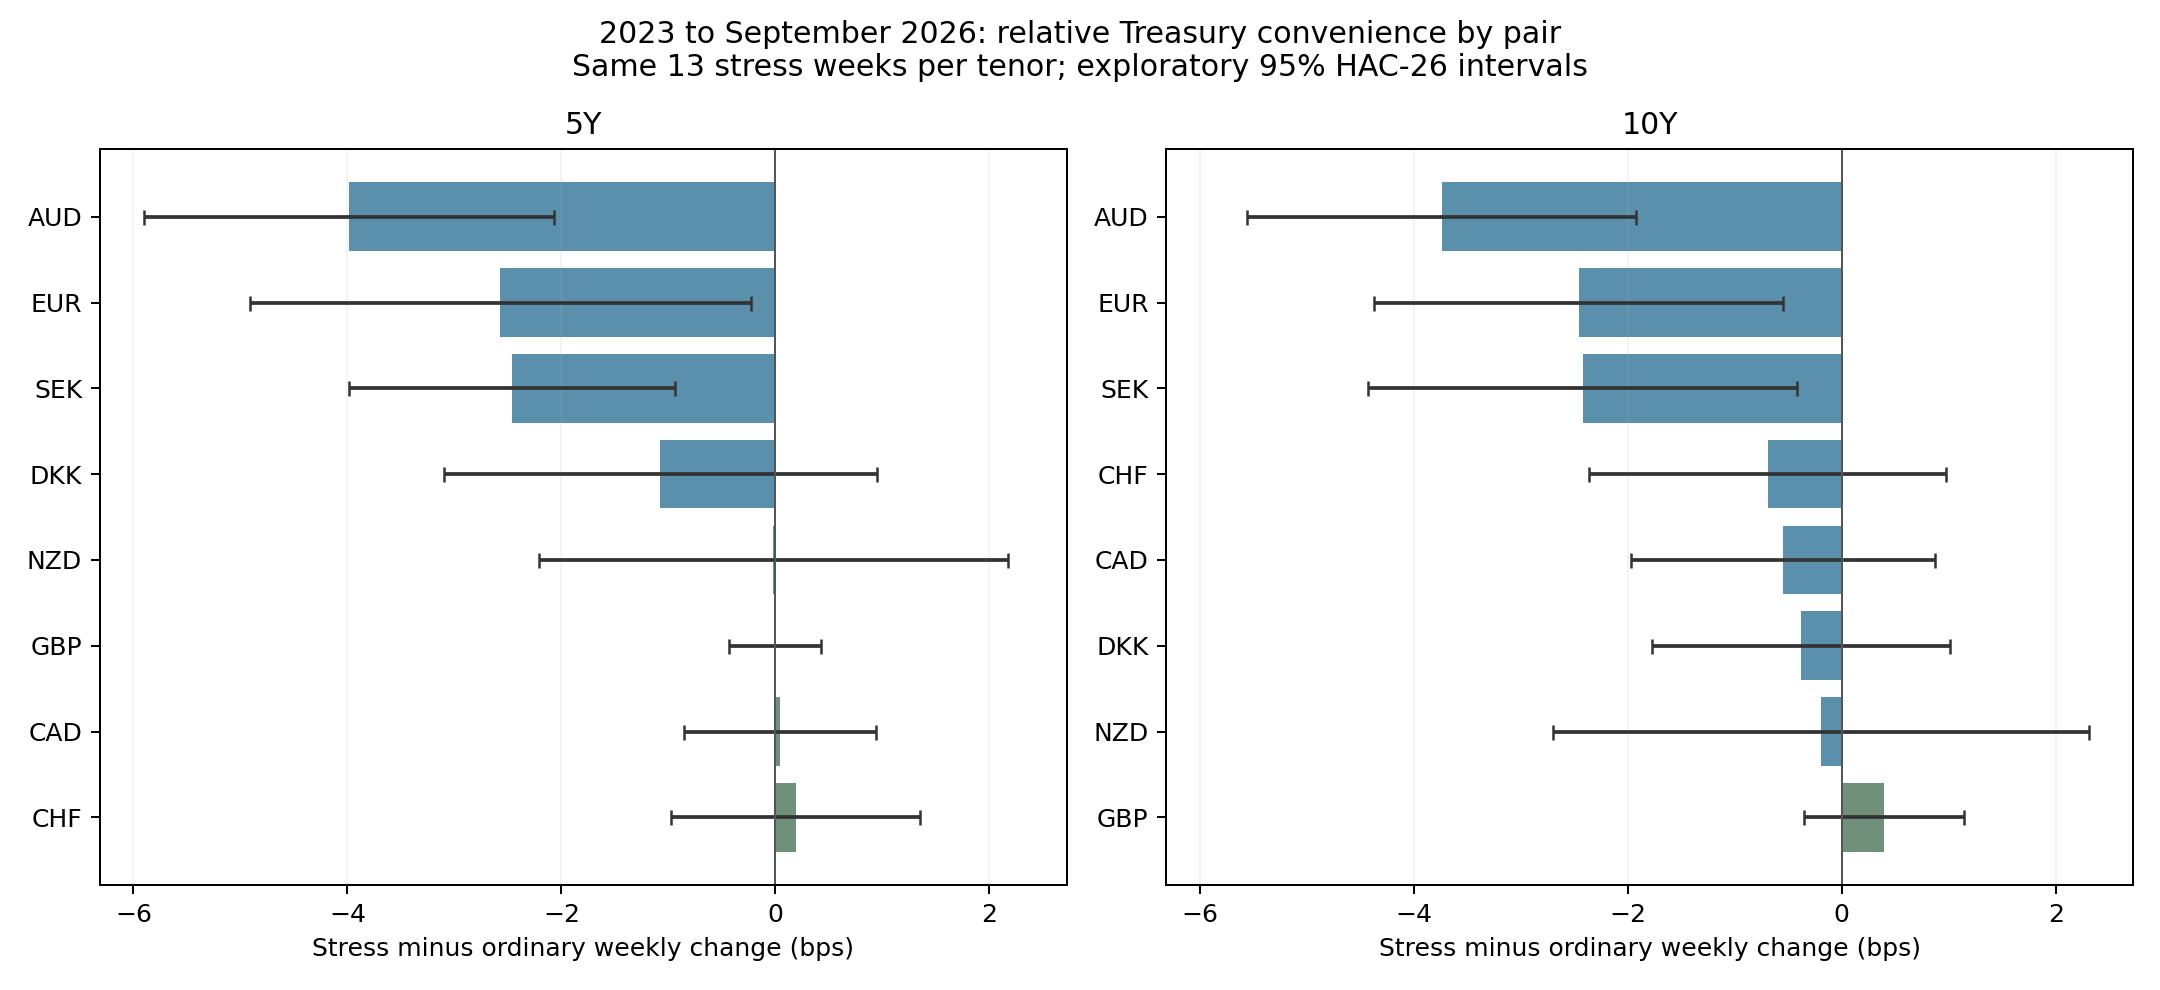

In [57]:
display(Image(filename=str(FIGURE_DIR / 'country_stress_pair_contrasts.png')))


### 2. Separate the shared U.S. term from the country terms

The U.S. swap-spread contrast contributes **-0.713 / -0.957 bps** to the 5Y/10Y aggregate. The country-specific terms sum to **-0.522 / -0.298 bps**, recovering the previously reported **-1.235 / -1.255 bps**. Country contributions are signed and can offset, so percentages of the small net total can be misleading.

After taking out the common U.S. term, AUD/EUR/SEK remain negative at both tenors. Their weighted country-specific contributions are about **-0.409/-0.232/-0.218 bps** at 5Y and **-0.348/-0.188/-0.183 bps** at 10Y. Most other country-specific terms offset part of these declines. NZD is not the main negative contributor in this calculation, although its benchmark documentation still needs confirmation.

The plot counts the gray U.S. bar only once. Green and brown country bars may offset; their diamond is the signed country-specific sum. It is not a confidence interval or an estimate of a policy effect.


In [58]:
country_stress_net_ledger = country_stress_ledger[
    country_stress_ledger.contrast.eq('stress_minus_ordinary')]
display(country_stress_net_ledger[['tenor', 'previous_aggregate_bps', 'common_us_bps',
    'dollar_bps', 'minus_foreign_spread_bps', 'reconstructed_bps', 'residual_bps']].round(4))
display(country_stress_attribution[['currency', 'tenor', 'dollar_contribution_bps',
    'minus_foreign_spread_contribution_bps', 'country_specific_contribution_bps']].round(3))


,tenor,previous_aggregate_bps,common_us_bps,dollar_bps,minus_foreign_spread_bps,reconstructed_bps,residual_bps
2,10y,-1.2550,-0.9570,0.6320,-0.9299,-1.2550,0.0
5,5y,-1.2352,-0.7129,0.7284,-1.2507,-1.2352,0.0


,currency,tenor,dollar_contribution_bps,minus_foreign_spread_contribution_bps,country_specific_contribution_bps
0,AUD,10y,0.040,-0.387,-0.348
1,CAD,10y,0.046,0.006,0.051
2,CHF,10y,0.042,-0.008,0.033
3,DKK,10y,0.107,-0.035,0.072
4,EUR,10y,0.103,-0.291,-0.188
5,GBP,10y,0.206,-0.037,0.169
6,NZD,10y,0.047,0.049,0.095
7,SEK,10y,0.043,-0.226,-0.183
8,AUD,5y,0.056,-0.466,-0.409
9,CAD,5y,0.030,0.065,0.094


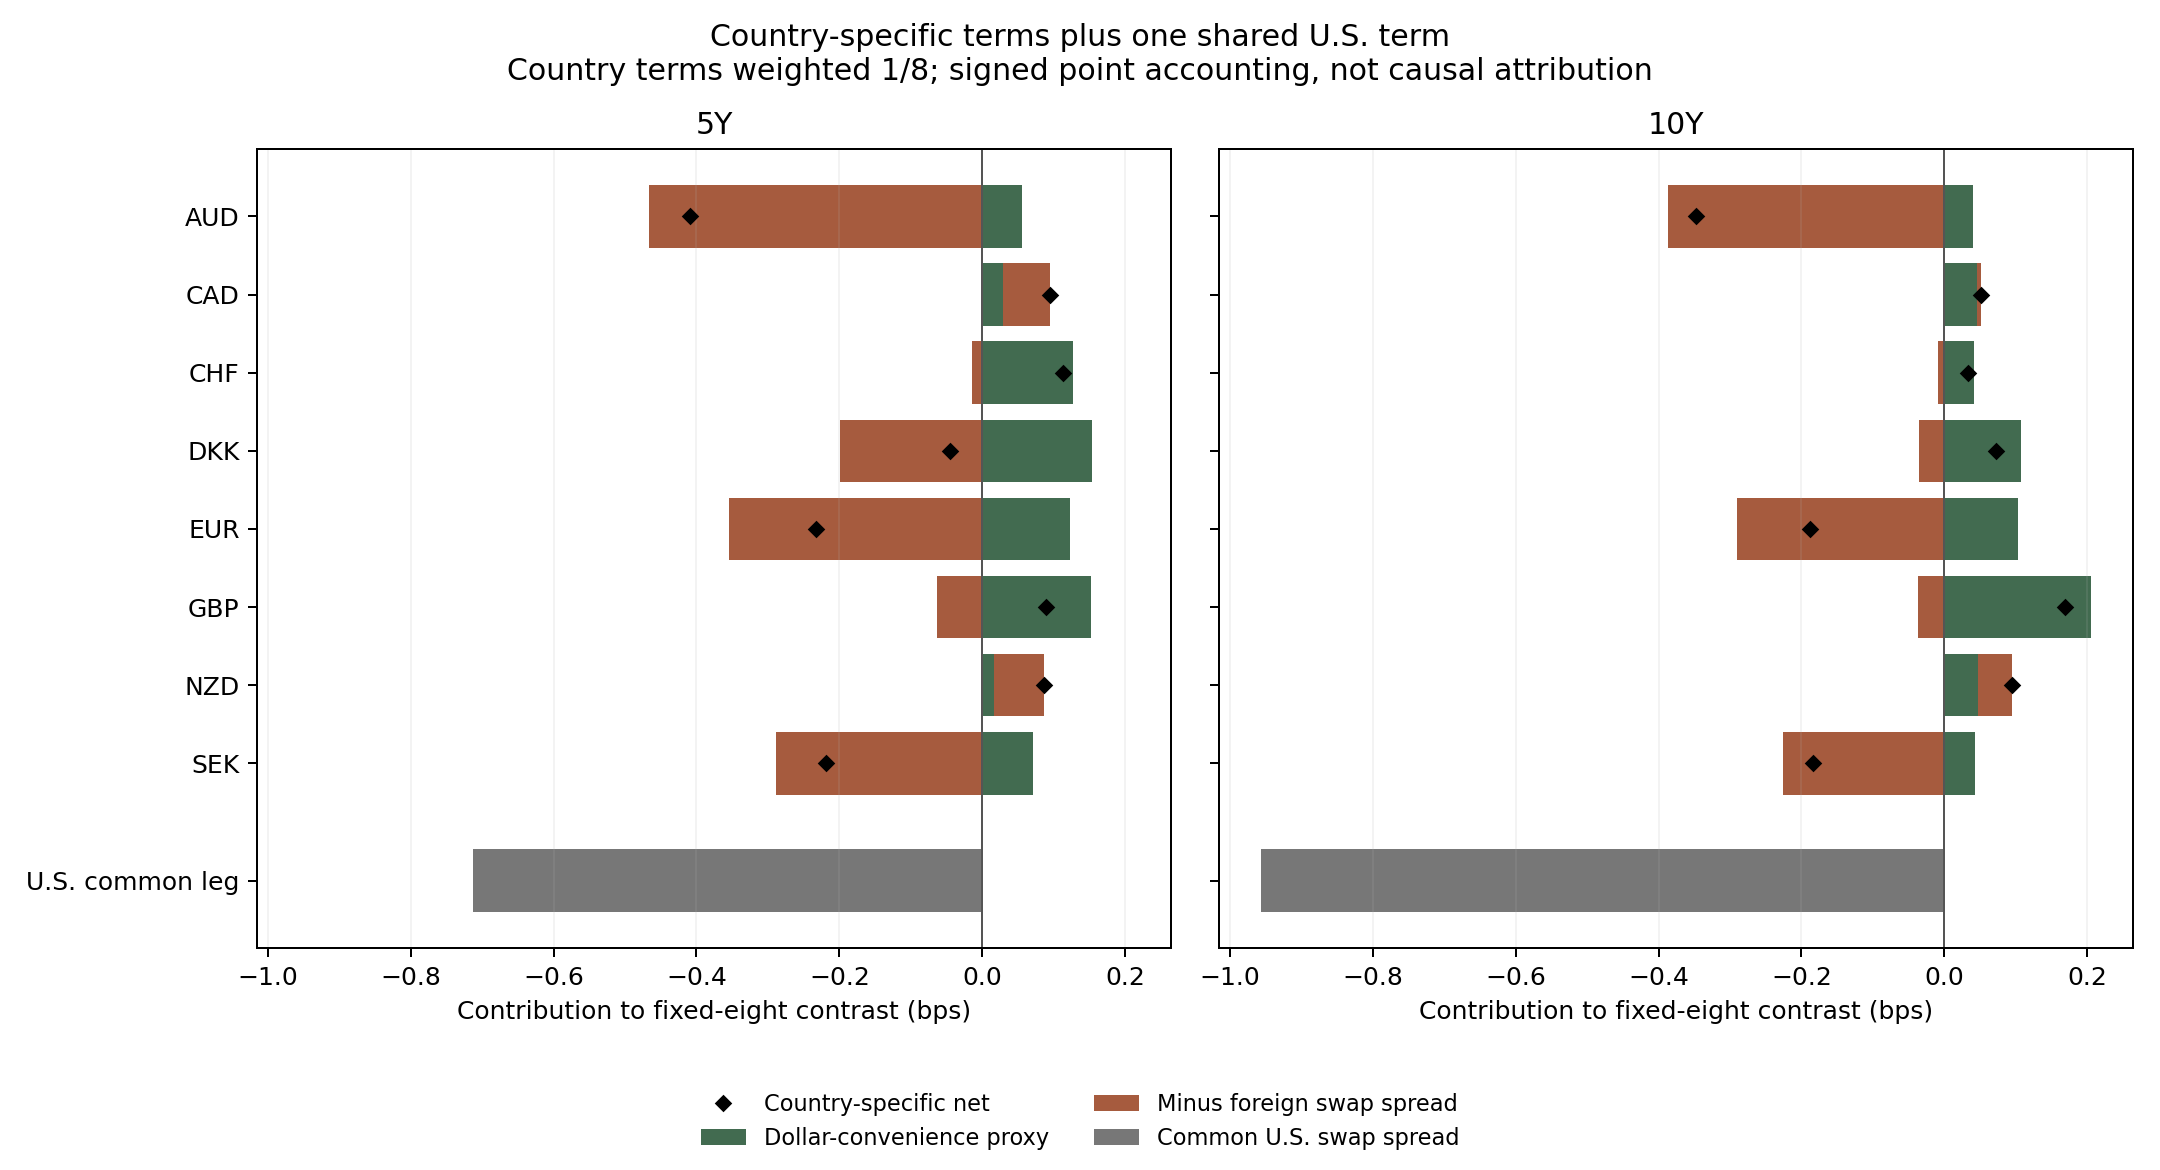

In [59]:
display(Image(filename=str(FIGURE_DIR / 'country_stress_component_contributions.png')))


### 3. What moves inside the foreign spread?

Using the same dates, split $-C(s_i^{foreign})$ into **minus the swap-rate change plus the government-yield change**, with both raw quotes converted from percentage points to bps. This adds no instruments or new benchmark assumptions to the existing construction.

For AUD/EUR/SEK, government-yield changes are more negative than their local swap-rate changes in the stress-minus-ordinary comparison. At 5Y, for example, AUD's contrasts are approximately **-4.08 bps for the swap** and **-7.81 bps for the government yield**. Its foreign spread therefore widens by about **3.73 bps**, contributing about **-0.466 bps** after the one-eighth weight. EUR/Germany and SEK foreign spreads widen by about **2.84 / 2.31 bps** at 5Y, and the analogous pattern holds at 10Y.

Economically, this describes the **relative pricing of foreign government bonds versus their local swap benchmark**, which enters the hedged-U.S.-Treasury comparison. It is consistent with comparatively stronger foreign-government-bond pricing, but it does not establish investor flows, a demand shock, or deterioration in U.S. Treasury prices/returns. AUD/SEK bank-linked and EUR overnight benchmarks are not homogeneous pure risk-free rates. No new supply, credit or dealer mechanism is identified by splitting these observed quotes.


In [60]:
country_stress_foreign_legs = country_stress_estimates[
    country_stress_estimates.contrast.eq('stress_minus_ordinary') &
    country_stress_estimates.currency.isin(['AUD', 'EUR', 'SEK']) &
    country_stress_estimates.metric.isin([
        'foreign_swap_bps', 'foreign_govt_yield_bps', 'foreign_swap_spread_bps'])]
display(country_stress_foreign_legs.pivot(index=['currency', 'tenor'],
    columns='metric', values='estimate_bps').round(3))


metric          foreign_govt_yield_bps  foreign_swap_bps  \
currency tenor                                             
AUD      10y                    -5.338            -2.238   
         5y                     -7.807            -4.080   
EUR      10y                    -3.595            -1.269   
         5y                     -5.886            -3.050   
SEK      10y                    -4.758            -2.952   
         5y                     -6.182            -3.869   

metric          foreign_swap_spread_bps  
currency tenor                           
AUD      10y                      3.099  
         5y                       3.726  
EUR      10y                      2.326  
         5y                       2.835  
SEK      10y                      1.806  
         5y                       2.313

### 4. Country and event influence

All eight one-country exclusions retain negative aggregate point estimates: about **[-1.439, -0.842] bps** at 5Y and **[-1.491, -0.900] bps** at 10Y. These use seven-country equal weights on the unchanged original calendar. The deletion effect is not simply the original weighted contribution: the surviving weights are renormalized. In particular,

$$
D_{-i}=\frac{8D-D_i}{7}.
$$

**Precision is not equally robust.** Removing AUD leaves 5Y at about **-0.842 bps**, but its unadjusted 95% HAC-26 interval is **[-1.700, +0.016]**. The corresponding 10Y interval remains below zero. Do not interpret "all deletion point estimates remain negative" as "every test remains significant."

The heatmap includes all 13 observed stress weeks, not selected stories. Each cell is that currency pair's weekly change minus its ordinary-week mean. To convert it into an aggregate event contribution, divide by **8 times 13**. Summing all cells with that weight exactly recovers the overall stress-minus-ordinary contrast.

The week ending **April 11, 2025** has the largest negative aggregate event contribution: approximately **-0.525 / -0.415 bps** at 5Y/10Y. Removing it still leaves **-0.770 / -0.910 bps**. These are data-defined influence observations, not causal event-study estimates or externally verified event explanations. Even when one country and one stress week are both removed, all recorded point estimates remain negative; the least-negative cases are about **-0.447 / -0.577 bps**. That is a sensitivity range, not a simultaneous confidence band.


In [61]:
display(country_stress_omissions[['tenor', 'omitted_currency', 'estimate_bps',
    'hac26_ci_low', 'hac26_ci_high']].round(3))
country_stress_event_totals = country_stress_events.groupby(
    ['tenor', 'week']).aggregate_contribution_bps.sum()
display(country_stress_event_totals.unstack('tenor').round(3))


,tenor,omitted_currency,estimate_bps,hac26_ci_low,hac26_ci_high
0,10y,AUD,-0.900,-1.665,-0.135
1,10y,CAD,-1.356,-2.154,-0.557
2,10y,CHF,-1.336,-2.171,-0.501
3,10y,DKK,-1.380,-2.322,-0.438
4,10y,EUR,-1.083,-1.966,-0.200
5,10y,GBP,-1.491,-2.444,-0.538
6,10y,NZD,-1.407,-2.268,-0.545
7,10y,SEK,-1.088,-1.895,-0.281
8,5y,AUD,-0.842,-1.700,0.016
9,5y,CAD,-1.418,-2.458,-0.377


tenor,10y,5y
week,,
2023-03-17,-0.055,-0.187
2024-04-19,-0.211,-0.173
2024-08-09,-0.109,-0.156
2024-09-06,0.127,0.097
2024-10-04,-0.113,-0.055
2024-12-20,0.120,0.128
2025-02-28,-0.093,0.038
2025-03-07,0.004,0.030
2025-04-04,-0.161,-0.143


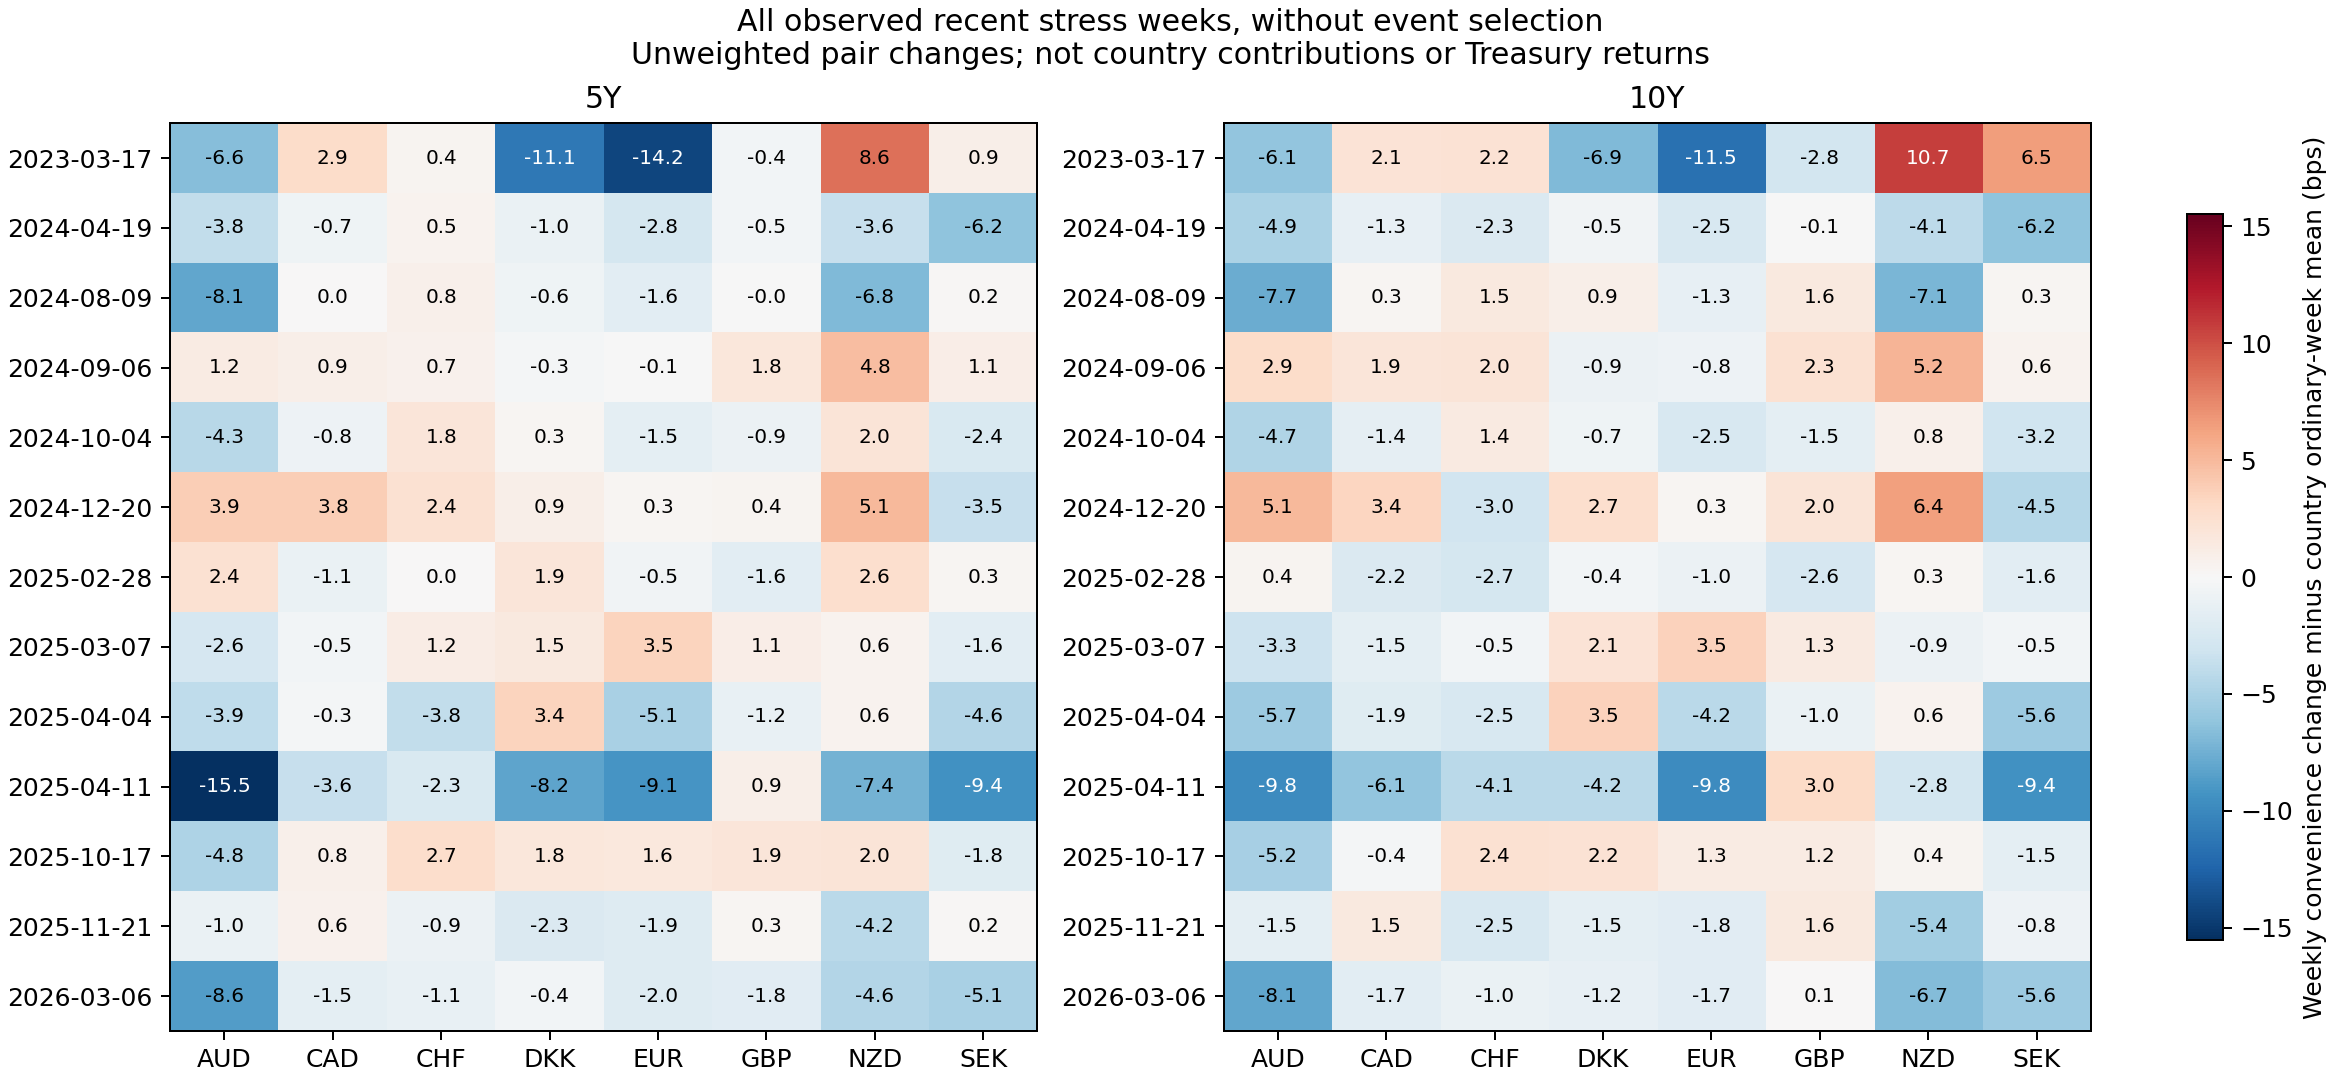

In [62]:
display(Image(filename=str(FIGURE_DIR / 'country_stress_week_heatmap.png')))


### Research conclusion and next boundary

The aggregate result is **not uniform across foreign markets**. It combines a negative common U.S. swap-spread term with particularly negative AUD, German/EUR and SEK pair accounting. Other markets offset part of that movement. This strengthens the distinction between a rebound in average convenience and a general recovery of safe-haven behavior, while cautioning against treating a fixed-eight average as one universal property of Treasuries.

An additional public-overlap QC uses identical raw/public daily dates, valid adjacent weeks and the unchanged VIX flags. It covers **10 stress / 104 ordinary weeks** per tenor through the week of June 27, 2025, not the full recent extension. AUD/EUR/SEK raw-versus-public contrast gaps are below **0.00001 bps**, and weekly-change MAEs are about 0.00001 bps. DKK retains nonzero contrast gaps of about **0.089/0.182 bps** and weekly-change MAEs of about **0.670/0.450 bps** at 5Y/10Y. Keep that reconciliation caveat rather than declaring every country exact. This overlap check supports the dominant-country measurement; it is not independent validation of all 13 extended-sample stress weeks.

The country/rate/event ledger now answers where the observed contrast sits; it does not answer why those relative prices moved. The most focused next investigation is to audit the dominant AUD/EUR/SEK raw legs on the existing stress dates, then distinguish a bond-side explanation from swap-benchmark/funding effects. The date list must remain fixed, and any external event explanation should be source-verified before causal language is considered. NZD DES and the original-paper definitions remain separate measurement tasks. No additional broad Bloomberg download is required for the completed attribution.


In [63]:
display(pd.read_csv(TABLE_DIR / 'country_stress_public_overlap_check.csv')[[
    'currency', 'tenor', 'n_stress', 'n_ordinary', 'raw_contrast_bps',
    'public_contrast_bps', 'contrast_gap_bps', 'weekly_change_mae_bps']].round(6))


,currency,tenor,n_stress,n_ordinary,raw_contrast_bps,public_contrast_bps,contrast_gap_bps,weekly_change_mae_bps
0,AUD,5y,10,104,-3.800562,-3.800563,0.000000,0.000011
1,CAD,5y,10,104,0.017275,0.017274,0.000001,0.000011
2,CHF,5y,10,104,0.105372,0.105372,-0.000001,0.000012
3,DKK,5y,10,104,-1.342875,-1.431709,0.088834,0.669669
4,EUR,5y,10,104,-3.202492,-3.202493,0.000001,0.000011
5,GBP,5y,10,104,-0.094893,-0.094890,-0.000003,0.000010
6,NZD,5y,10,104,0.487306,0.487304,0.000002,0.000011
7,SEK,5y,10,104,-2.602544,-2.602544,-0.000000,0.000011
8,AUD,10y,10,104,-3.443056,-3.443051,-0.000005,0.000011
9,CAD,10y,10,104,-0.594996,-0.594994,-0.000001,0.000009


## 15H. Does Pre-Stress Bond Supply Explain Country Differences?

[Du, Keerati and Schreger](https://www.federalreserve.gov/econres/ifdp/files/ifdp1427.pdf) already study the supply-level relationship (Section 6 and Table A4) and the April 2025 tariff episode (Figure 7). The proposed extension tests **whether pre-stress supply is associated with relative repricing across stress weeks beyond the tariff window**. A positive slope means higher foreign supply goes with a less negative Treasury-convenience response.

### Feasibility screen with a fixed pre-sample vintage

Use **2021 general-government gross debt as a percent of GDP**, reported in [IMF Fiscal Monitor, October 2022, Table A7](https://www.imf.org/-/media/files/publications/fiscal-monitor/2022/october/english/msa.pdf). This single vintage predates the 2023-2026 sample. It is not marketable central-government bond stock, is not net of central-bank holdings, and has no tenor matching. Keep the original eight countries, fixed VIX flags and matched calendars. Estimate one country slope per week, then compare those slopes between stress and ordinary weeks. This removes common U.S. weekly movements from the cross-country slope and avoids using country-week rows as independent shocks. Calendar HAC-26 intervals are exploratory and conditional on these countries and this exposure; they do not account for country selection, proxy error or multiple testing.


In [64]:
from src.analyze_stress_supply_pilot import main as run_stress_supply_pilot
stress_supply = run_stress_supply_pilot()
display(stress_supply.query("omitted == 'none'").round(3))
display(stress_supply.query("omitted != 'none'").groupby(['tenor', 'sample'])['bps_per_10pp'].agg(['min', 'max']).round(3))


,tenor,sample,omitted,outcome,n_stress,n_ordinary,bps_per_10pp,ci_low,ci_high
0,10y,all,none,d_x_govt_raw_bps,13,159,0.134,0.009,0.260
1,10y,all,none,d_x_rf_raw_bps,13,159,0.060,0.008,0.112
2,10y,all,none,d_us_swap_spread_bps,13,159,0.000,-0.000,0.000
3,10y,all,none,d_foreign_swap_spread_bps,13,159,-0.074,-0.213,0.064
4,10y,ex_tariff,none,d_x_govt_raw_bps,11,159,0.124,-0.026,0.274
5,10y,ex_tariff,none,d_x_rf_raw_bps,11,159,0.058,-0.002,0.118
6,10y,ex_tariff,none,d_us_swap_spread_bps,11,159,0.000,-0.000,0.000
7,10y,ex_tariff,none,d_foreign_swap_spread_bps,11,159,-0.066,-0.233,0.100
24,5y,all,none,d_x_govt_raw_bps,13,160,0.163,0.053,0.273
25,5y,all,none,d_x_rf_raw_bps,13,160,-0.024,-0.069,0.020


min    max
tenor sample                 
10y   all        0.031  0.211
      ex_tariff  0.066  0.171
5y    all        0.065  0.245
      ex_tariff  0.007  0.193

At 5Y/10Y the full-sample stress interaction is **+0.163/+0.134 bps per 10 percentage points of debt/GDP**. Removing weeks ending April 4 and 11, 2025 leaves **+0.114/+0.124** and both exploratory intervals cross zero. Every one-country deletion retains a positive point estimate, but the 5Y no-tariff result can be close to zero. The 5Y component point estimates are primarily on the foreign swap-spread side; 10Y is split between that side and the dollar-convenience proxy. These are not independently identified mechanisms. The screen is directional evidence, not a result about net marketable supply or a causal test.

### Next measurement and test

Collect matched nominal central-government marketable debt outstanding, the face value of the same instruments held by the relevant domestic central bank/Eurosystem, and trailing four-quarter nominal GDP. Use the latest quarter for which **all three exact vintages were public before the week began**. Do not backdate revised downloads to a first release date; if vintage verification fails, label any lagged latest-vintage exercise separately. Keep a common-sample gross-versus-net comparison. Compare stress interactions with country and week effects, show the amount of within-country exposure variation, and report exclusions of tariff weeks, countries, and contiguous stress episodes. Do not present more country-week rows as more independent events. Freeze the design before examining the new supply results. Additional regimes or separately selected events may be needed if the recent sample remains too small.

[BIS debt securities](https://data.bis.org/topics/DSS) gives six candidate quarterly nominal central-government stock series in local currency for this cohort, but candidate instrument coverage must be checked before matching to holders. National sources are needed for gaps and aligned holdings. The collection sheet keeps empty inputs separate from zero, records vintage dates and links, and calculates net supply only for valid amounts.


## 15I. Does Subtracting Central-Bank Holdings Change the Stress Result?

### Matched-sample design and data

Compare general-government debt from Section 15H with gross bond stock and net bond stock on the **same countries and weeks**. Hold the stock observation quarter fixed: 2021 Q4 for CAD/GBP/NZD/SEK, then 2022 Q2 for the same four, then add AUD and finally Germany. Australia's June 2022 gross leg is AUD 830.512 billion from [AOFM's original 2021-22 report, Note 2](https://www.aofm.gov.au/sites/default/files/2022-10-14/AOFM_Annual%20Report%202021-22_PRINT%20FA%20v2.pdf); the holding comes from [RBA A3.1, AGSHSTOT](https://www.rba.gov.au/statistics/tables/). The original collection is in `outputs/samim-stress-supply/sovereign_stress_supply_public_panel.csv` and its workbook. GBP subtracts only monetary-policy APF holdings. These are market-specific bond-stock measures, not matched 5Y/10Y issuance or tradable free float.

Germany is a **scope sensitivity** using long-term general-government securities at face value in both [ECB CSEC (issuance)](https://data.ecb.europa.eu/data/datasets/CSEC/CSEC.M.N.DE.W0.S13.S1.N.L.LE.F3.L._Z.EUR._T.F.V.N._T) and [ECB SHSS (euro-area central bank holdings)](https://data.ecb.europa.eu/data/datasets/SHSS/SHSS.Q.N.U2.DE.S121.S13.N.A.LE.F3.L._Z.XDC._T.F.V.N._T). This pair is not federal-only Bund supply. The complete 19-quarter supplemental series is saved separately; it is not silently substituted into the federal target panel. The latest holdings observation is provisional, and neither current download establishes a historical release vintage.

The quarter labels precede the stress sample, but most exact value vintages and publication dates are not verified. **This is a fixed-baseline, latest-vintage sensitivity; not an as-of backtest.** No later exposure observations are used in these estimates. Compare one cross-country slope per week, using the unchanged VIX labels and outcome calendars from Section 15G. The exposure is in units of 10 GDP percentage points. To avoid mistaking different cross-country dispersion for economic strength, also compare the associations for one full-cohort standard deviation of each exposure. HAC intervals are exploratory and conditional on this small, selected set of markets.


In [65]:
from src.analyze_stress_supply_pilot import run_paired_diagnostic
supply_exposures, supply_estimates, supply_advantage = run_paired_diagnostic()
supply_government = supply_estimates.query("outcome == 'd_x_govt_raw_bps'")
supply_full = supply_government.query("omitted == 'none' and sample in ['all', 'ex_tariff']")
display(supply_exposures.round(3))
display(supply_full[['design', 'tenor', 'sample', 'exposure', 'n_stress',
    'bps_per_10pp', 'ci_low', 'ci_high', 'bps_per_full_cohort_sd']].round(3))


,currency,imf_gross_pct_gdp,gross_market_pct_gdp,net_market_pct_gdp,design,quarter_end
0,CAD,112.9,40.079,24.720,2021Q4_four,2021-12-31
1,GBP,95.3,69.192,36.615,2021Q4_four,2021-12-31
2,NZD,50.8,35.825,35.102,2021Q4_four,2021-12-31
3,SEK,36.8,12.108,5.930,2021Q4_four,2021-12-31
4,CAD,112.9,38.716,25.076,2022Q2_four,2022-06-30
5,GBP,95.3,66.201,36.432,2022Q2_four,2022-06-30
6,NZD,50.8,35.808,35.110,2022Q2_four,2022-06-30
7,SEK,36.8,10.278,5.187,2022Q2_four,2022-06-30
8,AUD,58.4,35.539,23.210,2022Q2_plus_AUD,2022-06-30
9,CAD,112.9,38.716,25.076,2022Q2_plus_AUD,2022-06-30


,design,tenor,sample,exposure,n_stress,bps_per_10pp,ci_low,ci_high,bps_per_full_cohort_sd
0,2021Q4_four,10y,all,imf_gross_pct_gdp,13,0.210,-0.044,0.464,0.654
4,2021Q4_four,10y,ex_tariff,imf_gross_pct_gdp,11,0.168,-0.144,0.480,0.523
27,2021Q4_four,5y,all,imf_gross_pct_gdp,13,0.240,0.073,0.408,0.749
31,2021Q4_four,5y,ex_tariff,imf_gross_pct_gdp,11,0.163,-0.020,0.346,0.509
54,2021Q4_four,10y,all,gross_market_pct_gdp,13,0.474,0.034,0.913,0.961
58,2021Q4_four,10y,ex_tariff,gross_market_pct_gdp,11,0.300,-0.149,0.750,0.609
81,2021Q4_four,5y,all,gross_market_pct_gdp,13,0.407,0.149,0.665,0.826
85,2021Q4_four,5y,ex_tariff,gross_market_pct_gdp,11,0.264,0.058,0.470,0.536
108,2021Q4_four,10y,all,net_market_pct_gdp,13,0.845,0.196,1.494,1.034
112,2021Q4_four,10y,ex_tariff,net_market_pct_gdp,11,0.539,0.056,1.021,0.659


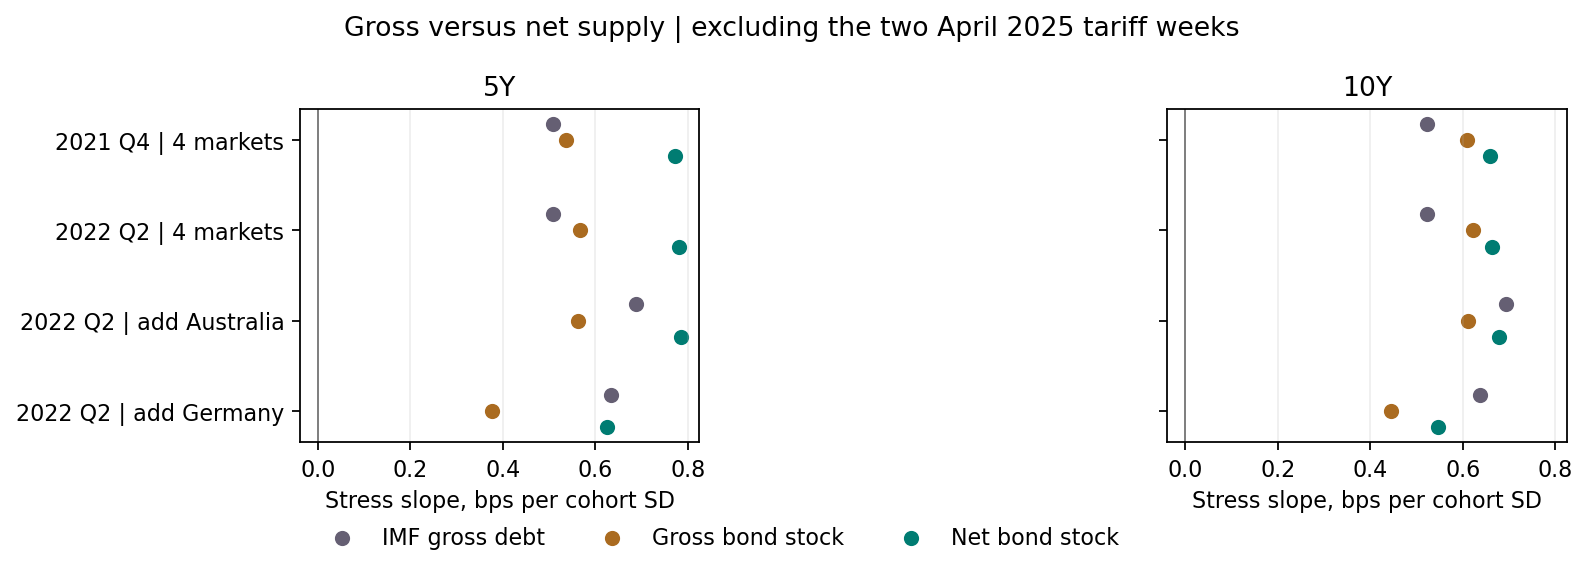

In [66]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
design_labels = {'2021Q4_four': '2021 Q4 | 4 markets', '2022Q2_four': '2022 Q2 | 4 markets',
                 '2022Q2_plus_AUD': '2022 Q2 | add Australia', '2022Q2_plus_AUD_DE': '2022 Q2 | add Germany'}
plot_data = supply_full.query("sample == 'ex_tariff'")
for ax, tenor in zip(axes, ['5y', '10y']):
    for field, label, color, offset in [
        ('imf_gross_pct_gdp', 'IMF gross debt', '#655F73', -0.18),
        ('gross_market_pct_gdp', 'Gross bond stock', '#AA6B20', 0),
        ('net_market_pct_gdp', 'Net bond stock', '#007C72', 0.18),
    ]:
        part = plot_data.query("tenor == @tenor and exposure == @field").set_index('design').loc[list(design_labels)]
        ax.scatter(part.bps_per_full_cohort_sd, [j + offset for j in range(len(design_labels))],
                   label=label, color=color, s=34)
    ax.axvline(0, color='0.45', linewidth=0.8)
    ax.set(yticks=range(len(design_labels)), yticklabels=list(design_labels.values()), title=tenor.upper(),
           xlabel='Stress slope, bps per cohort SD')
    ax.grid(axis='x', alpha=0.2)
axes[0].invert_yaxis()
axes[0].legend(loc='lower center', bbox_to_anchor=(1.05, -0.38), ncol=3, frameon=False)
fig.suptitle('Gross versus net supply | excluding the two April 2025 tariff weeks')
fig.tight_layout()
plot_path = FIGURE_DIR / 'stress_supply_gross_net_comparison.png'
fig.savefig(plot_path, dpi=160, bbox_inches='tight')
plt.close(fig)
display(Image(filename=str(plot_path)))


In [67]:
supply_net = supply_government.query("exposure == 'net_market_pct_gdp'")
display(supply_net.query("sample == 'ex_tariff' and omitted != 'none'")[
    ['design', 'tenor', 'omitted', 'bps_per_10pp', 'ci_low', 'ci_high']].round(3))
display(supply_net[supply_net['sample'].str.startswith('ex_episode_')].groupby(
    ['design', 'tenor']).bps_per_10pp.agg(['min', 'max', 'count']).round(3))
display(supply_advantage.query("sample == 'ex_tariff'").round(3))


,design,tenor,omitted,bps_per_10pp,ci_low,ci_high
128,2021Q4_four,10y,CAD,0.547,0.061,1.032
130,2021Q4_four,10y,GBP,0.544,-0.156,1.245
132,2021Q4_four,10y,NZD,0.604,-0.159,1.367
134,2021Q4_four,10y,SEK,0.076,-0.632,0.784
155,2021Q4_four,5y,CAD,0.642,0.328,0.957
157,2021Q4_four,5y,GBP,0.805,0.141,1.469
159,2021Q4_four,5y,NZD,0.591,0.262,0.919
161,2021Q4_four,5y,SEK,-0.141,-0.747,0.465
290,2022Q2_four,10y,CAD,0.535,0.060,1.009
292,2022Q2_four,10y,GBP,0.534,-0.135,1.203


min    max  count
design             tenor                     
2021Q4_four        10y    0.539  0.997     11
                   5y     0.630  0.965     11
2022Q2_four        10y    0.531  0.978     11
                   5y     0.625  0.954     11
2022Q2_plus_AUD    10y    0.606  1.046     11
                   5y     0.701  1.036     11
2022Q2_plus_AUD_DE 10y    0.523  0.990     11
                   5y     0.597  0.885     11

,design,tenor,sample,bps_net_minus_gross,ci_low,ci_high
1,2021Q4_four,10y,ex_tariff,0.050,-0.676,0.776
3,2021Q4_four,5y,ex_tariff,0.236,-0.339,0.811
5,2022Q2_four,10y,ex_tariff,0.041,-0.635,0.717
7,2022Q2_four,5y,ex_tariff,0.215,-0.318,0.748
9,2022Q2_plus_AUD,10y,ex_tariff,0.068,-0.536,0.671
11,2022Q2_plus_AUD,5y,ex_tariff,0.224,-0.249,0.697
13,2022Q2_plus_AUD_DE,10y,ex_tariff,0.101,-0.493,0.696
15,2022Q2_plus_AUD_DE,5y,ex_tariff,0.248,-0.239,0.735


### Result and stopping rule

- In the four-country 2021 Q4 design, excluding the tariff weeks, the 5Y/10Y slope is **+0.26/+0.30 bps per 10 GDP percentage points** for gross bonds and **+0.63/+0.54** for net bonds. After scaling by the cross-country standard deviation, the comparison is **+0.54/+0.61** versus **+0.77/+0.66 bps**. The 10Y gain in magnitude is small on the comparable scale.
- Moving to 2022 Q2 and adding Australia leaves the net slopes positive (**+0.70/+0.61** without tariff weeks); also adding Germany leaves **+0.60/+0.52**. Both signs survive dropping any one country in that six-market design, but some intervals cross zero. Dropping any one observed contiguous stress block from the full sample preserves both signs. The four-country 5Y result changes sign without Sweden (**about -0.14 bps** without tariff weeks); its 10Y result falls to **about +0.08**.
- The formal same-week comparison uses the **difference** of the two standardized slopes, including their covariance. All exploratory intervals cover zero. For the six-market sample without tariff weeks, the differences are **+0.25 bps [-0.24, +0.74]** at 5Y and **+0.10 bps [-0.49, +0.70]** at 10Y. This does not establish a stronger association after subtracting central-bank holdings.
- For the 2021 Q4 design without tariff weeks, the net association mainly loads onto **minus the foreign swap spread** (about **+0.64/+0.42 bps** per 10 points), not the benchmark-CIP component (about **-0.01/+0.12 bps**). The common U.S. term drops out of a cross-country slope by construction. This locates the association in the relative price; it does not identify a supply shock or demonstrate that net stock predicts better out of sample.

The net-stock signal is worth reporting as a sensitivity, **not as a standalone mechanism or the headline capstone claim**. Do not promote it to a point-in-time panel until scope-matched holdings and pre-event vintages are verified. Outstanding gaps are Danish and Swiss matched holdings, German federal-only holdings if that scope is required, and the historic vintages of holdings and GDP. [The authors' public release](https://cip.jesseschreger.com/data/2024q4) ends in June 2025 and does not resolve these exposure gaps. A dated static-vintage baseline with confirmed holdings and GDP is a useful intermediate step; a fully rolling historical-vintage model is not required to report the bounded diagnostic.


## 15J. Stationarity of Treasury Convenience

We test whether the monthly government-bond CIP deviation, measured in basis points, is consistent with a stable level, a deterministic trend, or stationary changes. The results inform the choice of transformation for later forecasting work.

The fixed eight-country panel has 45 consecutive monthly levels from January 2023 through September 2026 and 44 first differences. At each tenor, the basket is the equal-weight mean of the eight country values. ADF tests a unit root and KPSS tests stationarity around the chosen deterministic terms. We use an intercept for levels and first differences, and an intercept plus a linear trend for the trend specification. AIC selects the main ADF lag from zero to four months. KPSS uses automatic lag selection. Its reported endpoints are bounds.


In [68]:
from src.analyze_treasury_stationarity import basket_summary, stationarity_tests

stationarity_results = stationarity_tests()
display(basket_summary(stationarity_results).set_index("Equal-weight eight-country basket"))
trend_sensitivity = stationarity_results.query("market == 'basket' and lag_selection == 'fixed'")
display(trend_sensitivity.pivot(index="lag", columns="tenor", values="p_value")
        .round(4).rename_axis(index="Fixed trend ADF lag (months)", columns="Tenor"))


,Level ADF p,Level KPSS p,Trend ADF p,First difference
Equal-weight eight-country basket,,,,
5Y,0.589,≤0.01,0.829,"ADF p<0.001, KPSS p≥0.10"
10Y,0.402,≤0.01,0.0165,"ADF p<0.001, KPSS p≥0.10"


Tenor,10y,5y
Fixed trend ADF lag (months),,
0,0.2252,0.8290
1,0.0180,0.7557
2,0.1714,0.7839
3,0.0165,0.7649
4,0.0233,0.7505


At the 5% level, the level ADF fails to reject a unit root for both baskets and the level KPSS rejects stationarity around a fixed mean. After first differencing, the ADF rejects a unit root and the KPSS fails to reject stationarity for both tenors. The 10Y trend ADF has a p-value of 0.01646 (about 0.017 as originally reported), but the inference changes with the lag. The 45-month window limits what the tests can distinguish between a persistent series, a trend, and a changing regime.

These monthly diagnostics support testing first differences in a forecasting extension. Weekly forecasting requires checks at the weekly frequency. The [full stationarity table](../results/tables/treasury_stationarity_tests.csv) contains the basket and bilateral tests with statistics, p-value bounds, and lag settings. The [editable slides](../results/extensions.pptx) summarize the question, method, and result.


## 16. Current Findings

### Completed

- Public processed identity: `cip_govt = 100 * (diff_y - rho)`.
- Bloomberg workbook QC: `747` ticker blocks, `743` non-empty, `4` no-numeric.
- G10 5Y raw government CIP: `10/10 GOOD_MATCH`.
- Table 2-style G10 5Y summary statistics.
- Equation 6 first-pass identity check for G10 5Y/10Y: residual near zero.
- Eq.5 direct UST-convenience extension first pass with market controls and FRED supply proxies.
- Official Eq.5 extension panel with Treasury FiscalData marketable supply and NY Fed net-inventory proxies (not direct capacity).
- Eq.5 robustness checks for detrended levels, 12-month changes, post-2013 dealer samples, NY Fed series breaks, reporting-break dummies, and within-break diagnostics.
- Reviewed fixed-cohort interim results, reconciled nominal supply, additive rebound bridge, full-window break exclusion, calendar-aware HAC, and cohort/composition/COVID sensitivity.
- Foreign-spread raw-leg decomposition: all 16 pairs decline; alternative windows and one-country exclusions preserve the relative-convenience rebound. Mechanism remains untested.
- September 2026 refreshed accounting: 720 fixed-cohort country-tenor-months, 20/20 selected government-CIP checks, positive 5Y/10Y rebound under alternative baselines and endpoints. Section 15C is the controlling final evidence.
- Monthly stationarity diagnostics (Section 15J): level tests do not support stationarity around a fixed mean for either basket, while first differences are consistent with stationarity over the 45-month sample.
- Post-meeting measurement sensitivity: excluding NZD or NZD/DKK preserves the rebound. NZD metadata remains REVIEW; reassigning its tenor adjustment between components leaves Treasury convenience unchanged.
- Archived weekly VIX-only diagnostic through May 29, 2026: post-2023 relative-convenience betas remain negative. Sections 15E-15F supersede its missing-input status and qualify the risk interpretation.
- November 2 risk exports: all 12 series contain numeric data through September 30. Section 15E implements matched-sample equity/IG/HY tests through the week of September 25; the earlier missing-input status is superseded.
- HY adds only about 0.11/0.12 percentage points of recent in-sample R-squared and has HAC intervals covering zero. VIX point estimates stay negative but conditional significance is specification-sensitive.
- NZD terminal names resolve OIS versus 3M instrument identity. Raw bank/OIS gaps are not identical to tenor-basis quotes; pricing-convention reconciliation remains open and validated outcomes are unchanged.
- Table 5-style univariate 5Y/10Y comparisons now use paper-period windows through June 2025. Risk-loading directions agree, but exact aggregation, IG definition and vintage differences prevent an exact-replication claim.
- Joint post-2023 risk exposure is nonzero; slope-change inference is sensitive to HAC/cohort choices and the short latest-regime pre-period. Joint significance is not a recovered-safety test.
- A VIX-only 2010-2022 threshold defines recent stress weeks independently of Treasury outcomes. The 13 observed stress weeks have Treasury-convenience changes around -1.1 bps; stress-minus-ordinary differences around -1.24/-1.26 bps persist under the recorded bootstrap and excluding-NZD checks. This is association, not causality or an absolute-return finding.
- Country stress accounting reconciles exactly to that aggregate on the same dates. AUD, Germany/EUR and SEK have the largest negative pair contrasts, alongside a negative shared U.S. swap-spread term. One-country deletions retain negative point estimates, but 5Y excluding AUD loses conventional HAC significance; the pattern is heterogeneous and not a causal country ranking.
- Fixed-baseline sovereign-supply sensitivity: net-stock slopes are positive across four designs, including a six-market sensitivity, but four-country 5Y reverses without Sweden. The standardized net-minus-gross intervals all cover zero. Historical release vintages are not fully verified.

### Mostly completed

- Figure 3 long-tenor raw replication: `25/28 GOOD_MATCH`; JPY 20Y/30Y and NOK 1Y remain convention checks.
- G10 5Y/10Y benchmark CIP / Equation 1 first pass: public `rho` and `x_govt` checks pass, but direct benchmark-CIP reconciliation remains.
- Same-maturity Eq.5 supply/dealer diagnostics for 5Y and 10Y: useful first pass, not causal.

### Diagnostic only

- EM 5Y constructability and IRS+BS subset: useful for formula design, not final EM replication.

### Open

- Figure 3 3M FX forward / forward-point convention.
- EM NDS/CCS and country-specific formula rules.
- Paper-specific benchmark-CIP convention reconciliation beyond the first G10 5Y/10Y pass.
- Causal interpretation of supply/dealer results: persistence, common trends, reporting-break treatment, and identification remain open.
- Detailed NZD DES terms, confirmed credit-index units/definitions and the exact original-paper IG specification. The first-pass matched-sample credit-spread test is implemented, not pending download.


## 17. Reproduction and Remaining Research

1. Use Section 15C and `output/final/` for the bounded final descriptive presentation. Sections 15/15B preserve the reviewed May 2026 snapshots; Sections 1-12 remain the raw-replication evidence.
2. Reproduce the final result with `python -m src.refresh_treasury_5y10y`, then `python -m src.analyze_treasury_final`, or run the canonical notebook top to bottom. The local archived refresh workbook avoids dependence on a Downloads-folder path.
3. Reproduce the current risk extension with `python -m src.analyze_credit_risk_extension`, then `python -m src.analyze_risk_properties` and `python -m src.analyze_country_stress_attribution`. Sections 15E-15G use the archived November 2 inputs. Inspect the table-specification gaps, six-test joint family and two-test stress family before interpreting p-values. Country intervals/rankings are exploratory, not multiplicity-adjusted causal tests.
4. Do not call dealer inventory measured capacity. A capacity claim requires separate balance-sheet/regulatory/liquidity evidence and a defensible design.
5. The descriptive accounting, first-pass credit-risk extension and country stress attribution have the required numeric inputs. Audit the dominant AUD/EUR/SEK legs on the unchanged stress dates before adding a mechanism claim. Confirm NZD DES terms and credit-index/original-paper definitions when available, rather than downloading the same broad history again. Causal foreign supply/QT and supply-regression refreshes remain conditional later steps.
6. Keep direct benchmark-CIP reconciliation, 3M conventions, and EM rules as separate open tasks, not prerequisites for the bounded 5Y/10Y project.
7. Run `python -m src.build_research_notebook --execute` to rebuild and execute this notebook end to end, including both stress-supply screens. This uses archived inputs, not live Bloomberg or silently refreshed official vintages.
